In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams.update({'errorbar.capsize': 3})
plt.rcParams['xtick.labelsize']= 13
plt.rcParams['ytick.labelsize']= 13
plt.rcParams.update({'axes.labelsize': 16})

In [2]:
from astropy.time import Time
from astropy.table import  Table

In [3]:
from astropy import constants, units

c_kms=constants.c.value/10**3

In [4]:
import h5py
from astropy.io import ascii

In [5]:
import pickle

In [6]:
from lmfit import Model

In [7]:

def gaussian_w_slope(x, amp, cen, wid, bas,slope=0):
    "1-d gaussian: gaussian(x, amp, cen, wid,bas,slope)"
    return (amp/(np.sqrt(2*np.pi)*wid)) * np.exp(-(x-cen)**2 /(2*wid**2)) + bas+x*slope

In [8]:
def wl2vel(wl_arr,central_wl=None):
    '''returns vel in km/s
    
        inputs are wl_arr and central_wl'''
    if central_wl==None:
        central_wl=np.average(wl_arr)

    #print(c_kms)
    vel_arr=(wl_arr-central_wl)*c_kms/central_wl
    return vel_arr

In [9]:
#read coadds from coadds_outputs.h5 

data=h5py.File('coadds_outputs_2024.h5','r')

In [22]:
#find at which indices there are data for both NEID coadds and EXPRES coadds
neid_indices=[]
expres_indices=[]
overlap_mids=[]

for i,key in  enumerate(data['NEID']['coadds'].keys()):
    #check if there is data for that key in NEID that is not empty
    if data['NEID']['coadds'][key] is not None and len(data['NEID']['coadds'][key]) > 0:
        #print('NEID coadds found for key:', key)
        #check if that key is also in EXPRES coadds
        if key in data['EXPRES']['coadds'].keys():
            #check if there is data for that key in EXPRES that is not empty
            if data['EXPRES']['coadds'][key] is not None and len(data['EXPRES']['coadds'][key]) > 0:
                #print('EXPRES coadds found for key:', key)
                neid_indices.append(key)
                expres_indices.append(key)
                overlap = data['overlaps'][i]
                mid=(overlap[0]+overlap[1])/2
                overlap_mids.append(Time(mid,format='jd').isot)

In [11]:
data['NEID'].keys()

<KeysViewHDF5 ['coadds', 'date_sets', 'uncs', 'wls']>

In [12]:
#check neid_indices = expres_indices and that their length is the same as overlap_mids
if neid_indices == expres_indices and len(neid_indices) == len(overlap_mids):

    print('everything matches:', neid_indices)
else:
    print('NEID and EXPRES indices do not match')

everything matches: ['0000', '0001', '0002', '0003', '0004', '0005', '0006', '0007', '0008', '0009', '0010', '0011', '0012', '0013', '0014', '0015', '0016', '0017', '0018', '0019', '0020', '0021', '0023', '0024', '0025', '0026', '0027', '0028', '0029', '0030', '0031', '0032', '0033', '0034', '0035', '0036', '0037', '0038', '0039', '0040', '0041', '0042', '0043', '0044', '0045', '0046', '0047', '0048', '0049', '0050', '0051', '0052', '0053', '0054', '0055', '0056', '0057', '0058', '0059', '0060']


In [13]:
print(len(neid_indices), len(overlap_mids))

60 60


In [14]:
#read in csv file with line list
line_list_loc="../../RvLineList_allowBlends=0_overlapCutoff=5.0e-6_blend_RV_cutoff=2.0_depthCutoff=0.02_rejectTelluricSlope=2000.0_badLineFilter=none_quant=95_nbin=1_DP=true_binParam=depth_n=1_long_output=true_VACUUM.csv"

In [15]:
line_list=ascii.read(line_list_loc)

In [16]:
gmod=Model(gaussian_w_slope)

In [17]:
line_list

median_a,median_b,depth,median_σ²,lambda,std_a,std_b,std_depth,std_σ²,std_λc,line_id,frac_converged,bool_filter_min_frac_converged,bool_filter_median_depth_between_5percent_and_1,bool_filter_std_velocity_width_quant,bool_filter_std_local_continuum_slope_quant,bool_filter_neg_bad_line,bool_filter_nan_bad_line,bool_filter_rejectTelluricSlope,mean_template_var,species,excitation_energy,oscillator_strength,random,VALD_index,bool_filter_depth_cutoff,blend_number,bool_filter_allowBlends,bool_filter_blend_factors,bool_filter_iron1Only,bool_filter_badLineFilter,passed_all_bool_filters,weight
float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,float64,str4,str4,str4,str4,str4,str4,str4,float64,str6,float64,float64,float64,int64,str4,int64,str4,str4,str4,str4,str4,float64
1.390579184732739,-0.736072586417786,0.5150686662735857,0.0030234554953981075,3882.134036576609,0.02439298588736176,0.20423282963296344,0.01965792911191175,6.5379850964047366e-18,0.00011574880226041941,1,0.98,true,true,true,true,true,true,true,3.710046719196202e-05,'CN 1',0.4408,0.158,0.9798758118202728,33033,true,0,true,true,true,true,true,0.5150686662735857
1.4626195513611164,2.0,0.4626482900339974,0.0030243662221938394,3882.7272483847664,0.019833374917207196,0.007672694908955968,0.01443748436186155,1.7434626923745965e-18,0.0006491785020339457,3,0.99,true,true,true,true,true,true,true,3.564773193456217e-05,'CN 1',0.4014,0.138,0.15113742968704924,33074,true,0,true,true,true,true,true,0.4626482900339974
1.080508576002649,0.1397195269004936,0.29994065149636995,0.0009497331051758072,3884.7318502049066,0.02972422717267476,0.23898141525578726,0.01780264614315196,0.0001333542369734463,0.0009502448774235051,9,1.0,true,true,true,true,true,true,true,3.246203613563732e-05,'Cr 1',3.01,-0.599,0.39172948354773496,33307,true,0,true,true,true,true,true,0.29994065149636995
1.863776296921765,0.2643072533328039,0.8143328137705086,0.002030448740766423,3886.6115251666934,0.09596850898710192,0.1473562660555812,0.006841660425169698,0.00013218379606930224,0.00022699752539482516,14,1.0,true,true,true,true,true,true,true,2.6533833861963513e-05,'Fe 1',2.4242,-1.085,0.5255726323555064,33381,true,0,true,true,true,true,true,0.8143328137705086
1.262949730475054,-0.5452096008076086,0.4102918511992903,0.00090078658500036,3886.84777055226,0.06904214339493916,0.37289140709410873,0.02974329167646794,0.00015760911899441528,0.0009163318854588962,15,1.0,true,true,true,true,true,true,true,2.471094958998301e-05,'Fe 1',3.2657,-1.293,0.5215974726374468,33390,true,0,true,true,true,true,true,0.4102918511992903
1.3293268255814517,-0.7740967357370896,0.5368364403682011,0.000984484901598761,3887.8962318114072,0.043662121339747,0.2520133494325407,0.014896529232831301,8.953489630896986e-05,0.00048278510033959894,16,1.0,true,true,true,true,true,true,true,1.966537156689862e-05,'Cr 1',1.0037,-1.37,0.01912161666492629,33426,true,0,true,true,true,true,true,0.5368364403682011
2.1635697865732184,0.2685066022753484,0.8508276156364669,0.004458197631188673,3888.152342013541,0.12692224023212992,0.18163515915575534,0.0071796954527459204,0.00032741801907894925,0.00037184395643818474,17,1.0,true,true,true,true,true,true,true,2.024679331386678e-05,'Fe 1',0.9146,-1.144,0.8626210645618242,33436,true,0,true,true,true,true,true,0.8508276156364669
1.4981018441580132,1.79549506707687,0.7848770984491065,0.003035105759696383,3889.6170975366504,0.04022393090592791,0.20932390837985476,0.0019021460522598715,1.3075970192809475e-18,0.0008777396497513403,18,1.0,true,true,true,true,true,true,true,1.6549513719364787e-05,'Fe 1',1.6079,-0.548,0.885453401184154,33480,true,0,true,true,true,true,true,0.7848770984491065
1.396534590550099,-0.7935461514660569,0.7175433190929252,0.0012598659674836529,3891.940572510654,0.05335205353984595,0.1456570187272362,0.005989275701351141,5.1134490635896625e-05,0.0001917519518226411,26,1.0,true,true,true,true,true,true,true,1.8560433676389046e-05,'Fe 1',2.7275,-1.313,0.30295011059313

In [18]:


def fit_lines(w,s,e,line_list,plot=False,wl_min=6000,wl_max=6030,fit_range=0.7,dist_from_edge=500,plotbad=False,detrend=True):
    line_fits=[]
    '''fits lines in line_list to the spectrum s with wavelengths w
    
        inputs are:
            w: 2D array of wavelengths (orders x pixels)
            s: 2D array of spectrum (orders x pixels)
            line_list: astropy table with columns 'lambda' and 'depth'
    '''
    for i,l in enumerate(line_list['lambda'].value):
        if l<wl_max and l>wl_min:
            #print(l,line_list['depth'][i])
            #find all the orders that contain this wavelength, and the line is more than 500 pixels from the edge of the order  
            orders_with_line=[] 

            for o in range(w.shape[0]):
                if l>w[o].min()+dist_from_edge*(w[o][1]-w[o][0]) and l<w[o].max()-dist_from_edge*(w[o][1]-w[o][0]):
                    orders_with_line.append(o)
            #print("orders with line:",orders_with_line)
            #for each order, convert the wavelength to velocity, centered on the line wavelength and then fit a guassian to the spectrum
            #only fit within 2 angstroms of the line center
            for o in orders_with_line: 
                wl_order=w[o]
                s_order=s[o]
                e_order=s[o]
                vel_order=wl2vel(wl_order,central_wl=l)
                #select only the points within 1 angstroms of the line center and the spectrum is not NaN
                mask=(wl_order>l-fit_range)&(wl_order<l+fit_range)&(~np.isnan(s_order))
                wl_fit=wl_order[mask]
                s_fit=s_order[mask]
                vel_fit=vel_order[mask]
                e_fit=e_order[mask]
                weights_fit=1/e_fit**2
                #save the pixel index of the line center
                line_center_index=np.argmin(np.abs(wl_order-l))
                #initial guess for the gaussian parameters
                amp_init=line_list['depth'][i]*np.sum(s_fit)*-1
                cen_init=0
                wid_init=3.0
                bas_init=np.median(s_fit)
                slope_init=0
                params=gmod.make_params(amp=dict(value=amp_init,max=0),cen=dict(value=cen_init,min=-2,max=2),wid=dict(value=wid_init,min=0),bas=bas_init,slope=slope_init)
                #fit the gaussian to the data
                try:
                    result0=gmod.fit(s_fit,params,x=vel_fit,weights=weights_fit)
                    #now refit after dividing by the best fit baseline + slope
                    if detrend:
                        s_fit_detrended=s_fit/(result0.params['bas'].value+vel_fit*result0.params['slope'].value)
                        e_fit_detrended=e_fit/(result0.params['bas'].value+vel_fit*result0.params['slope'].value)
                        weights_fit_detrended=1/e_fit_detrended**2
                        
                        params=gmod.make_params(amp=dict(value=amp_init,max=0),cen=dict(value=cen_init,min=-2,max=2),wid=dict(value=result0.params['wid'].value,min=0),bas=0,slope=0)
                        result=gmod.fit(s_fit_detrended,params,x=vel_fit,weights=weights_fit)
                    else:
                        result=result0
                    
                except:
                    print(f"Fit failed for line at {l} Angstroms in order {o}")
                    #print(wl_fit)
                    #print(s_fit)
                    continue               
                #print(result.fit_report())
                if plot:
                    #plot the data and the fit
                    plt.figure()
                    plt.plot(vel_fit,s_fit_detrended,label='data')
                    plt.plot(vel_fit,result.best_fit,label='fit')
                    plt.xlabel('Velocity (km/s)')
                    plt.ylabel('Flux')
                    plt.title(f'Order {o} Line at {l} Angstroms')
                    plt.legend()
                    plt.show()
                if plotbad:
                    if result.rsquared<0.8:
                        plt.figure()
                        plt.plot(vel_fit,s_fit_detrended,label='data')
                        plt.plot(vel_fit,result.best_fit,label='fit')
                        plt.xlabel('Velocity (km/s)')
                        plt.ylabel('Flux')
                        plt.title(f'Order {o} Line at {l} Angstroms')
                        plt.legend()
                        plt.show()
                        
                
                

                
                #save the fit results to a list
                line_fits.append({'line_wl':l,'order':o,'amp':result.params['amp'].value,'amp_err':result.params['amp'].stderr,    
                                  'cen':result.params['cen'].value,
                                  'cen_err':result.params['cen'].stderr,
                                  'wid':result.params['wid'].value,
                                  'wid_err':result.params['wid'].stderr,
                                  'bas':result.params['bas'].value,
                                  'bas_err':result.params['bas'].stderr,
                                  'slope':result.params['slope'].value,'chi2':result.chisqr,
                                  'bic':result.bic,'r':result.rsquared,
                                  'line_center_index':line_center_index,
                                  'line_depth':line_list['depth'][i]})
    
    return line_fits
            

In [19]:
dist_from_edge=500

In [20]:
line_list['lambda'].value

array([3882.13403658, 3882.72724838, 3884.7318502 , ..., 9802.98268077,
       9864.427174  , 9891.73905874])

Fitting 1502 lines for index 0000 between 3796.7 and 8223.6 Angstroms
Now fitting for NEID...


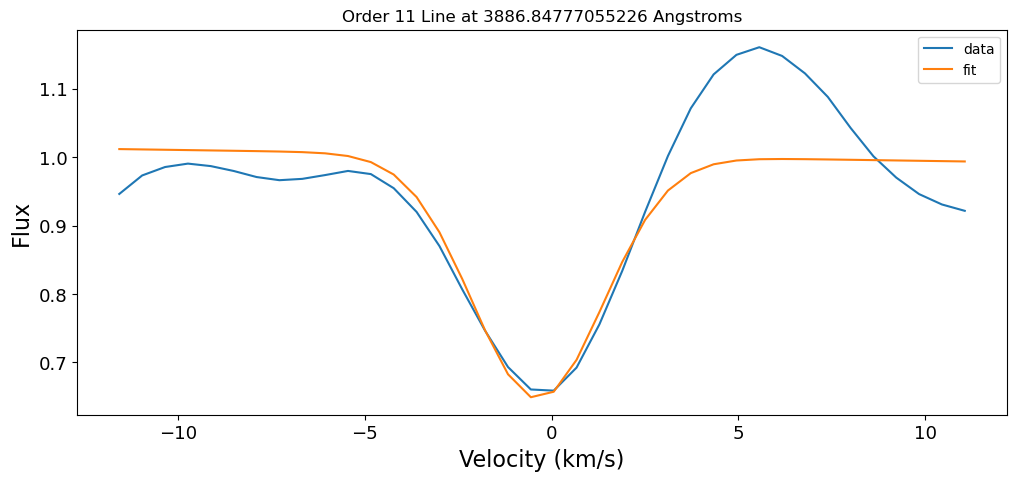

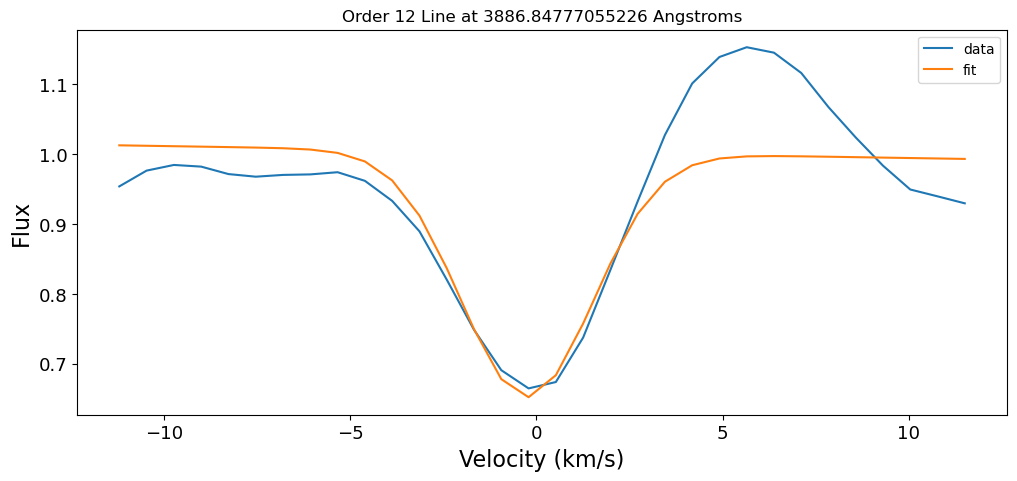

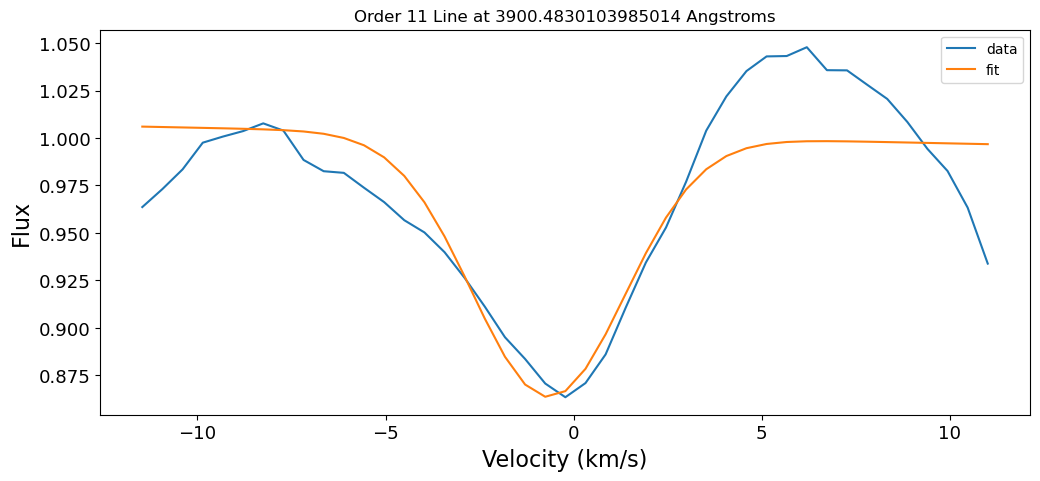

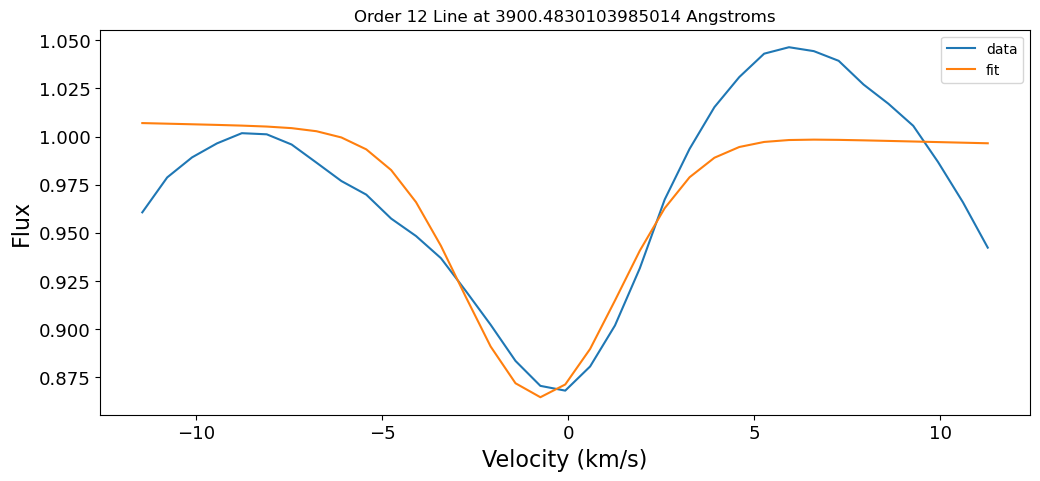

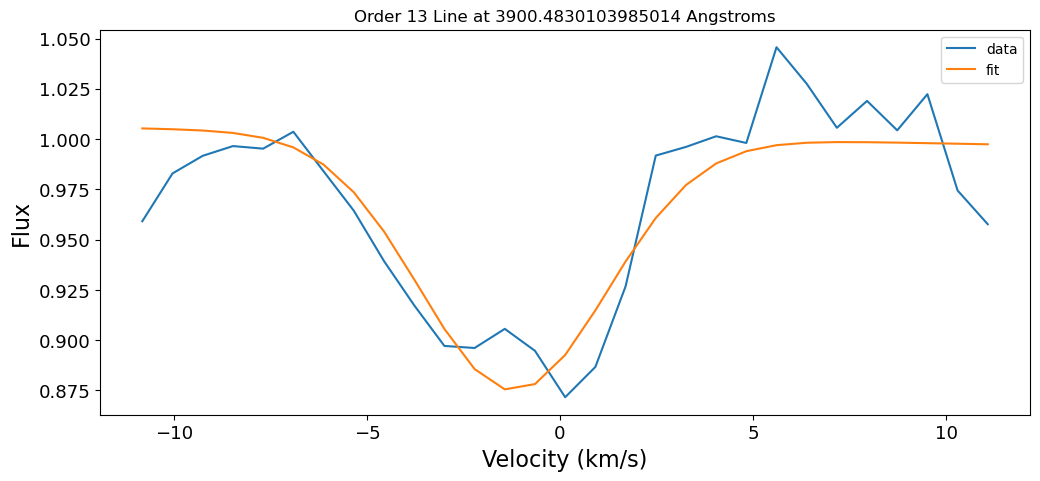

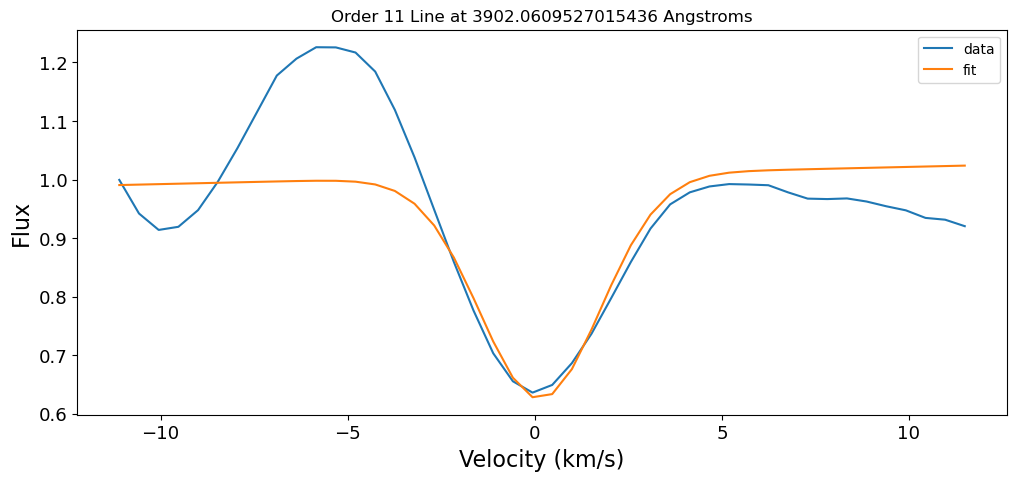

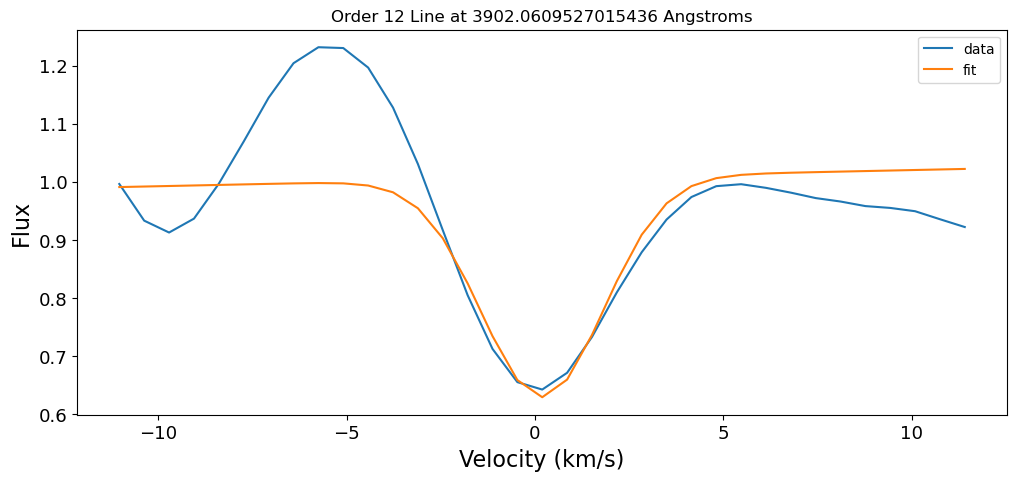

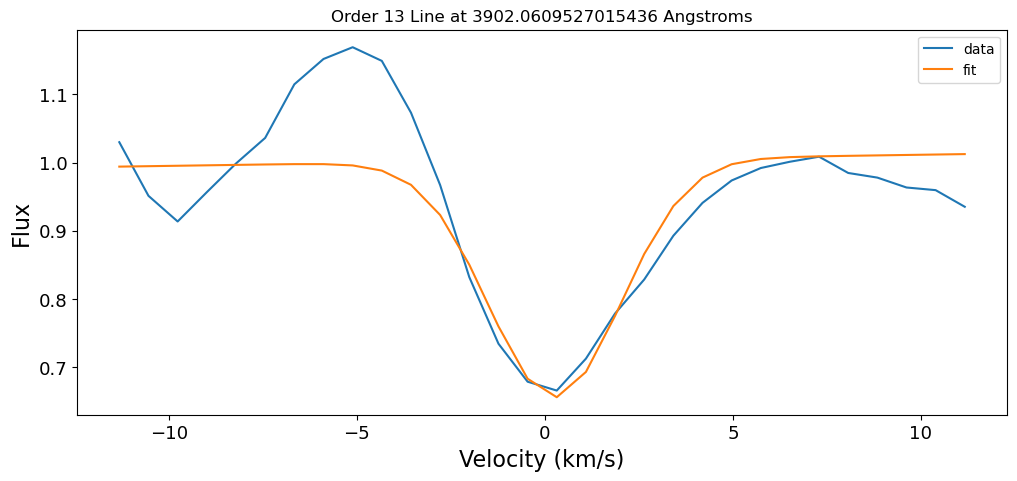

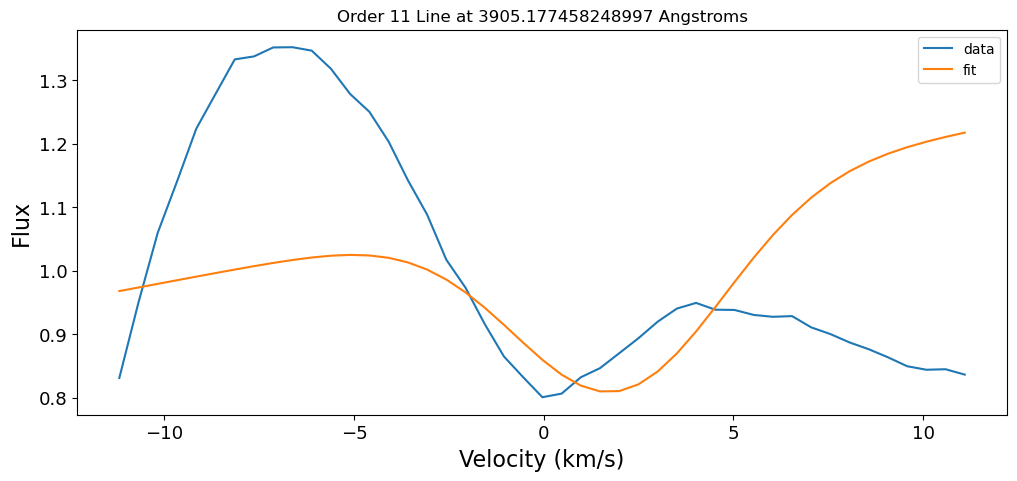

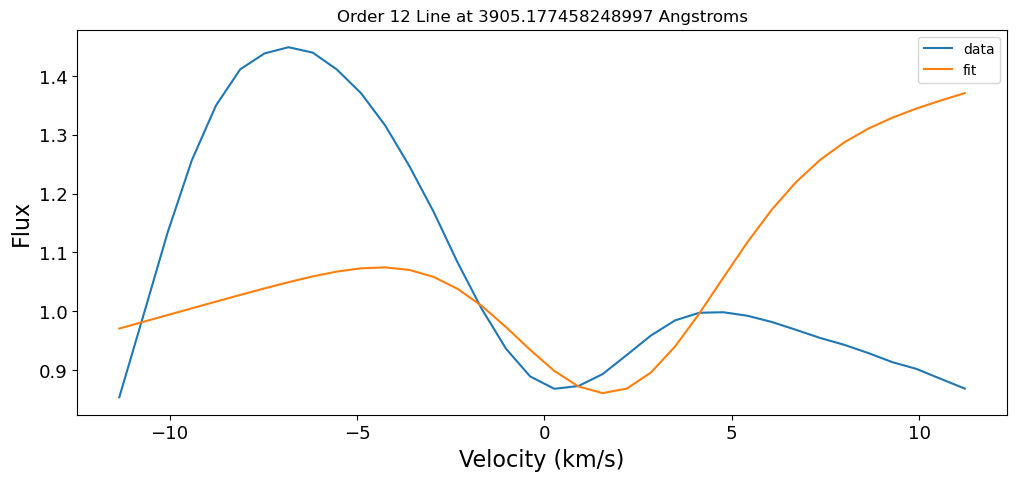

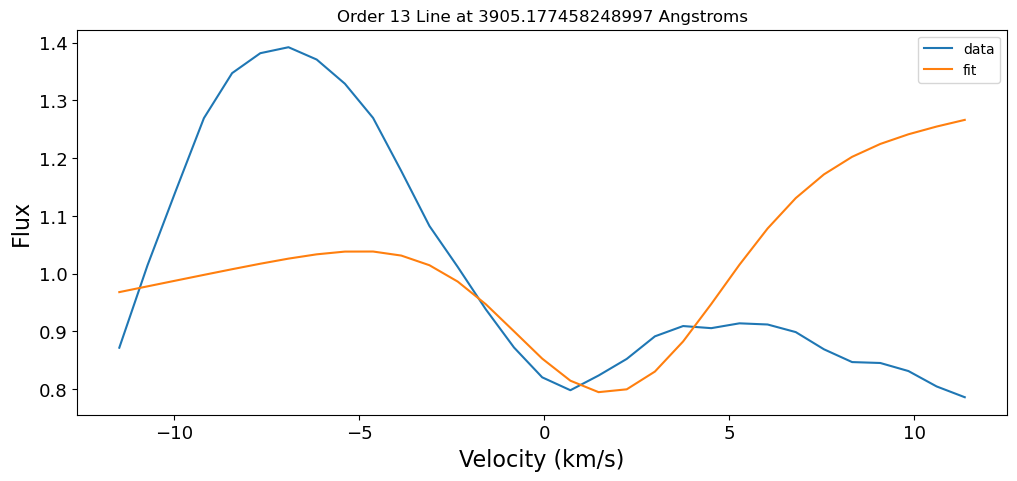

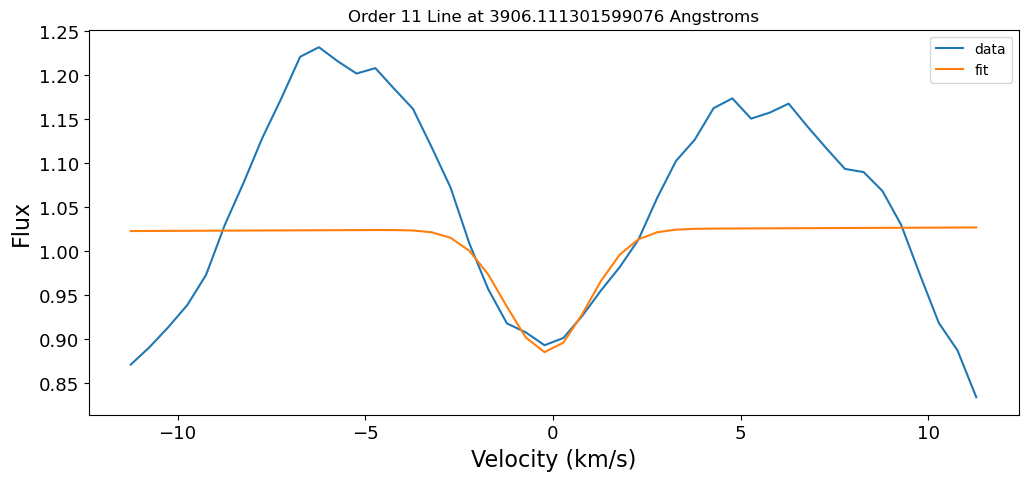

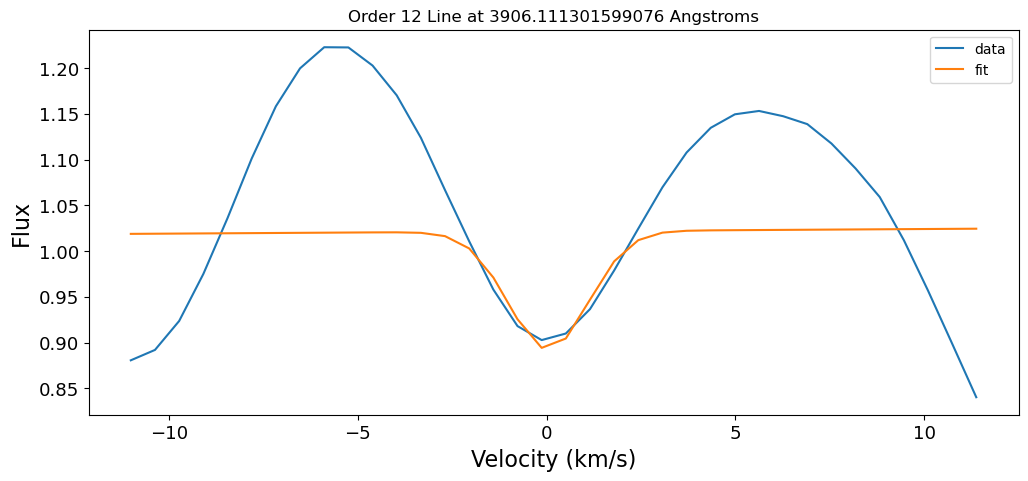

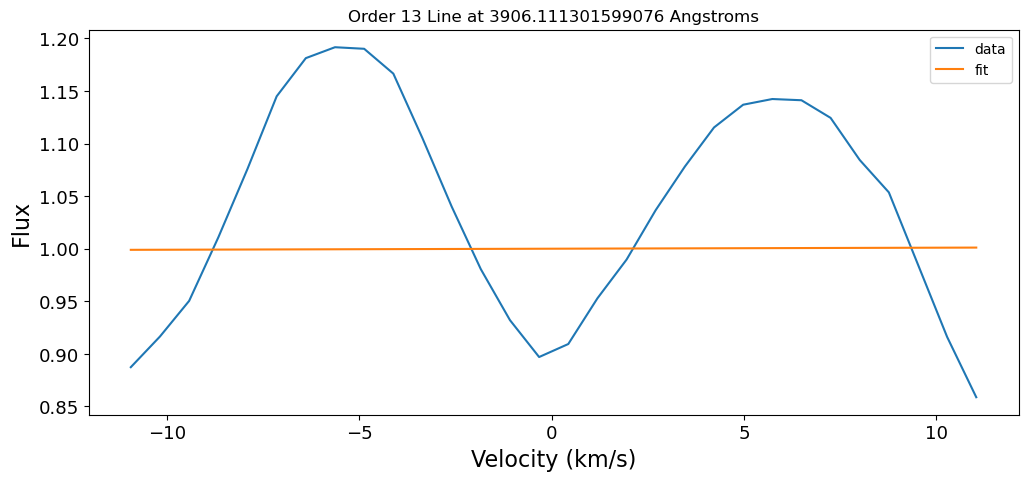

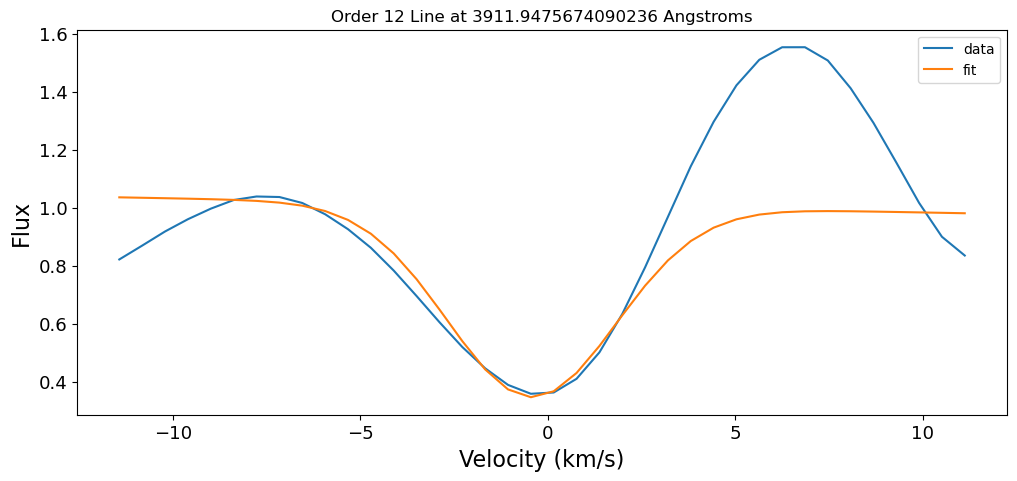

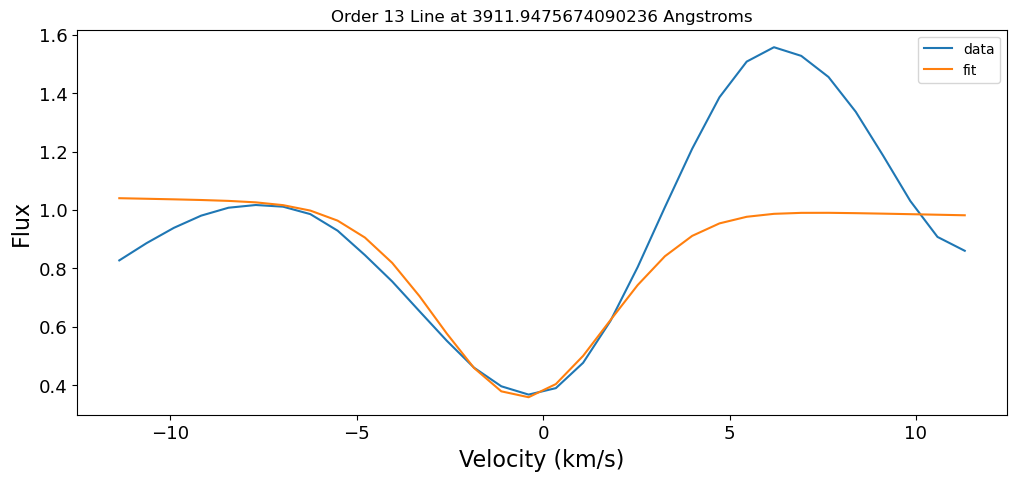

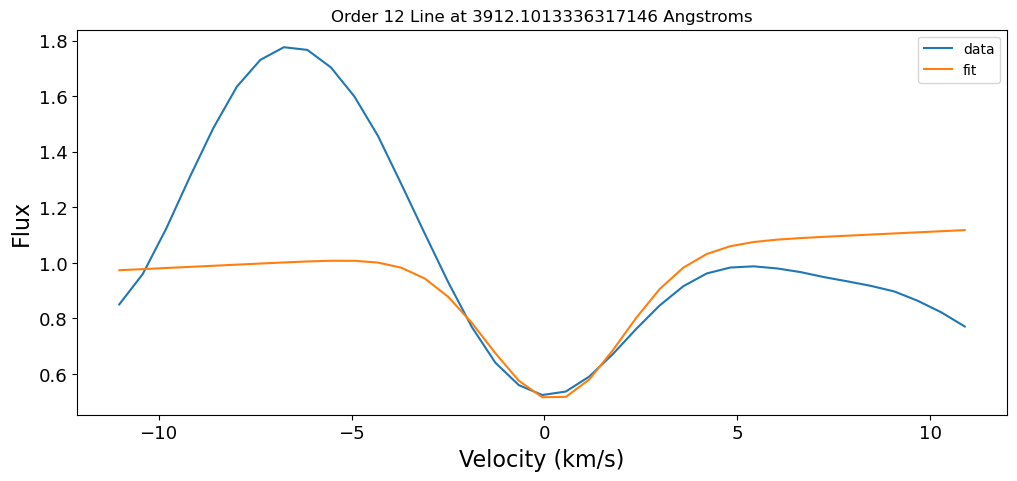

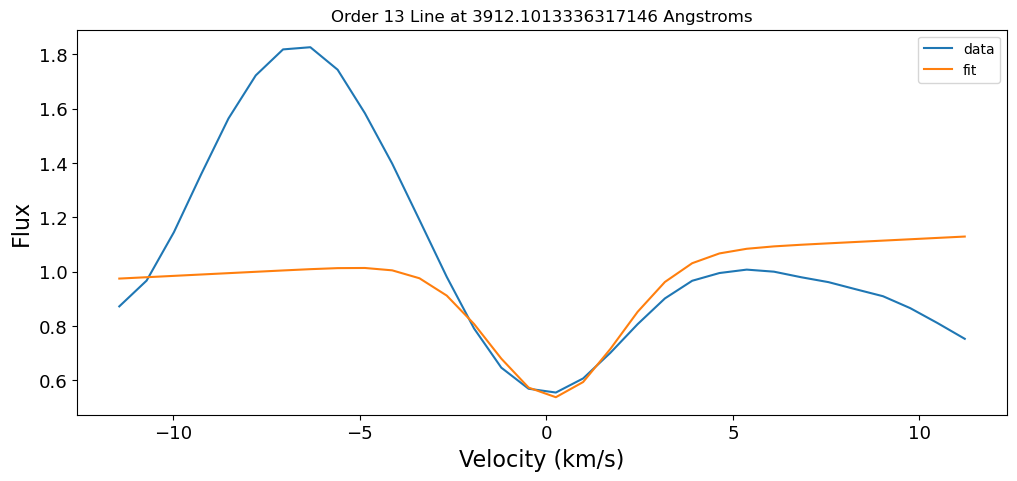

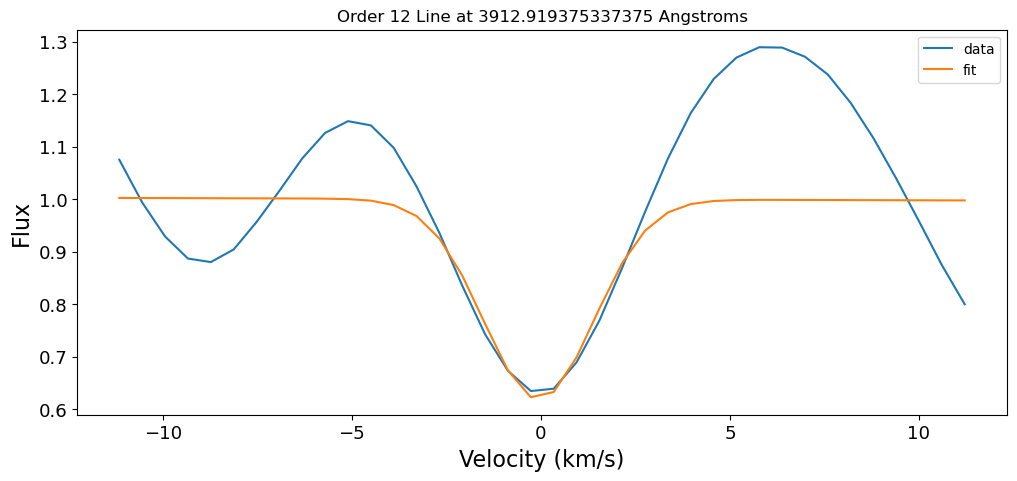

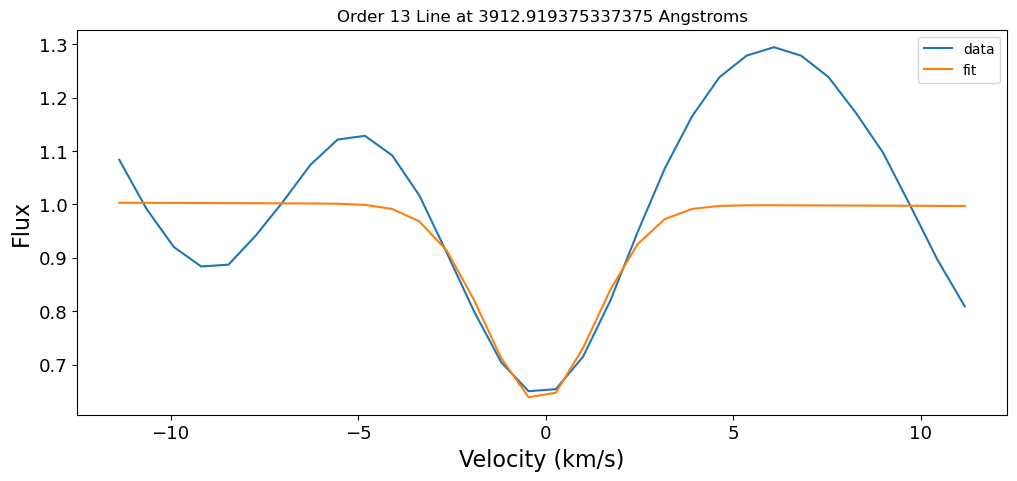

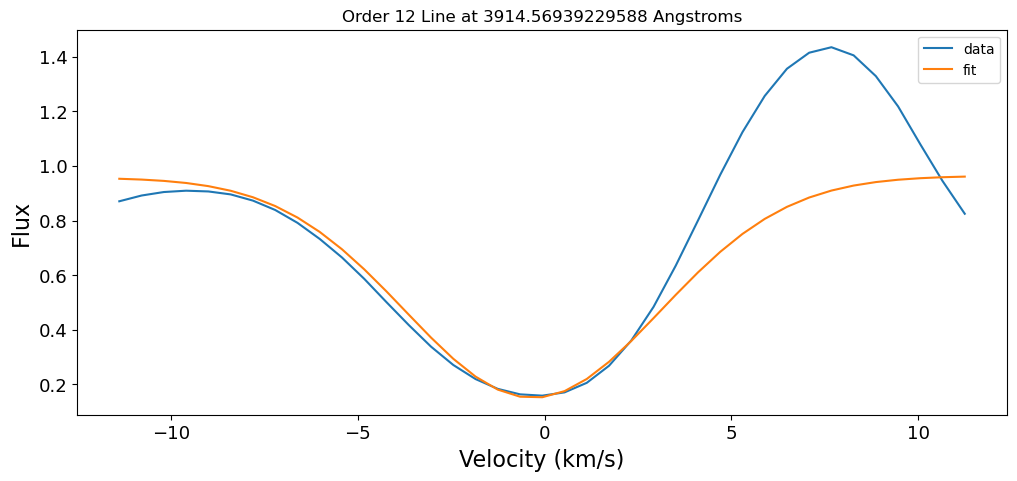

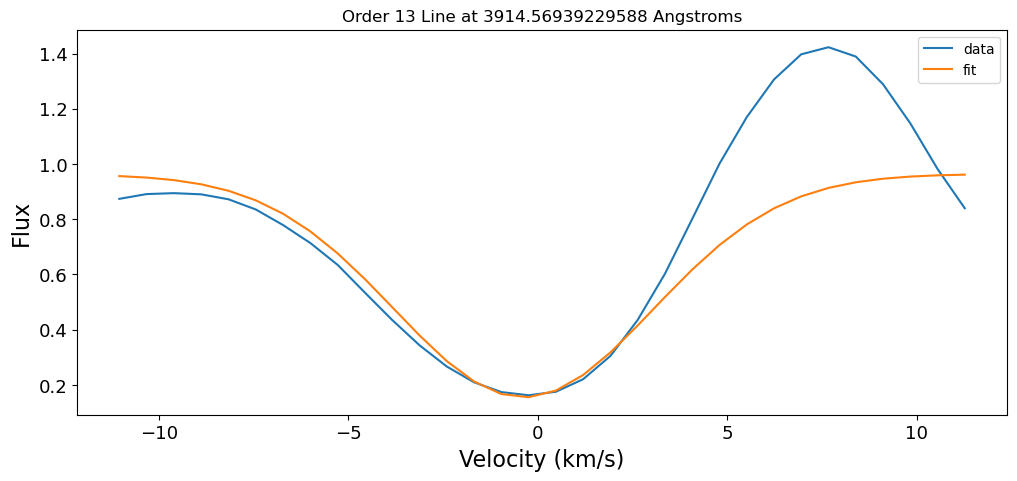

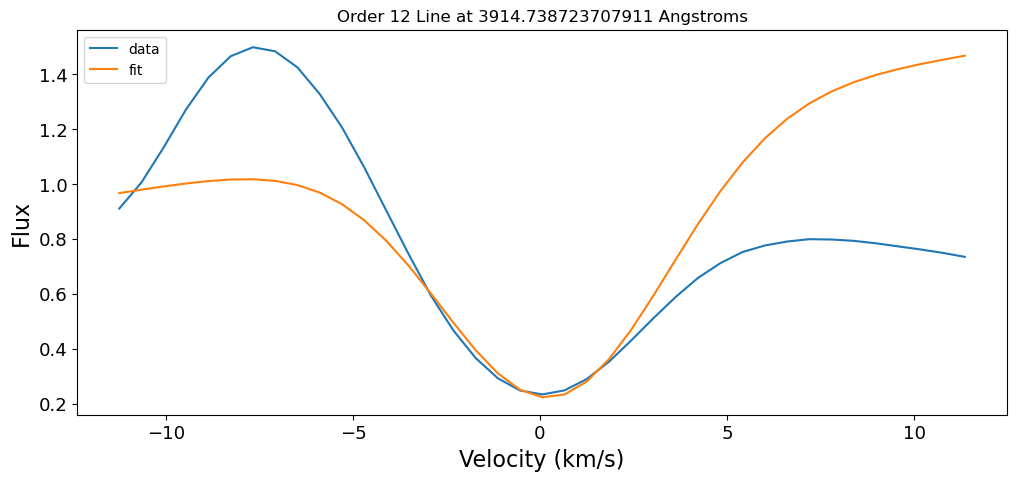

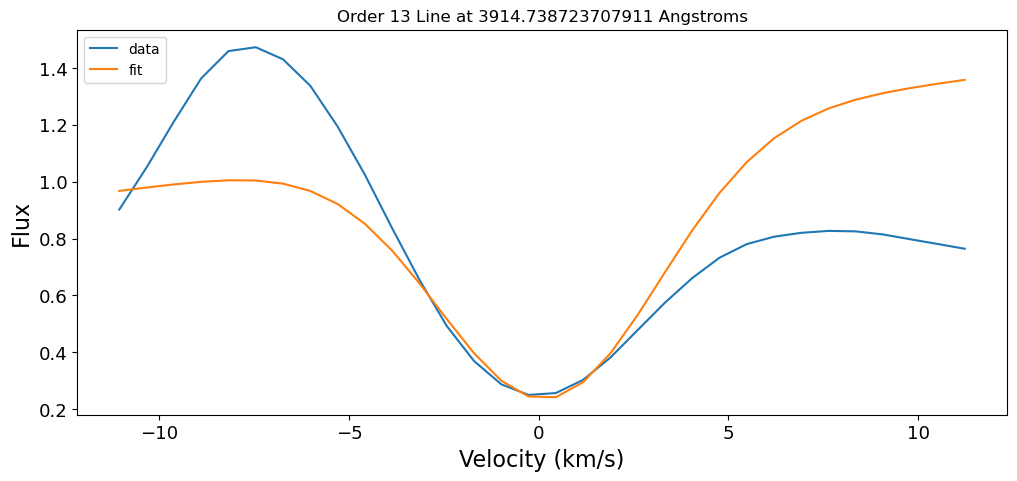

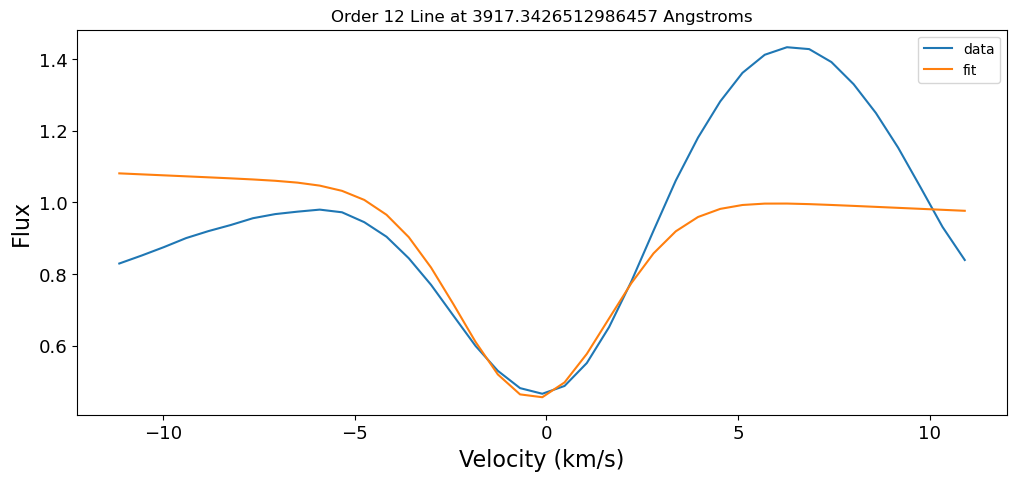

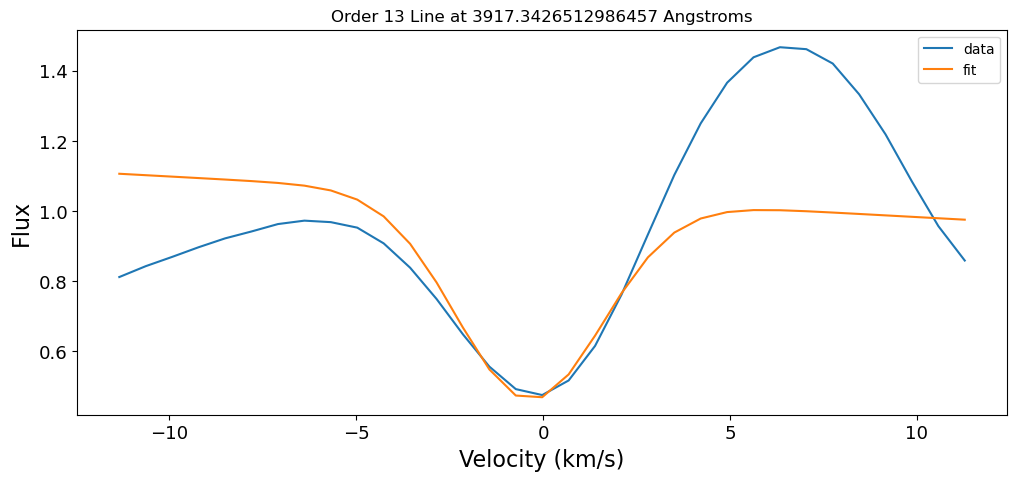

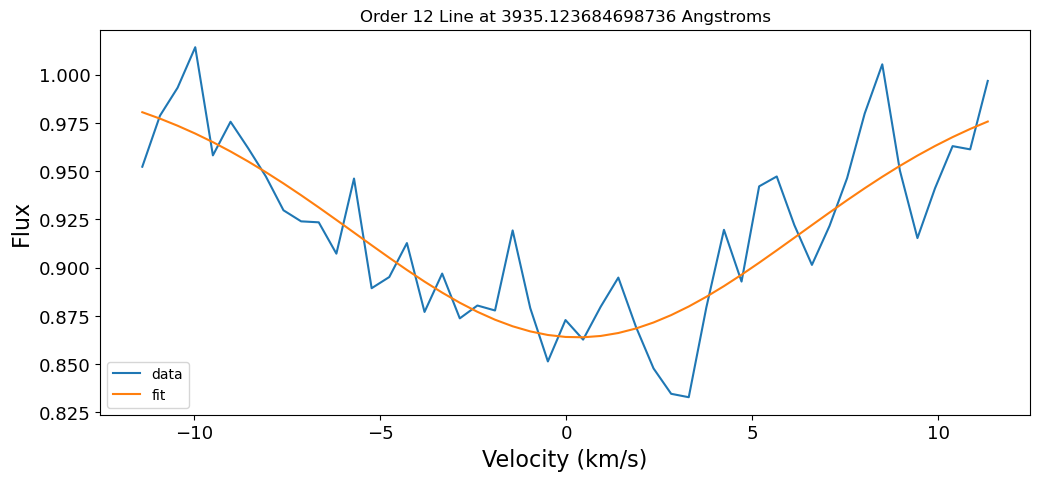

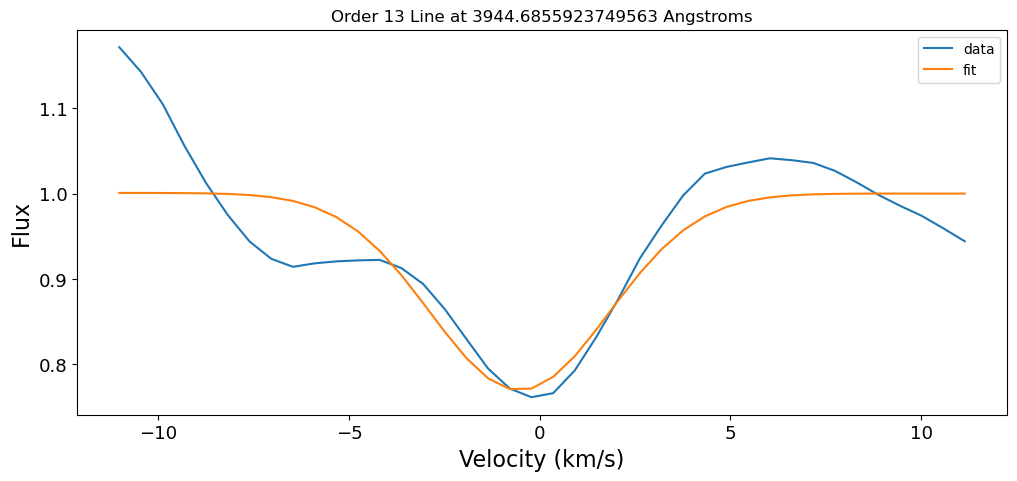

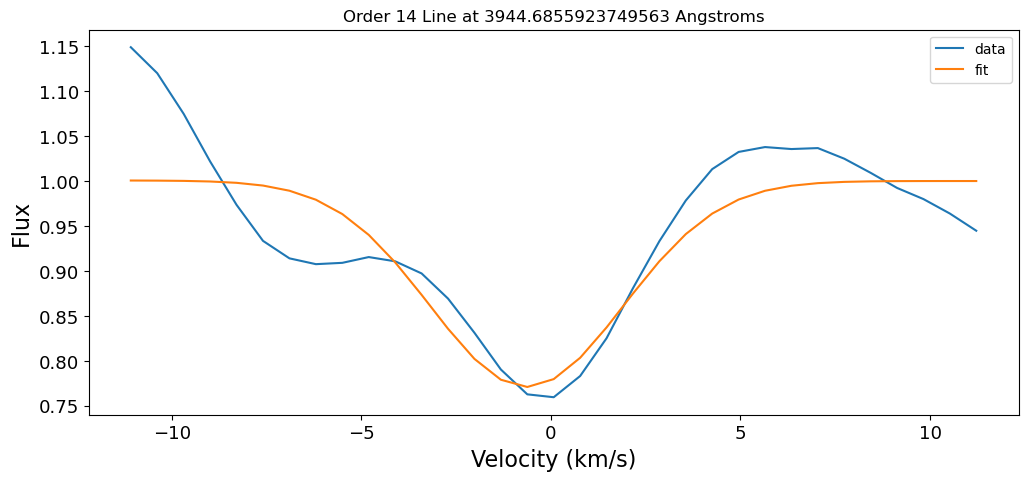

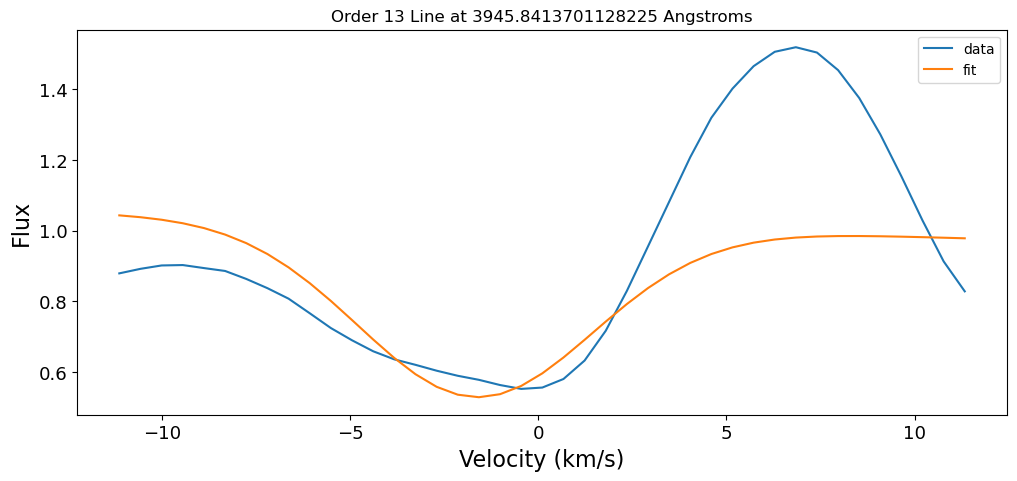

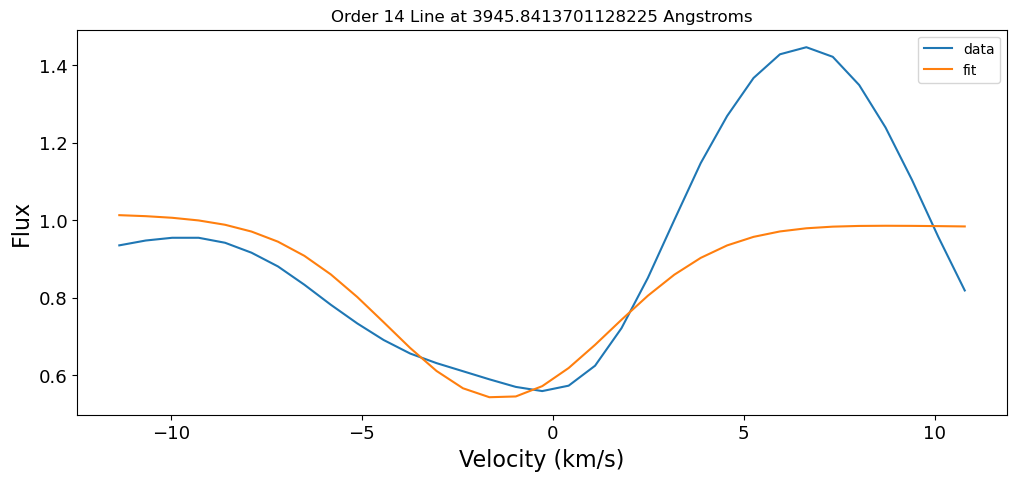

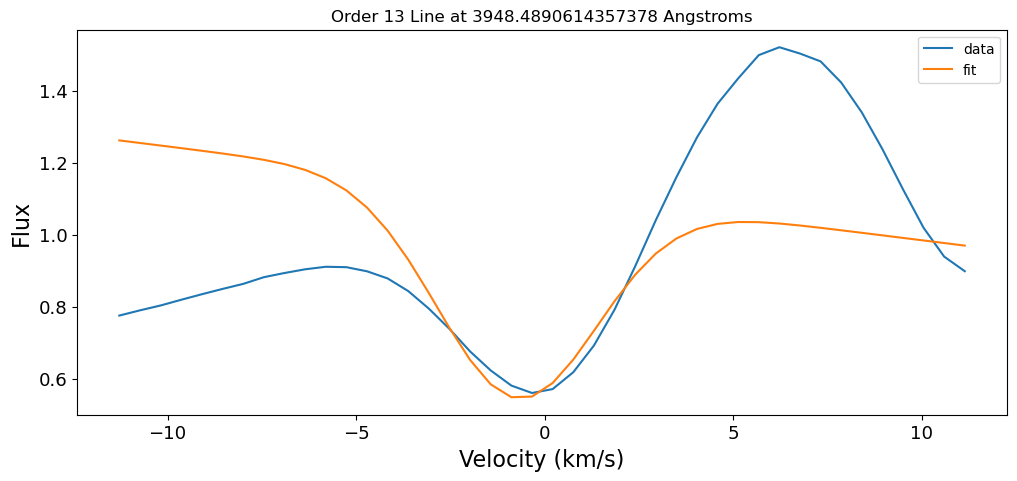

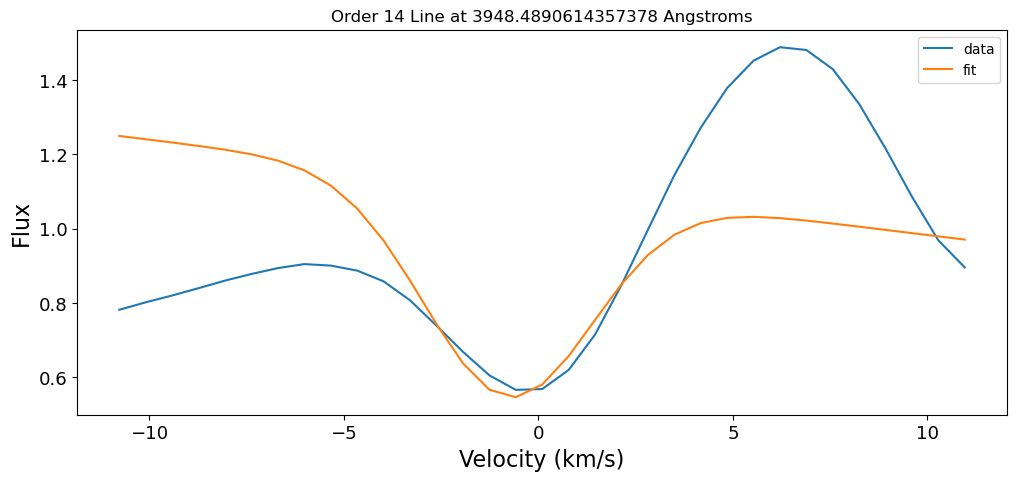

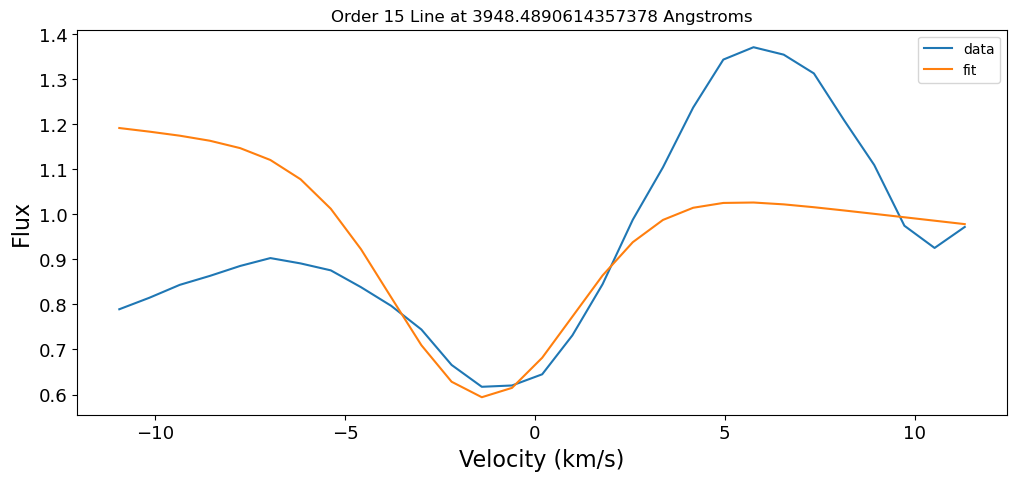

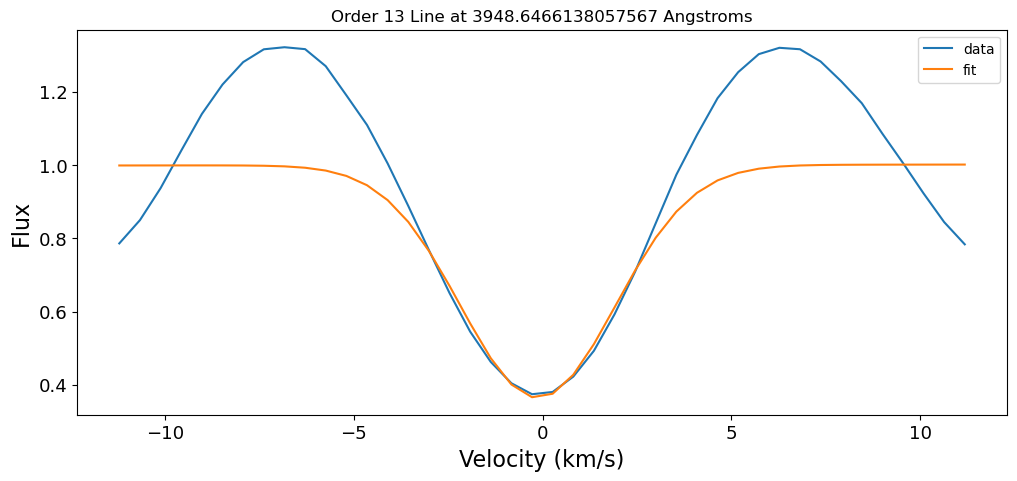

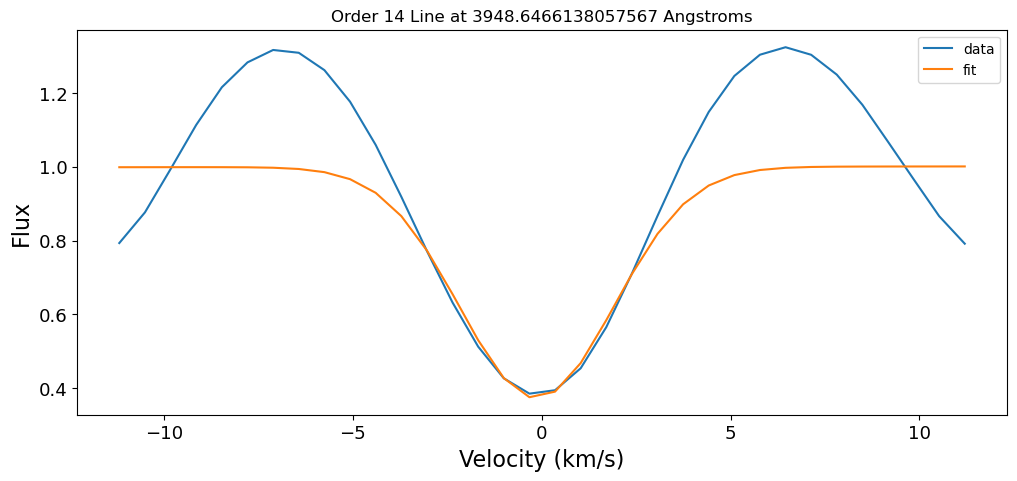

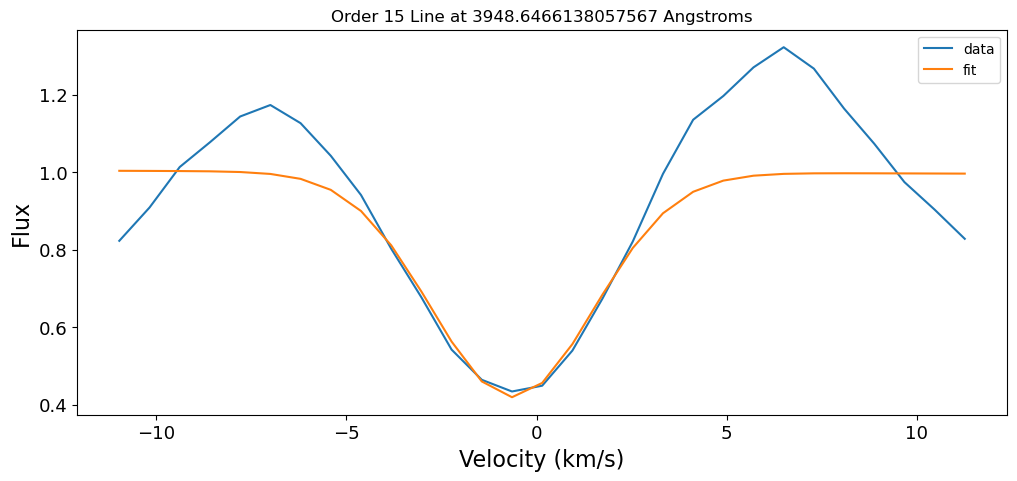

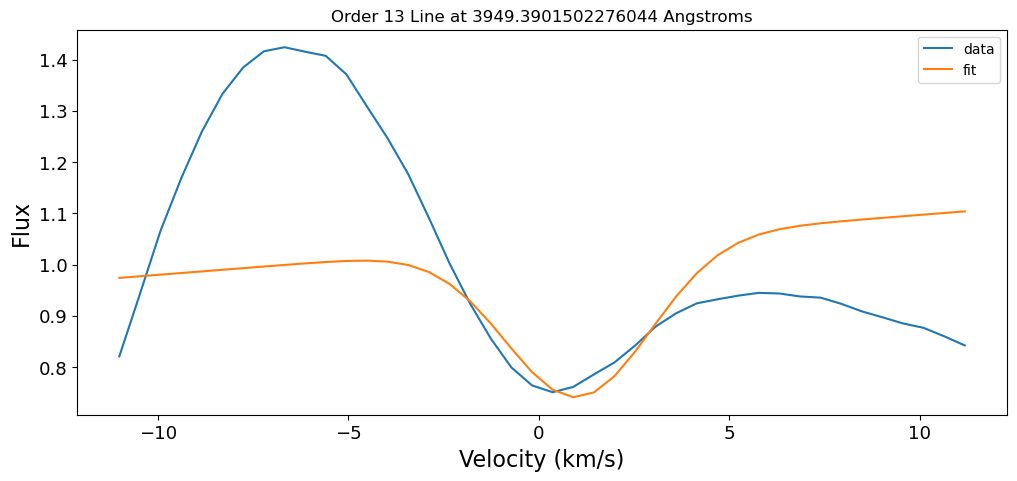

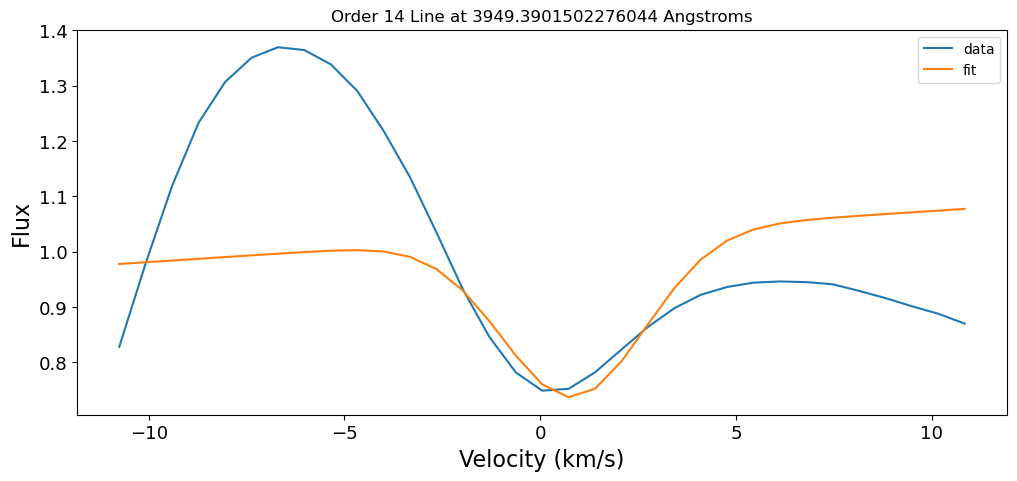

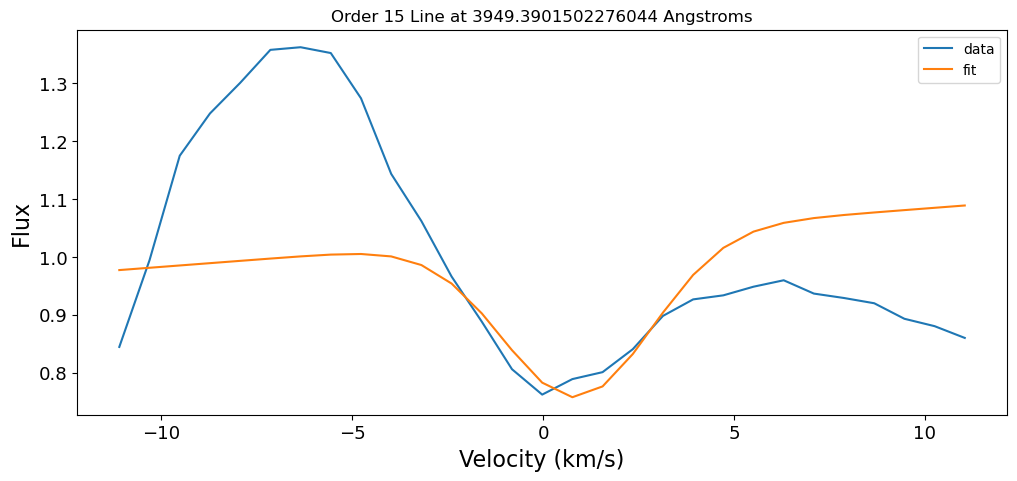

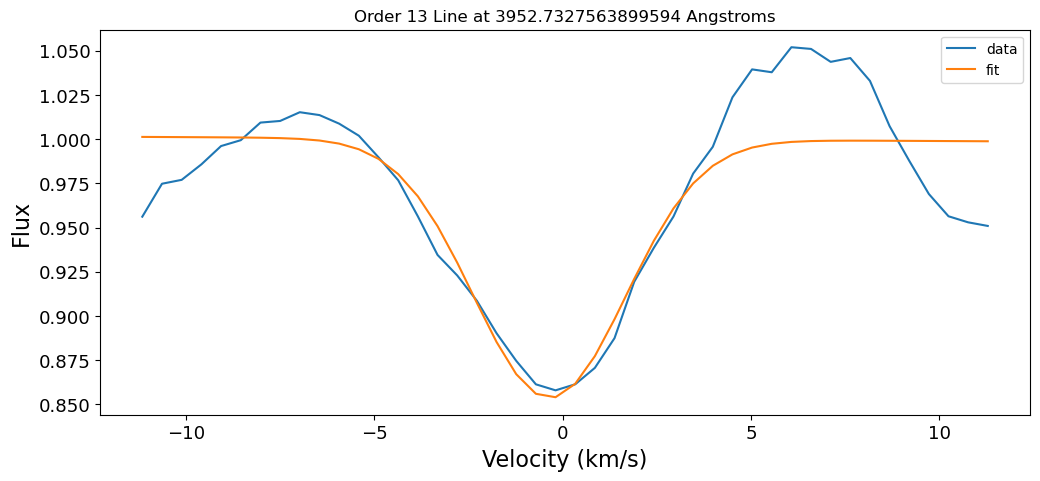

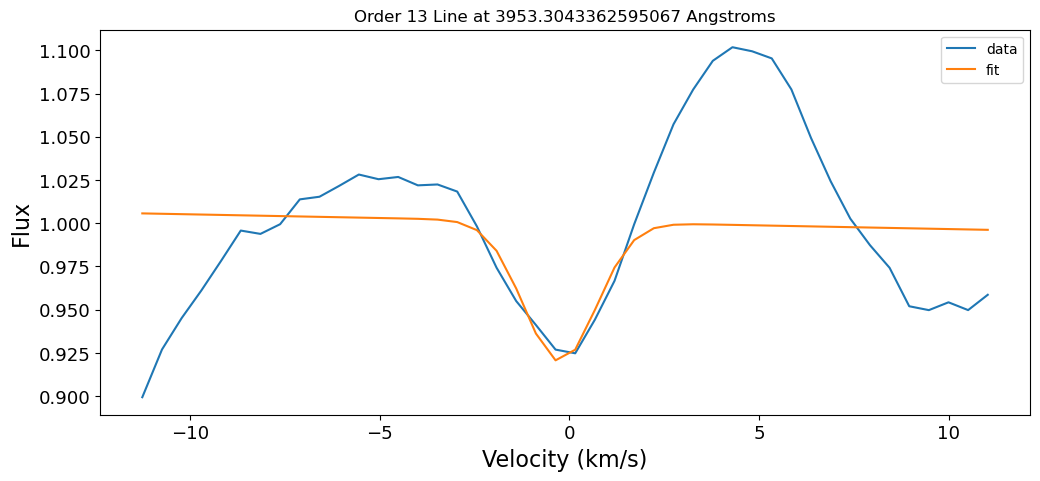

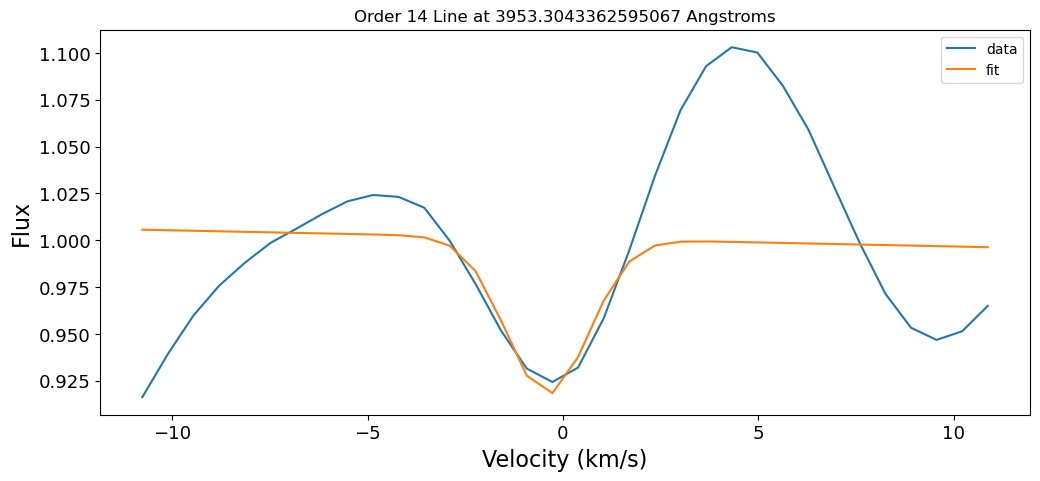

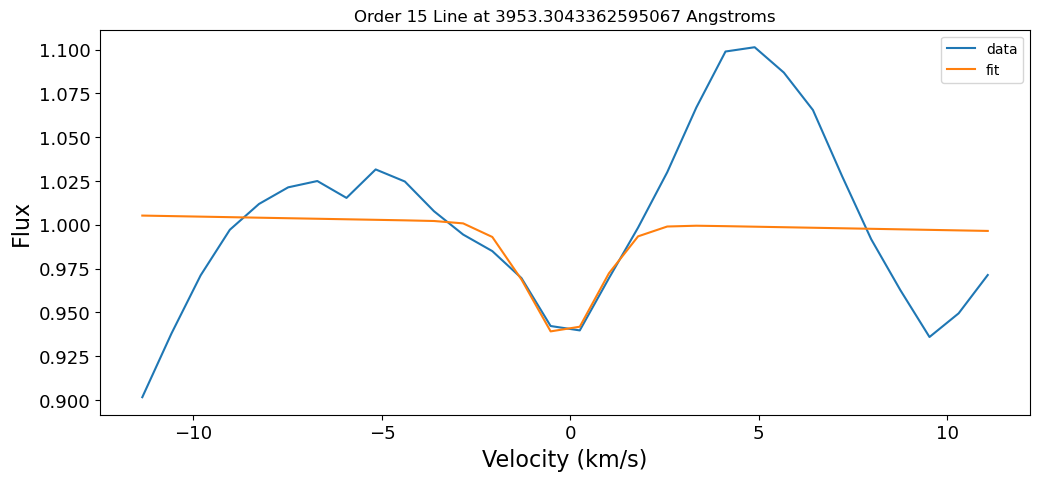

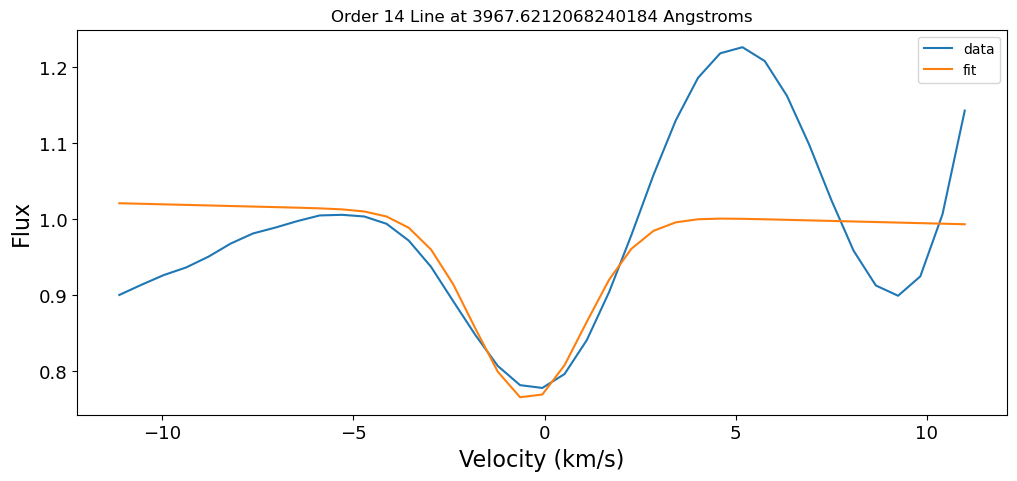

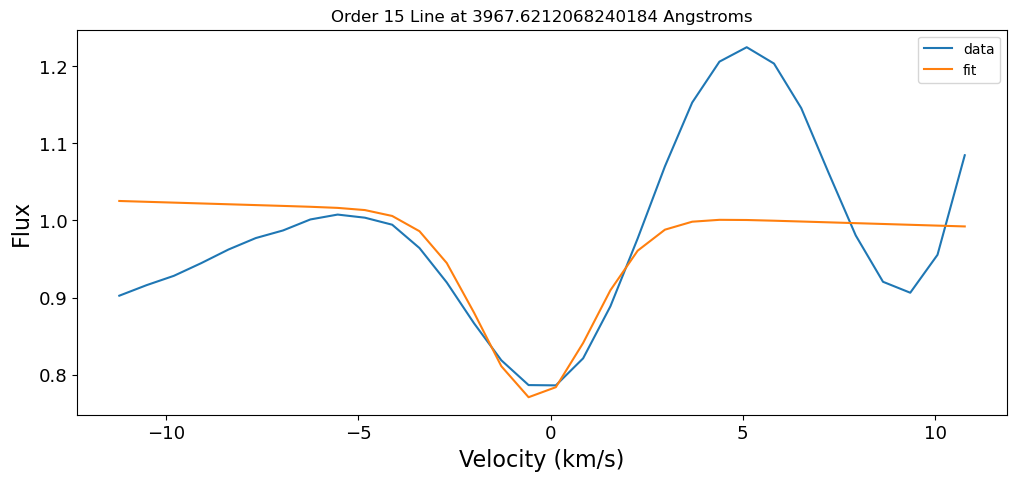

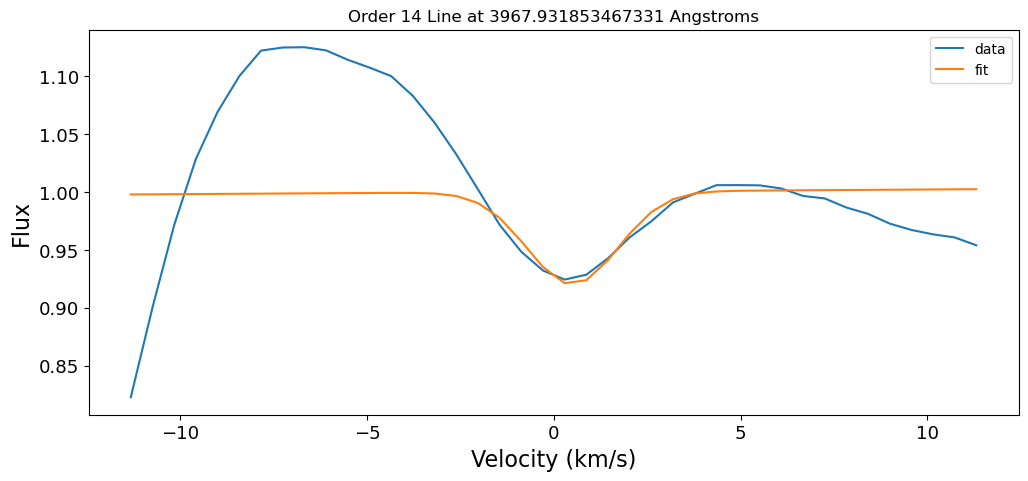

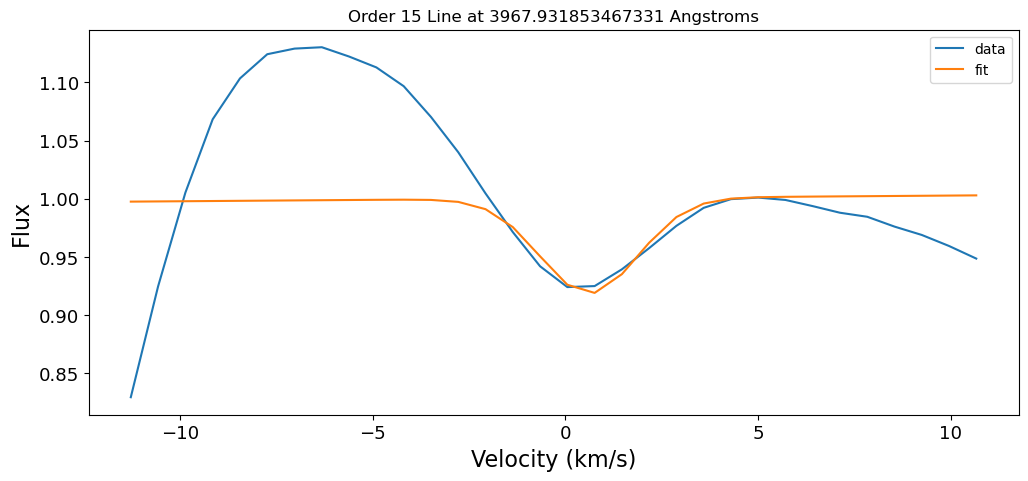

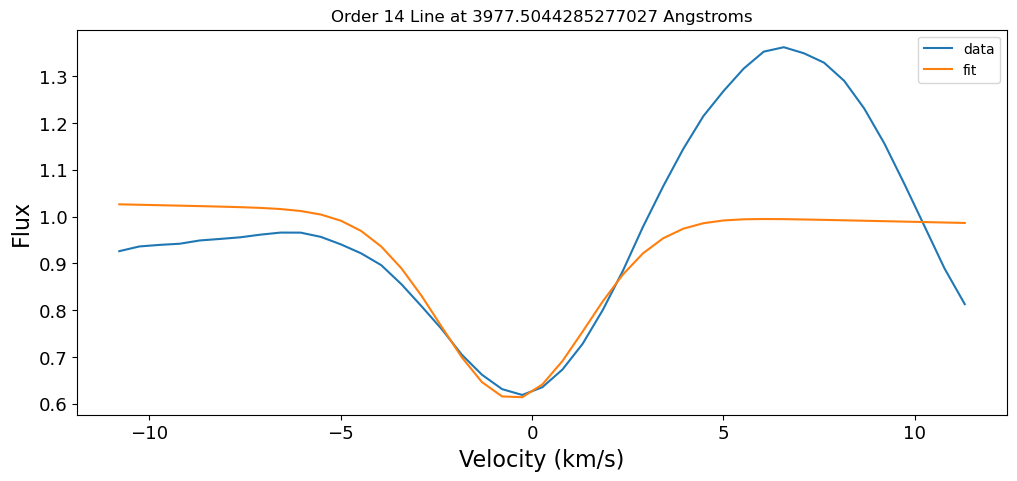

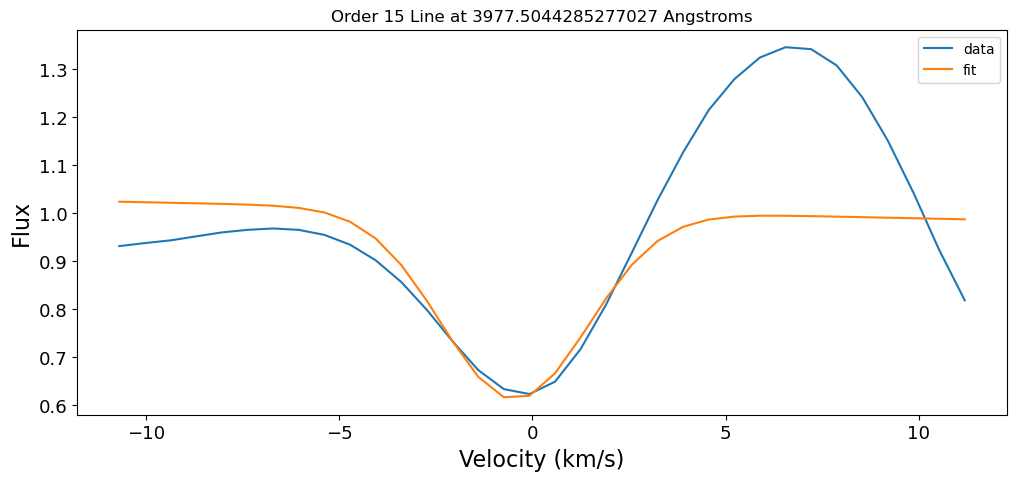

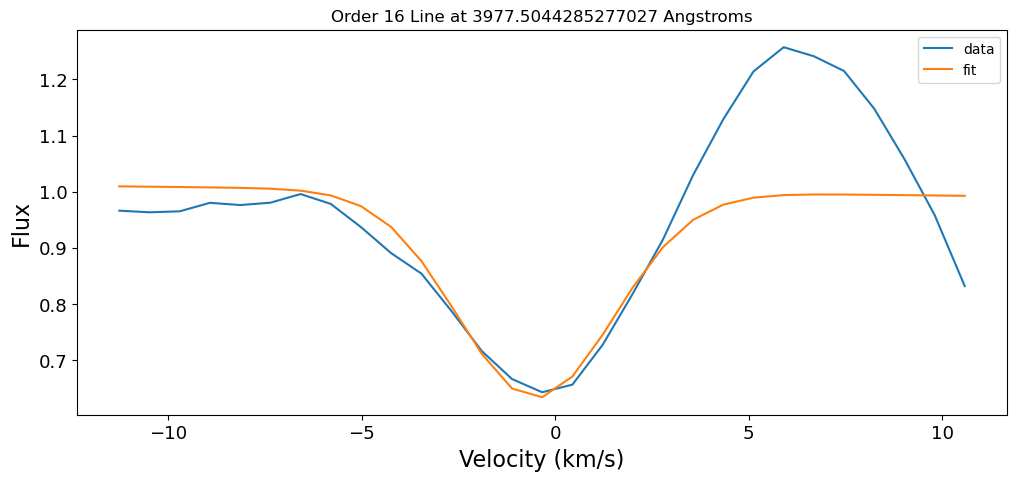

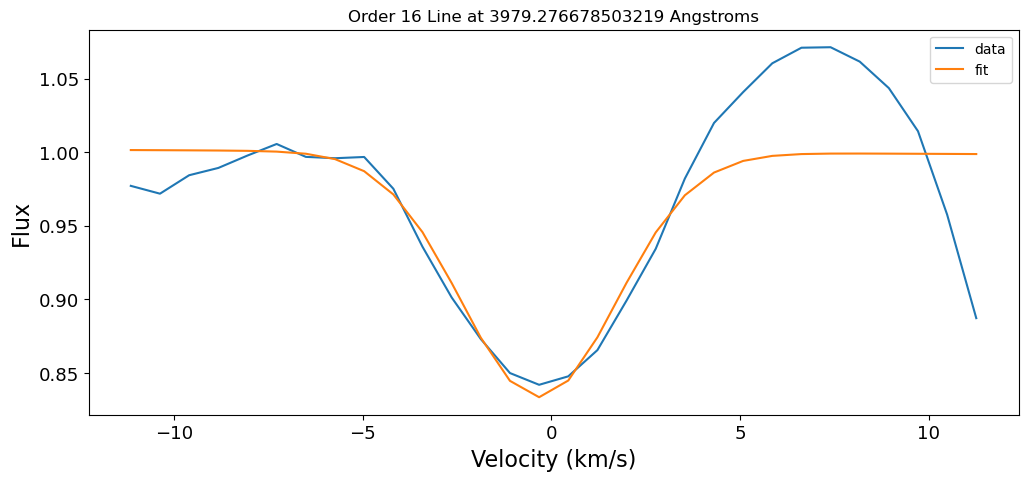

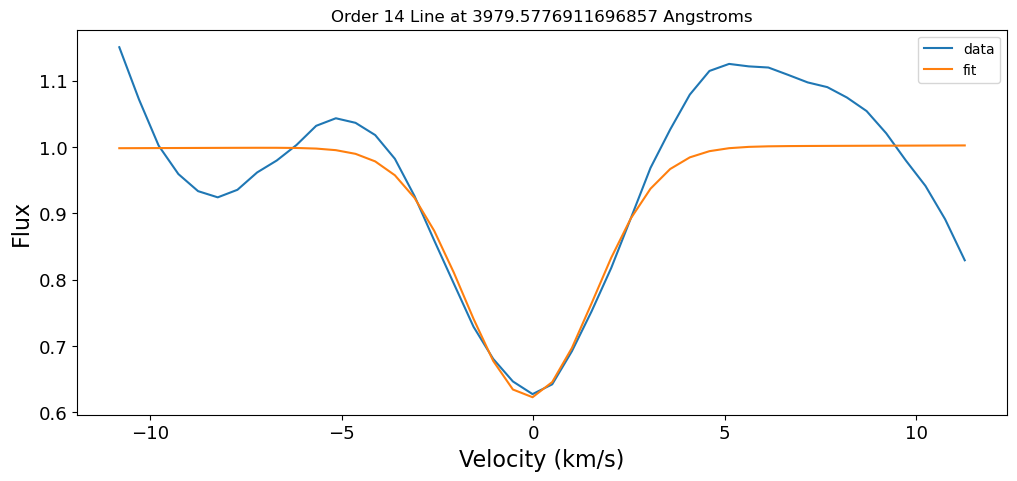

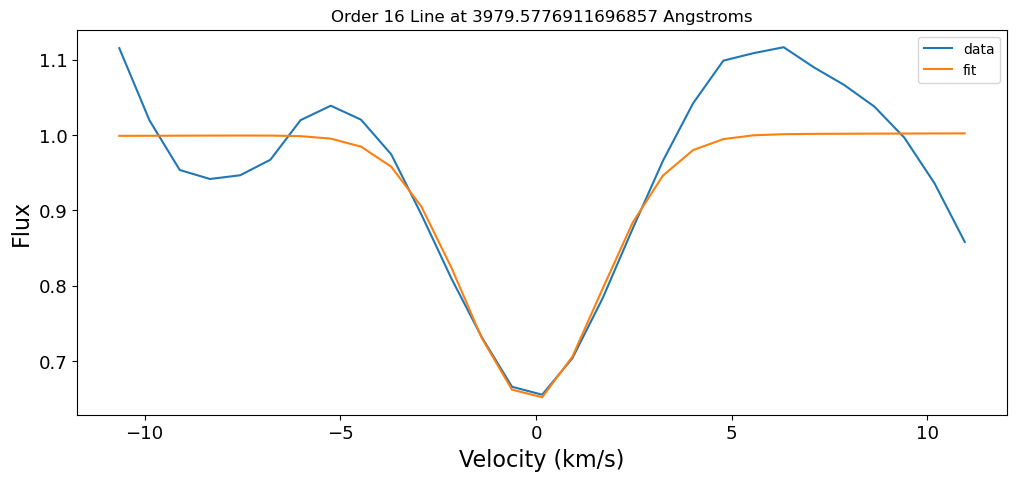

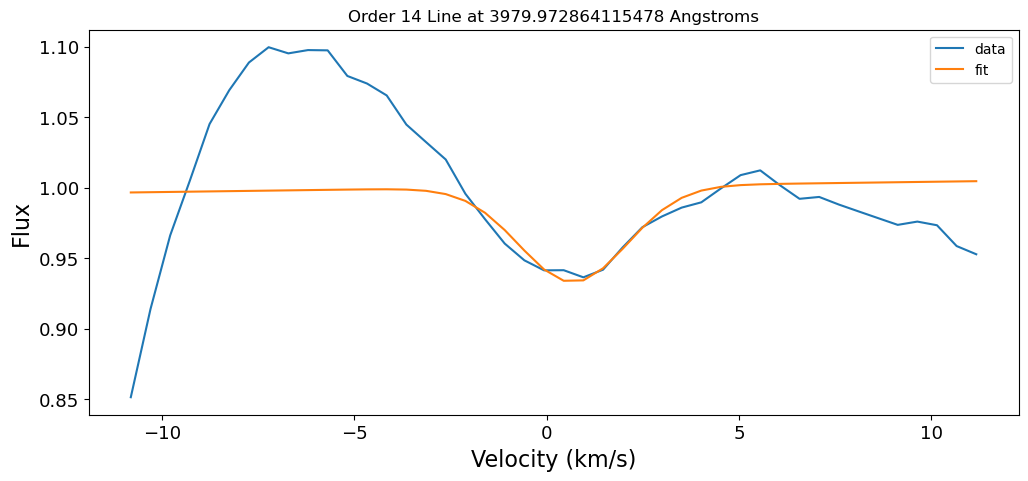

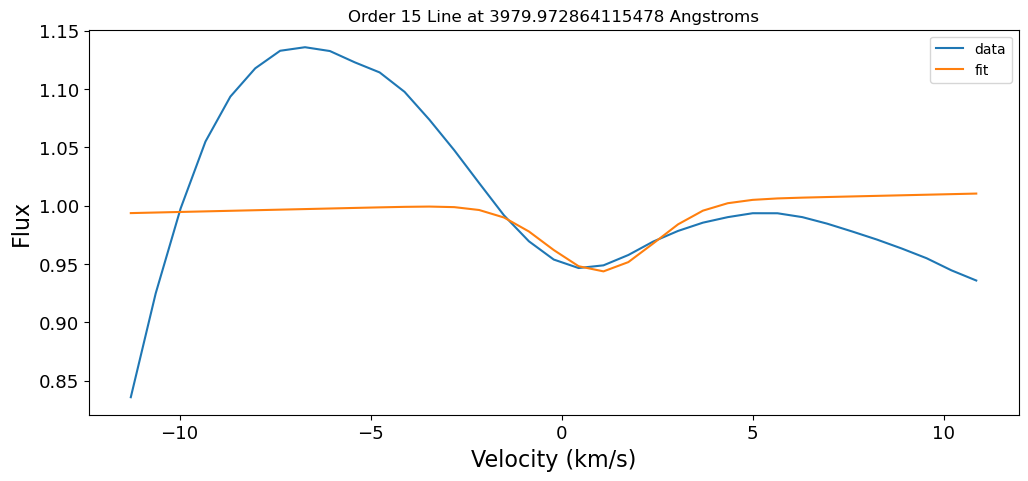

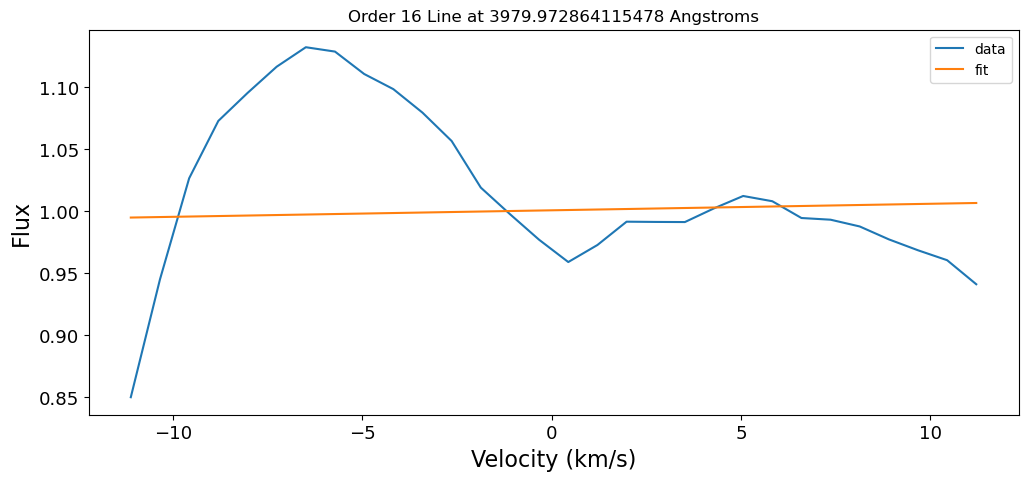

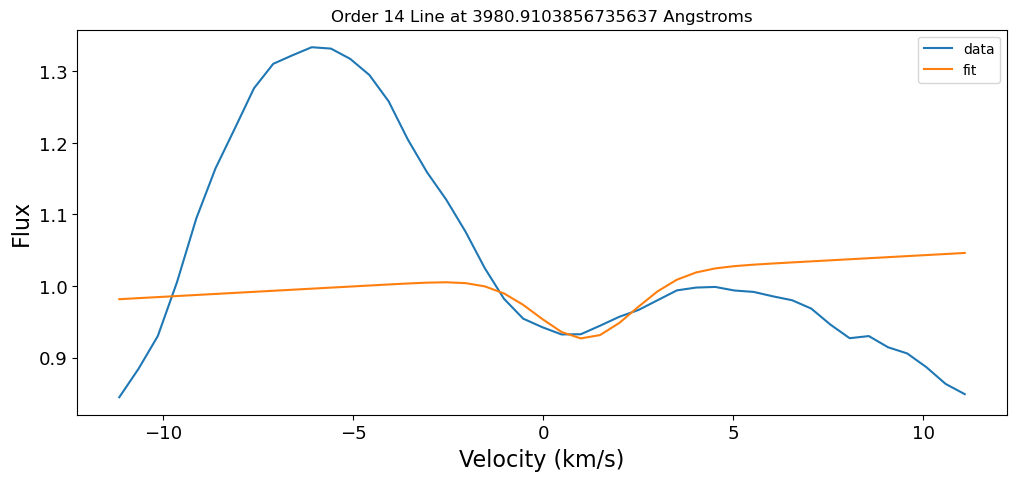

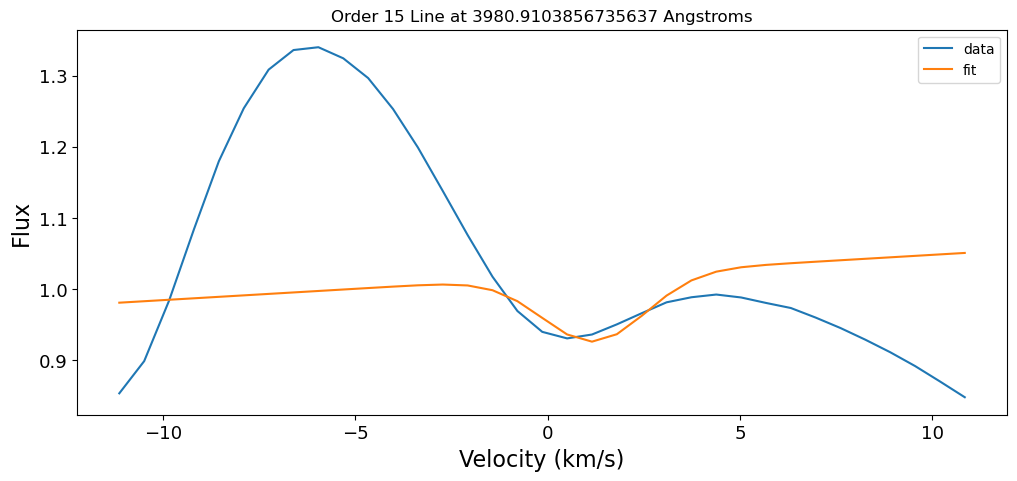

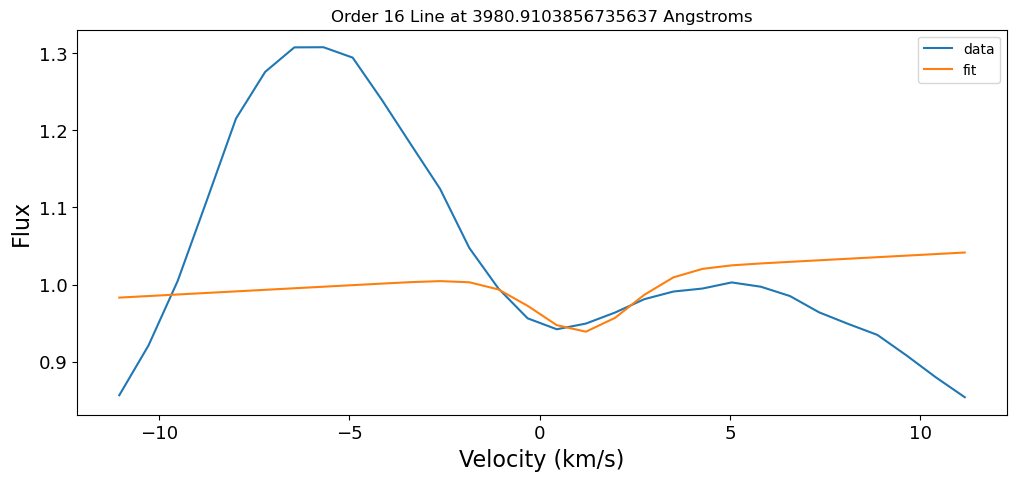

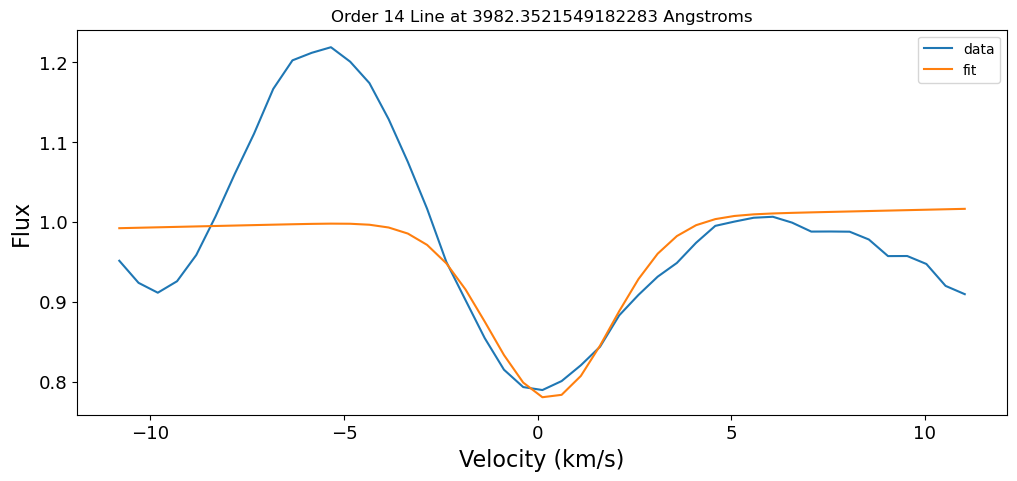

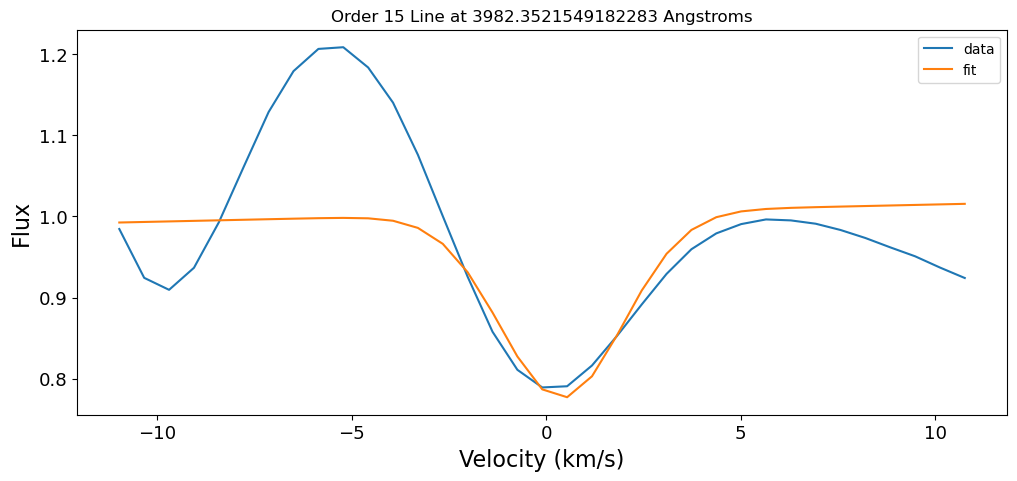

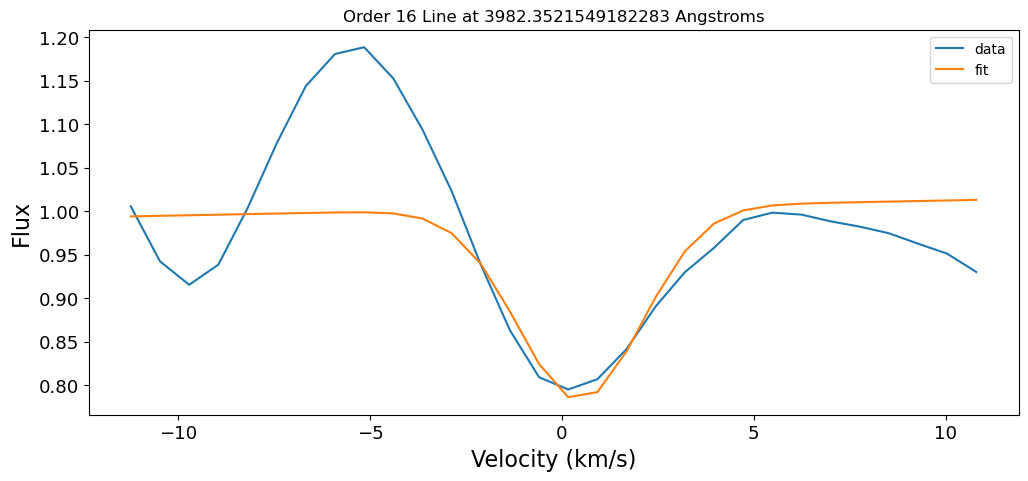

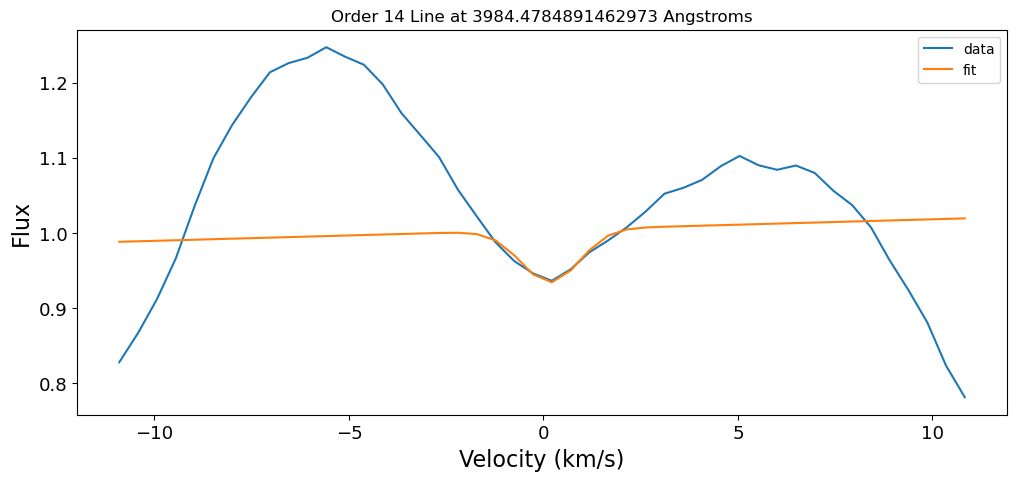

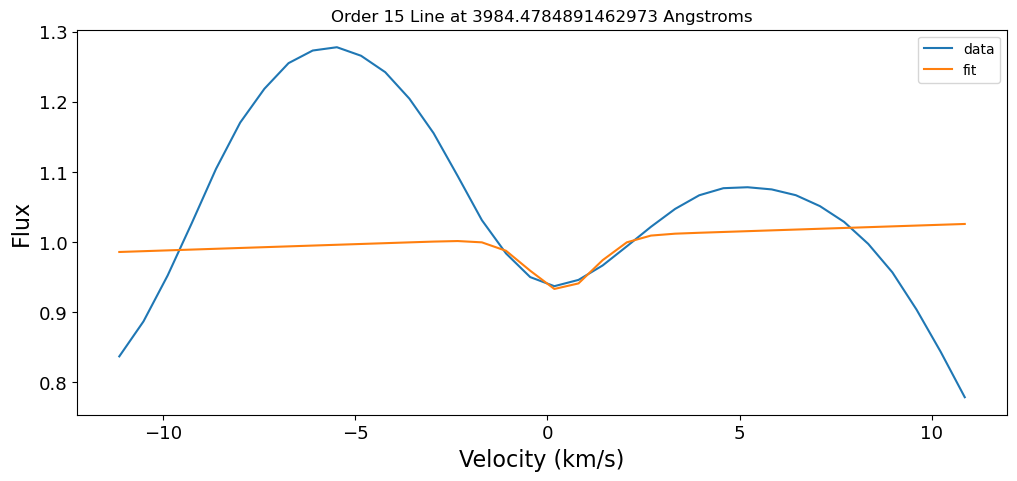

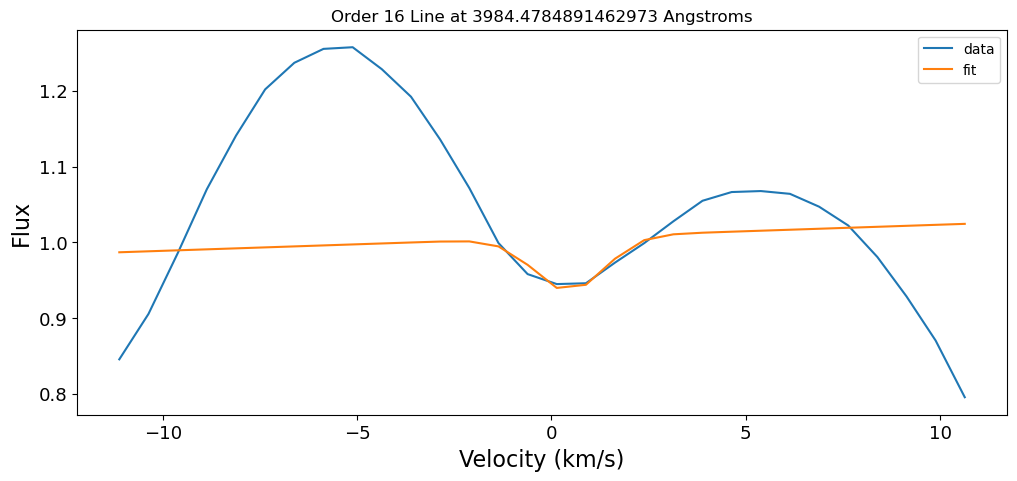

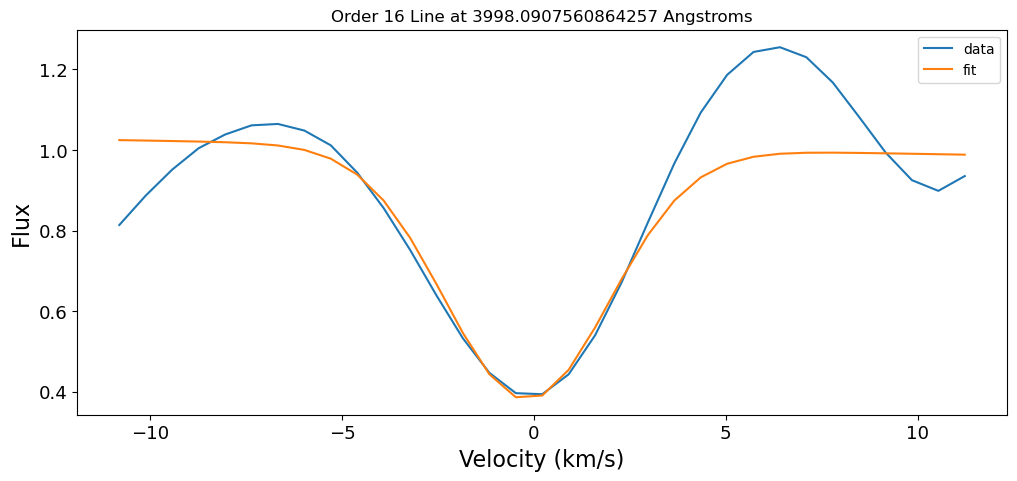

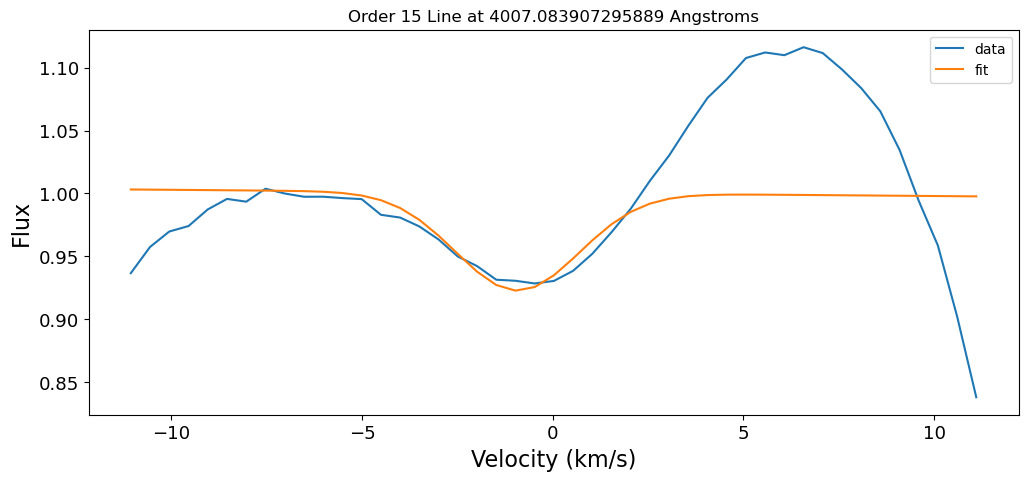

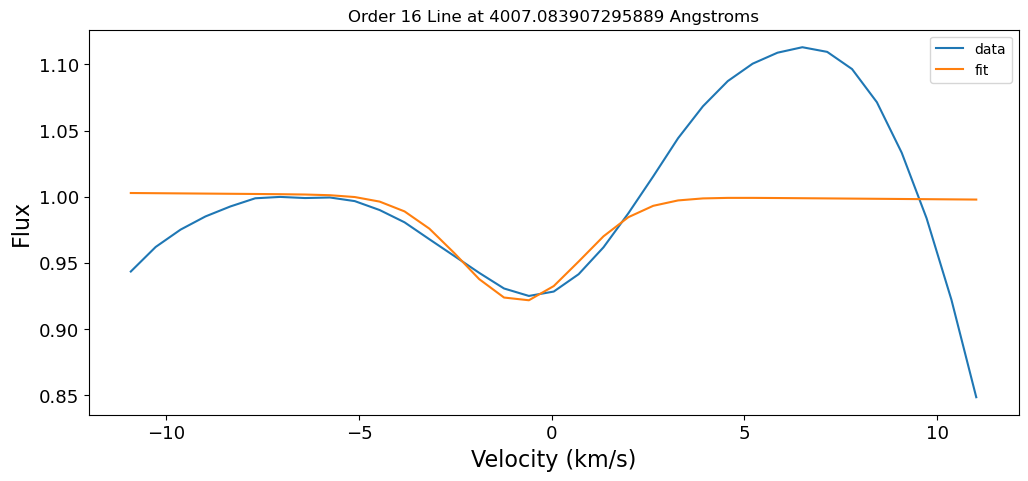

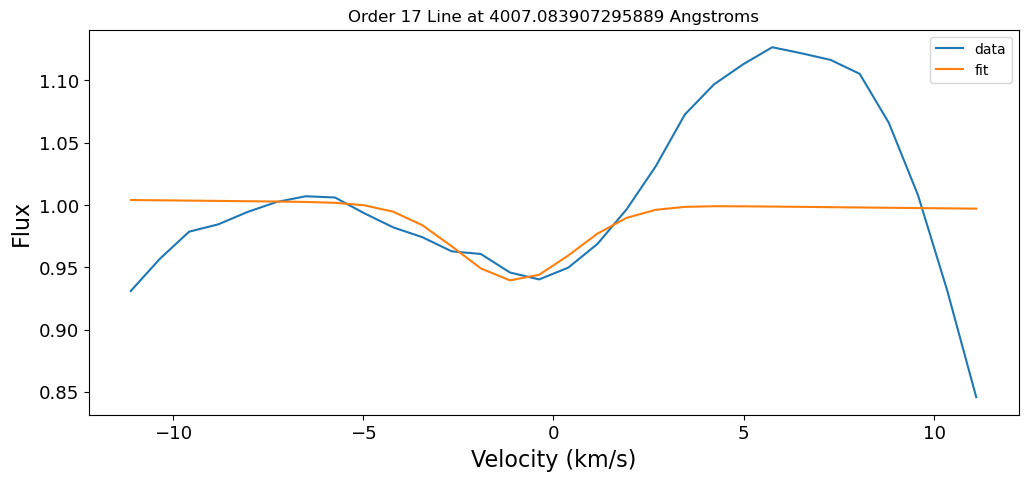

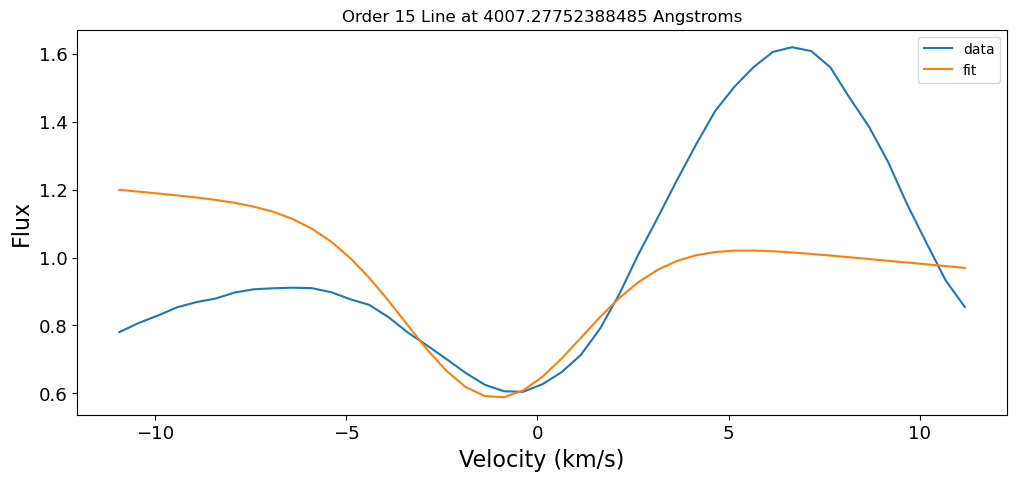

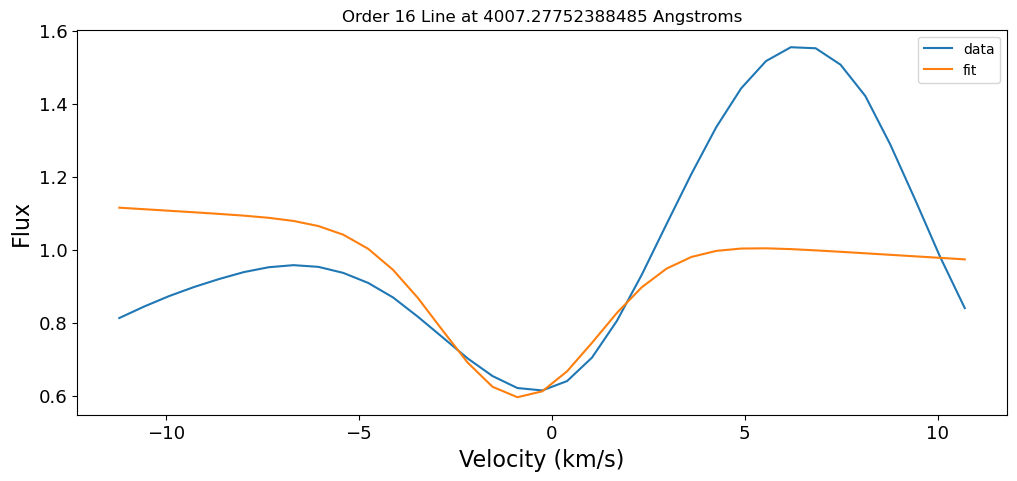

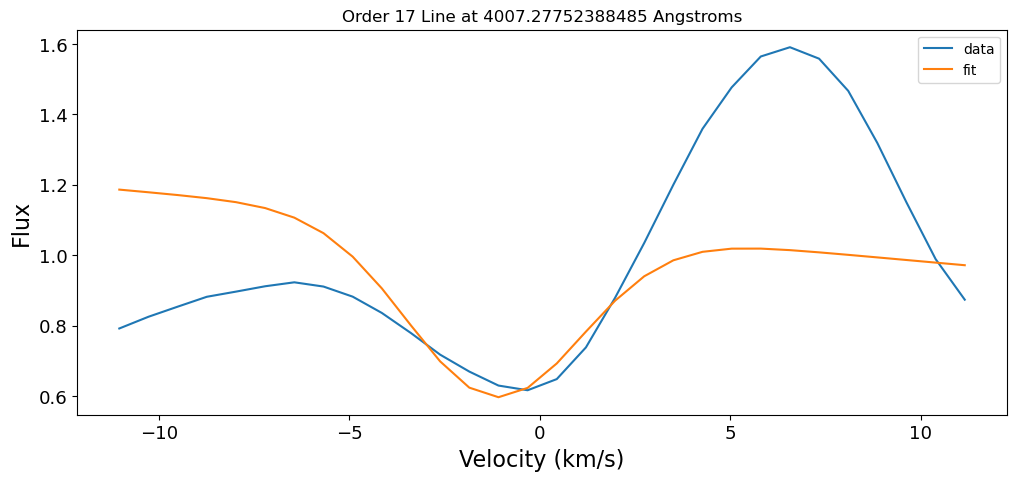

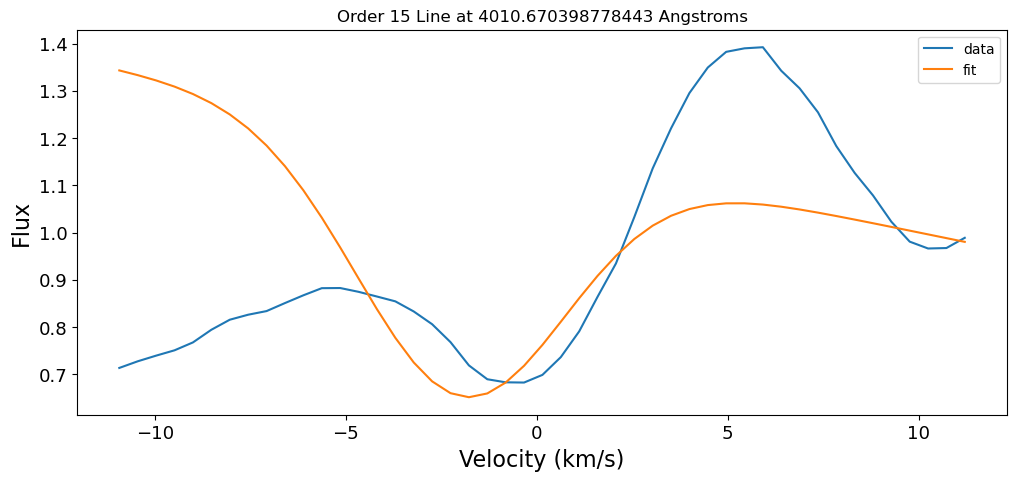

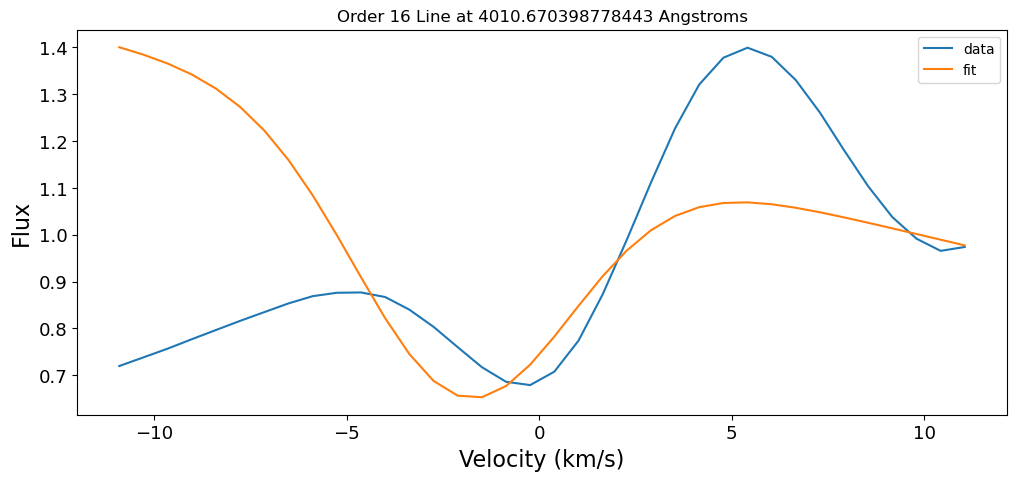

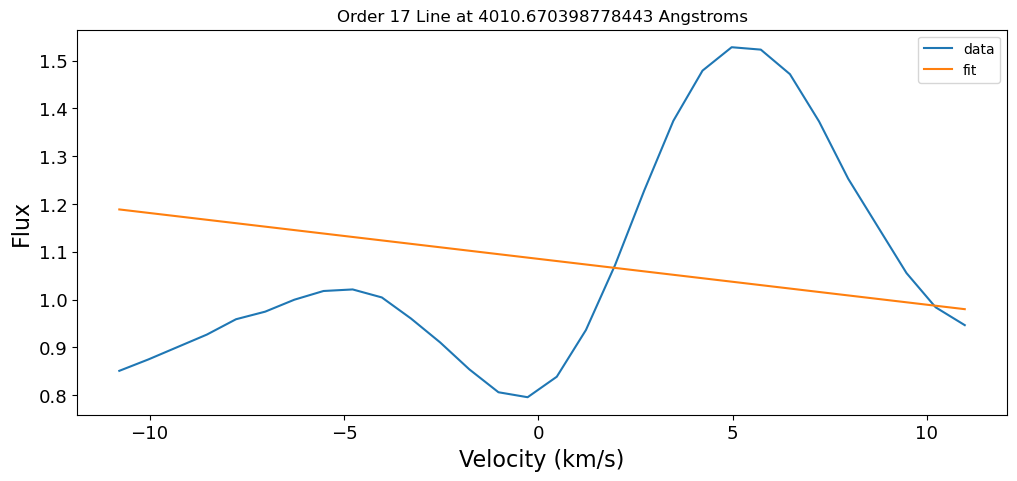

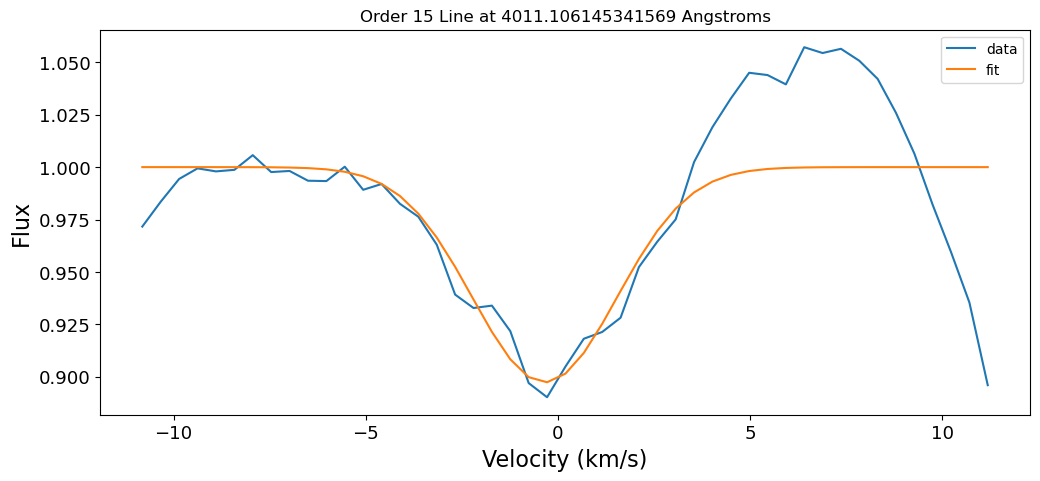

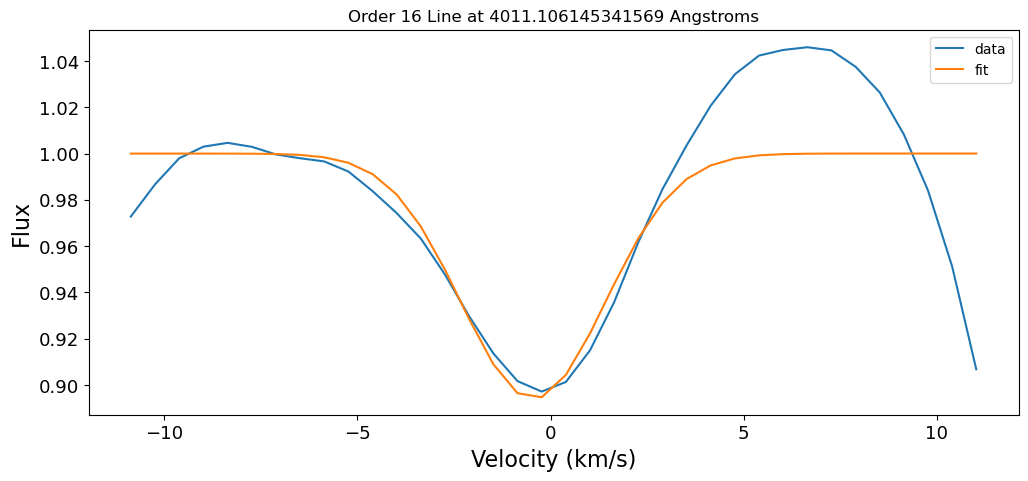

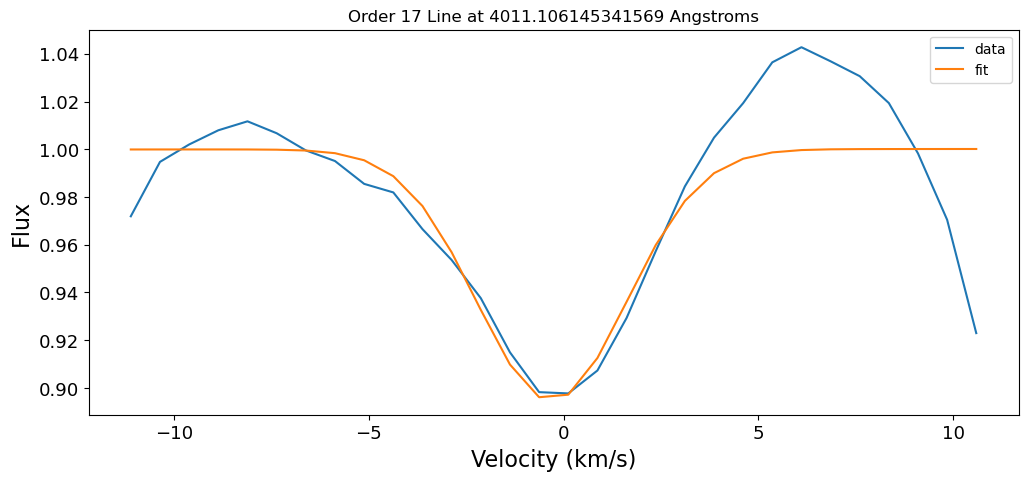

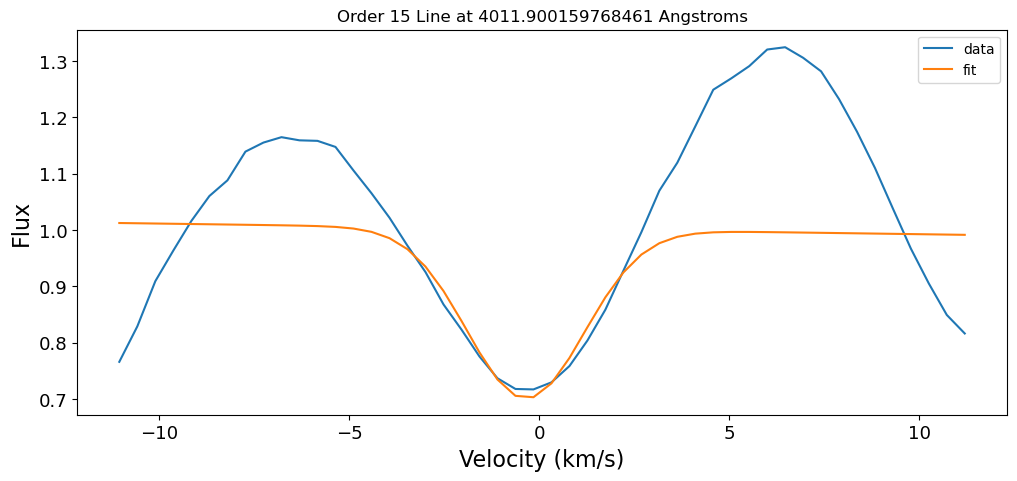

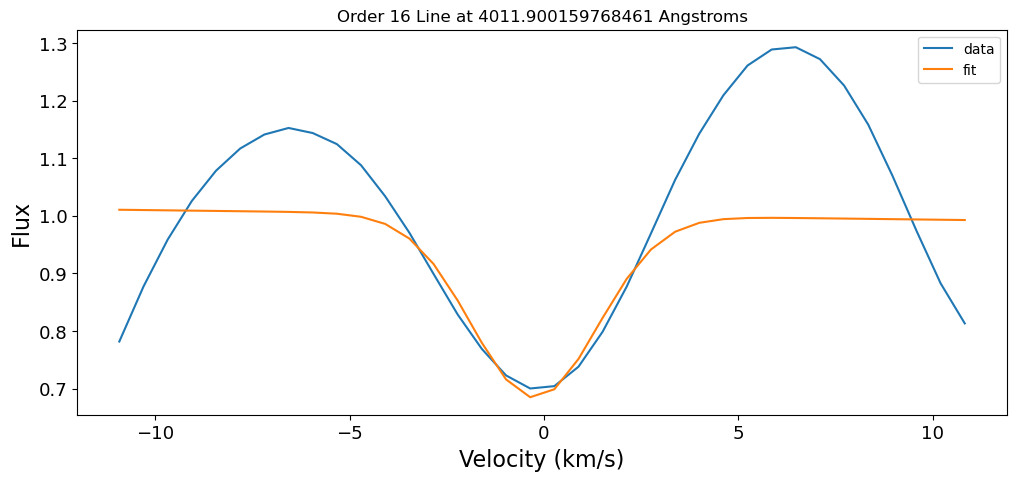

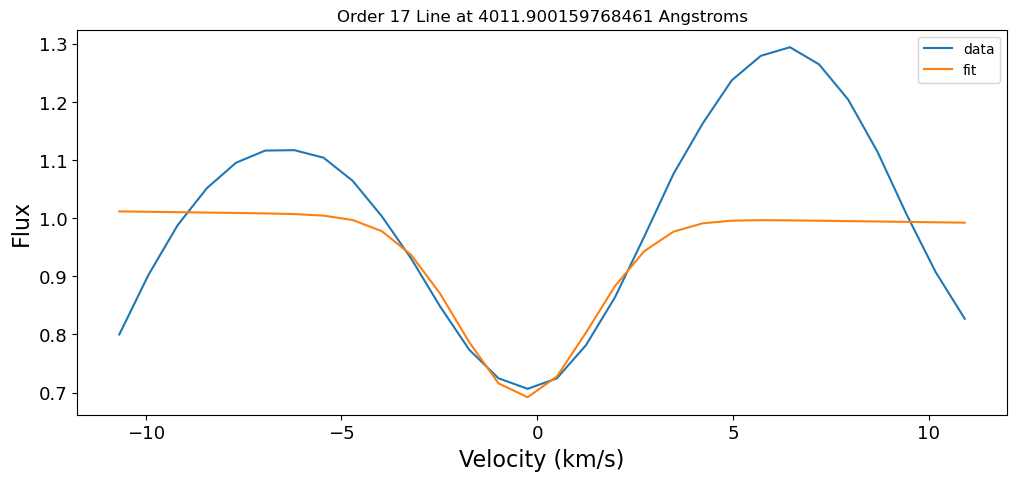

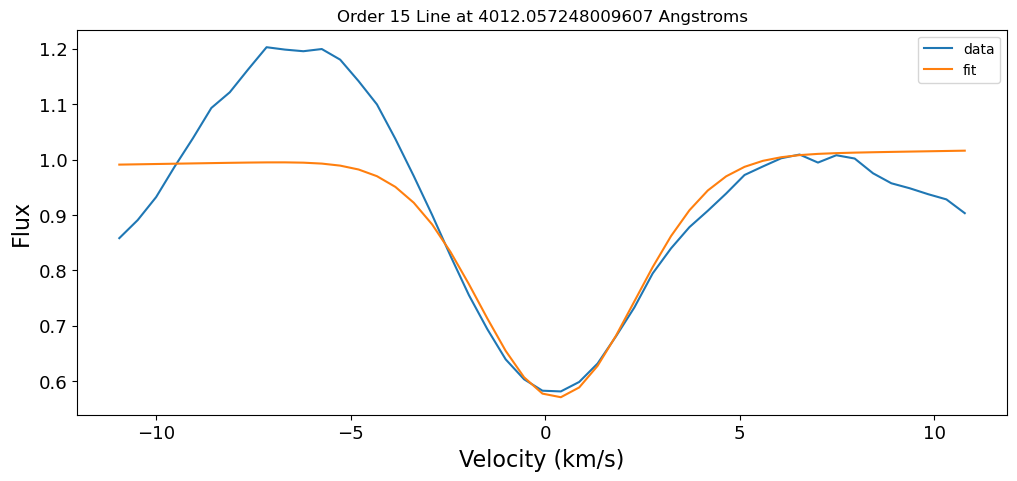

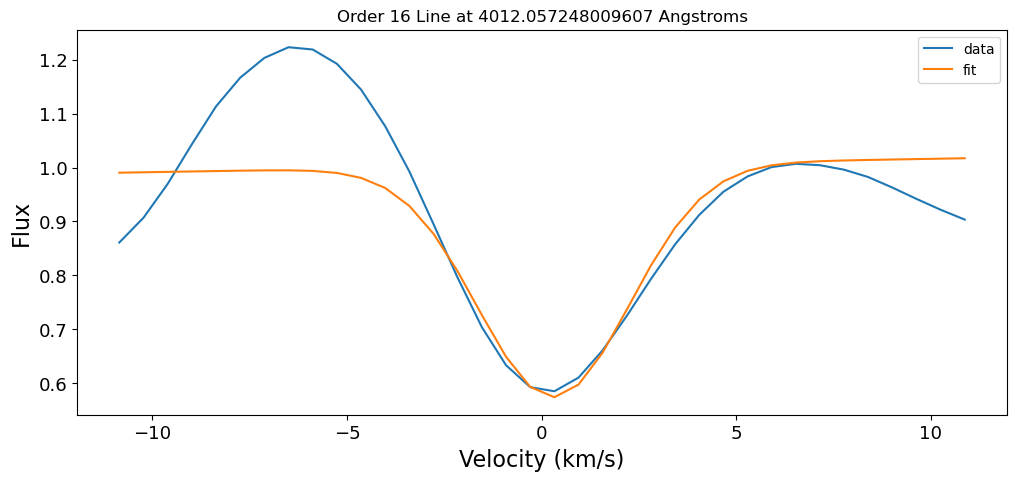

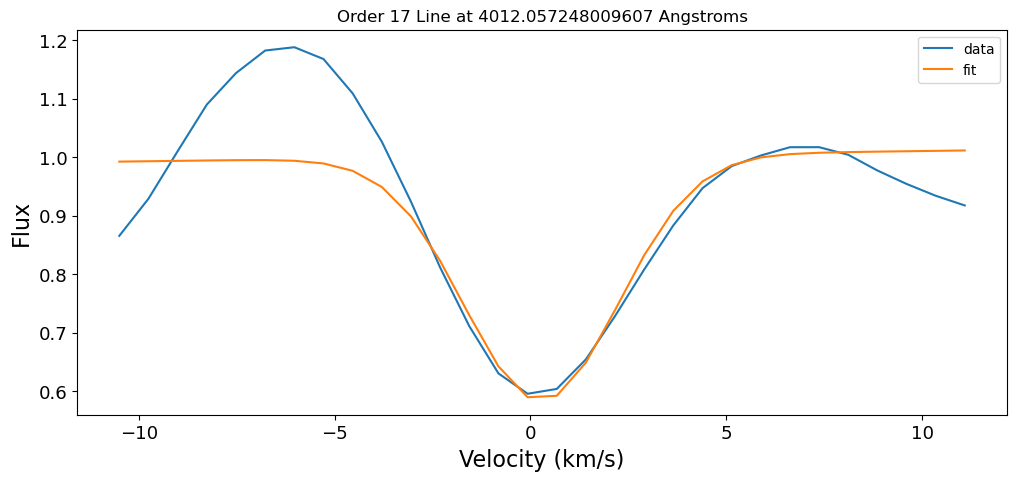

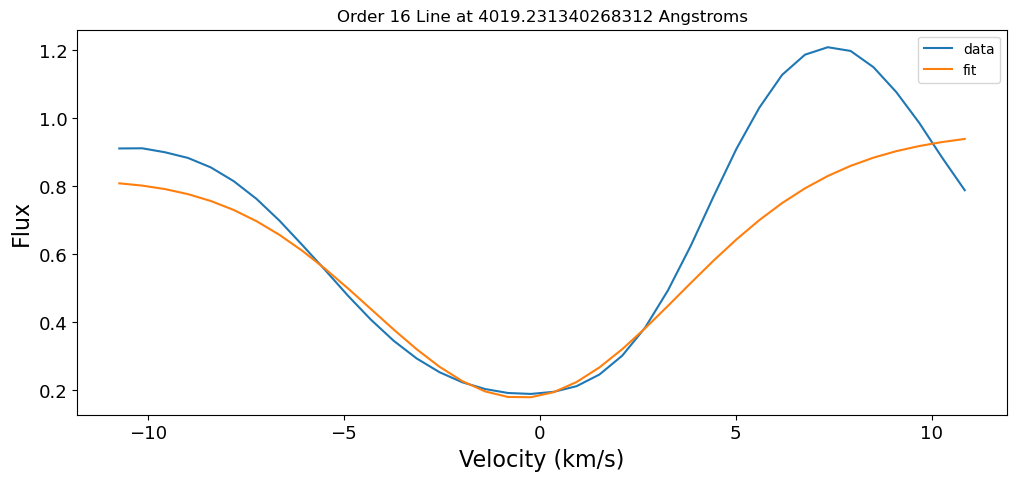

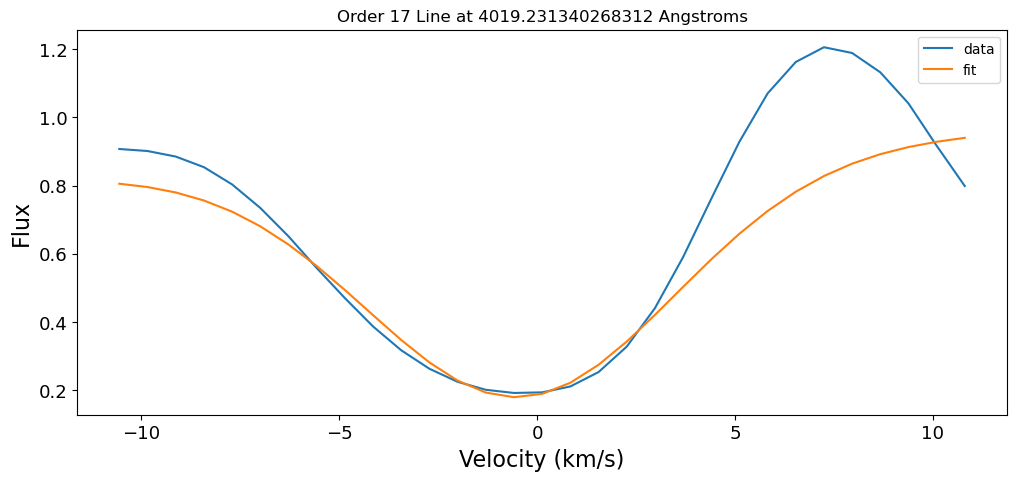

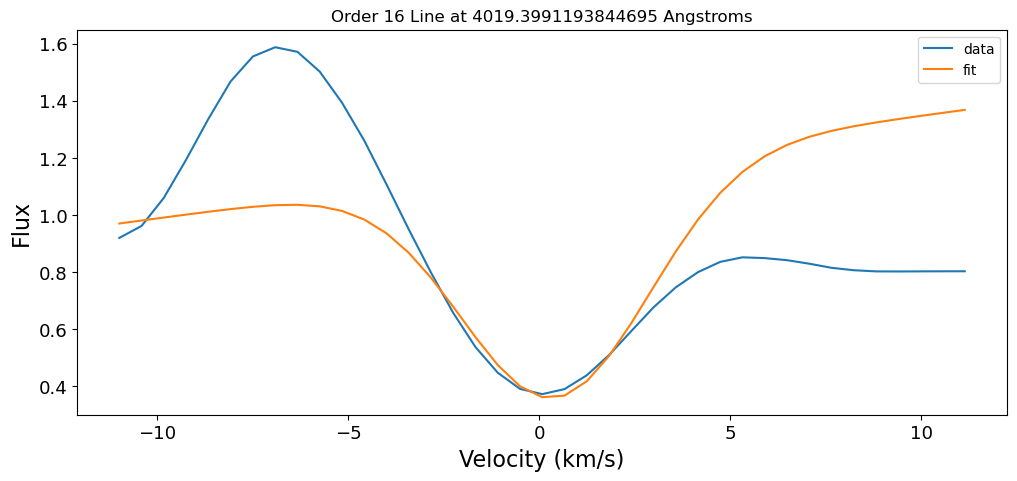

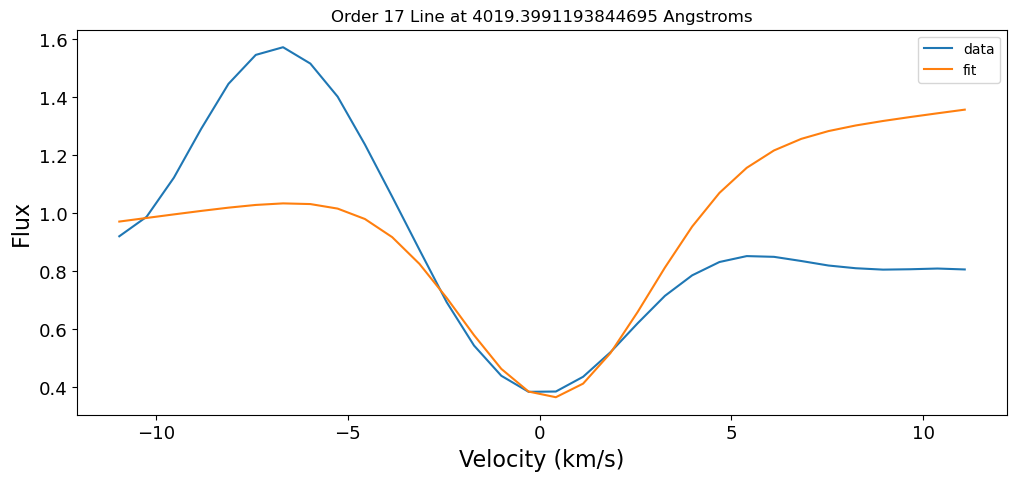

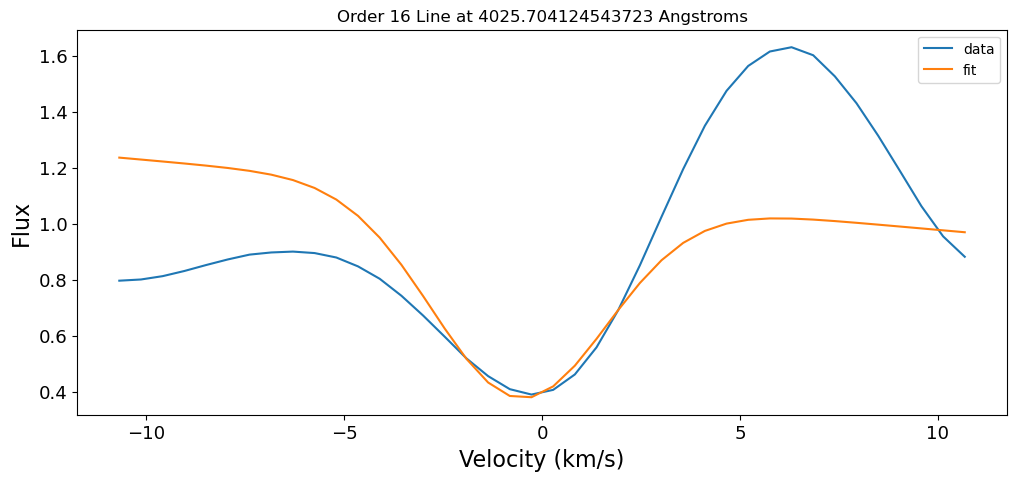

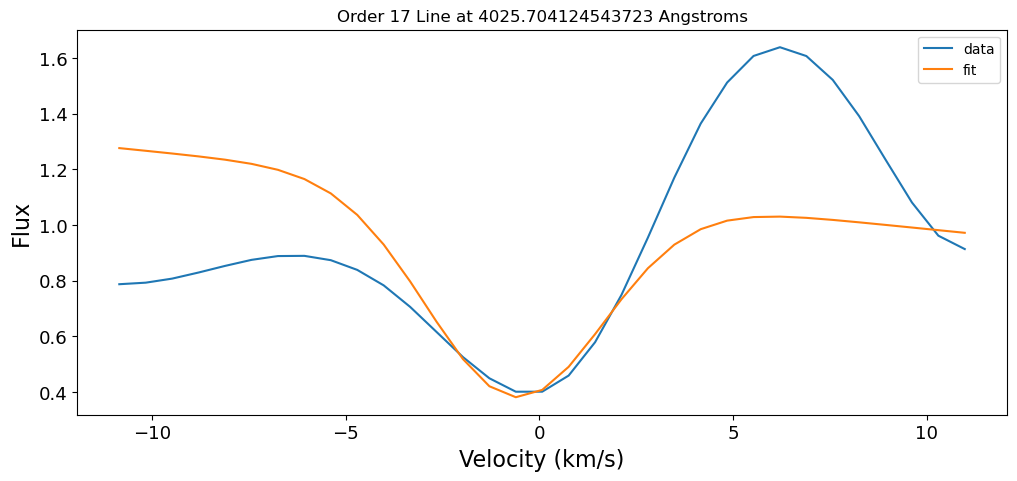

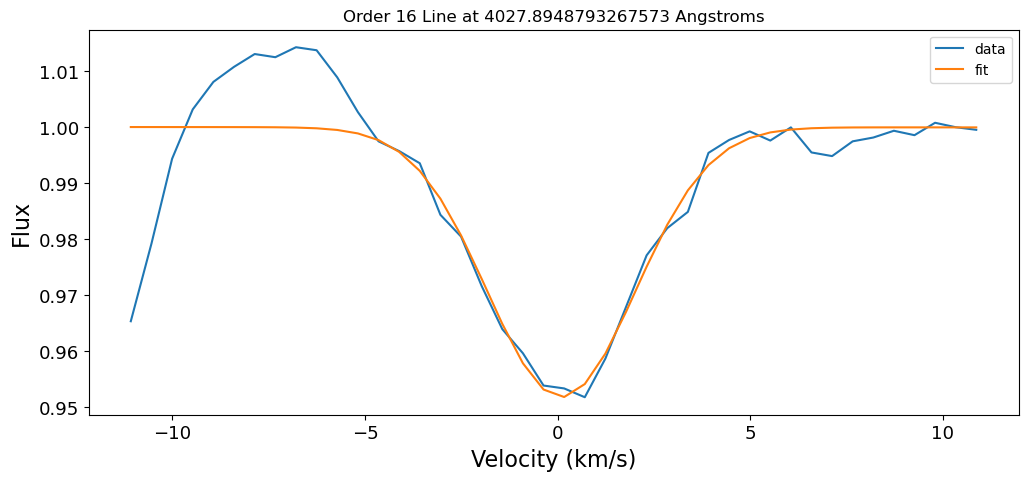

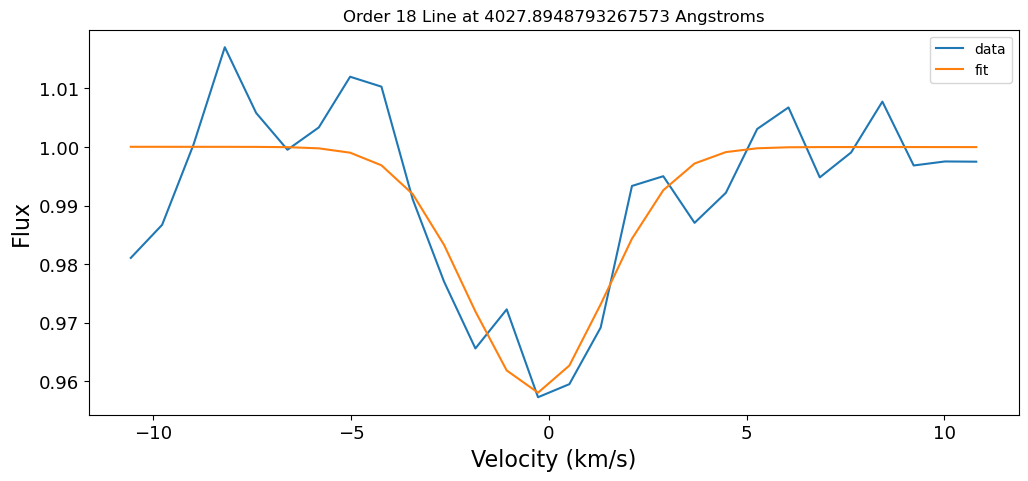

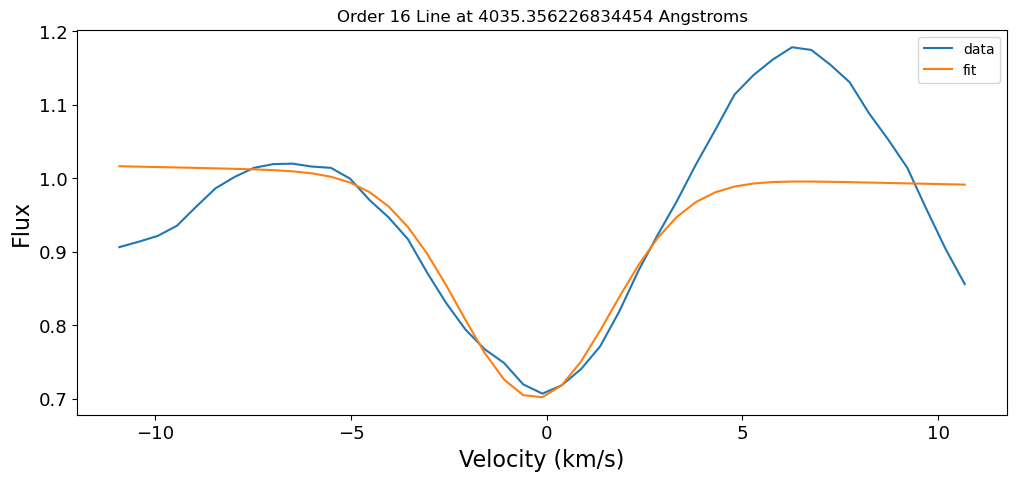

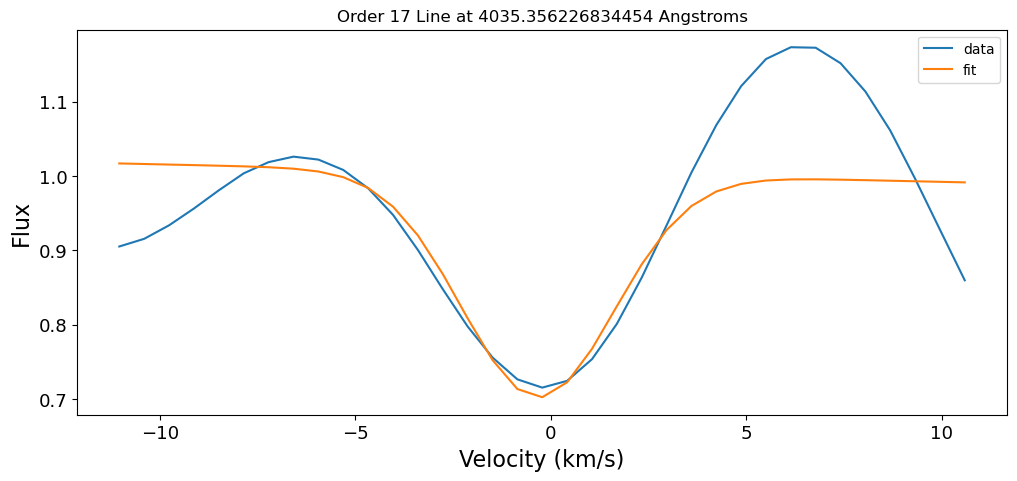

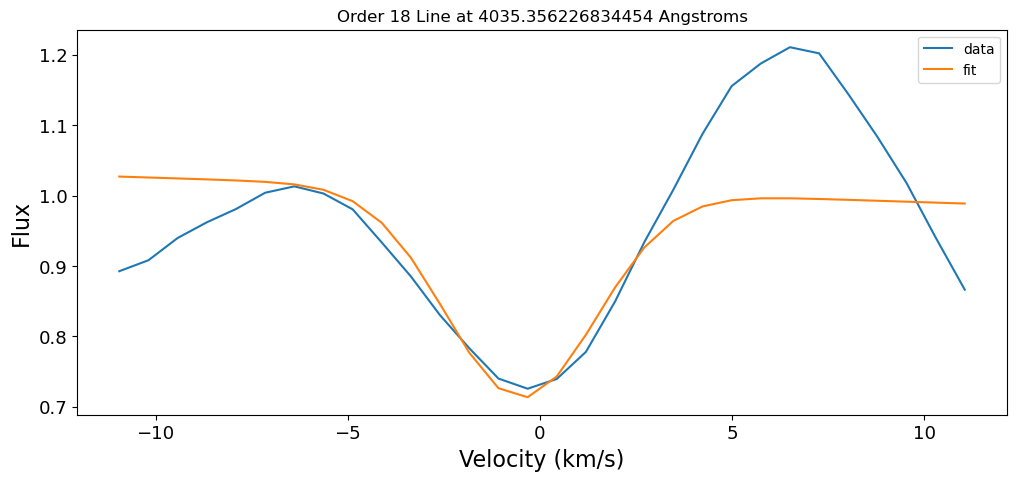

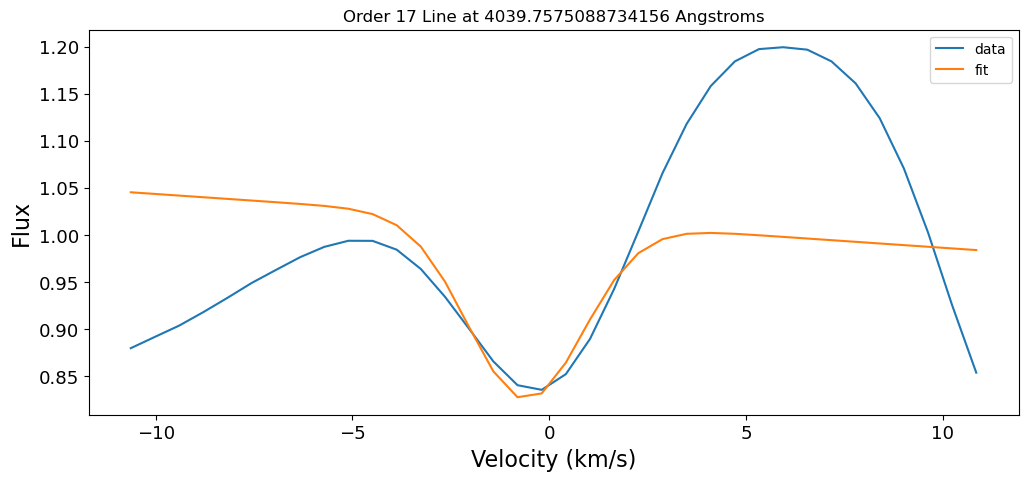

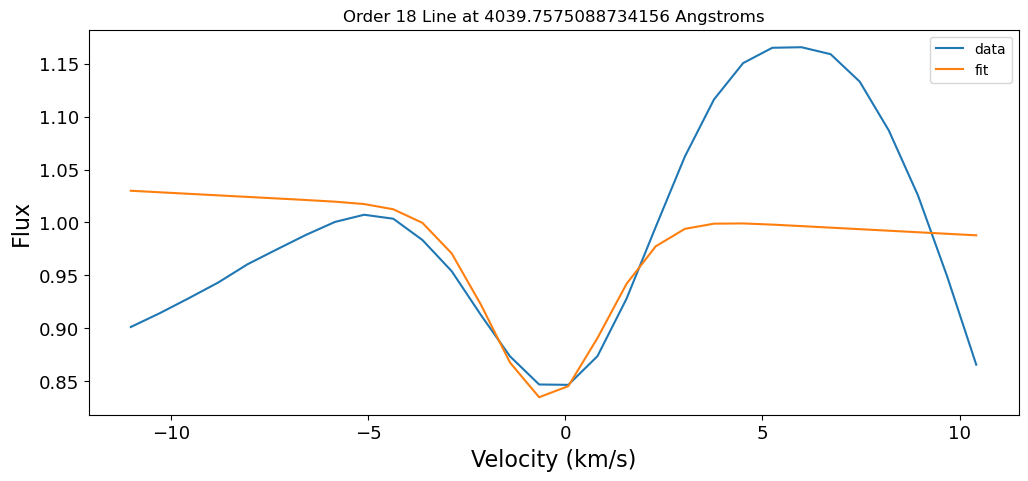

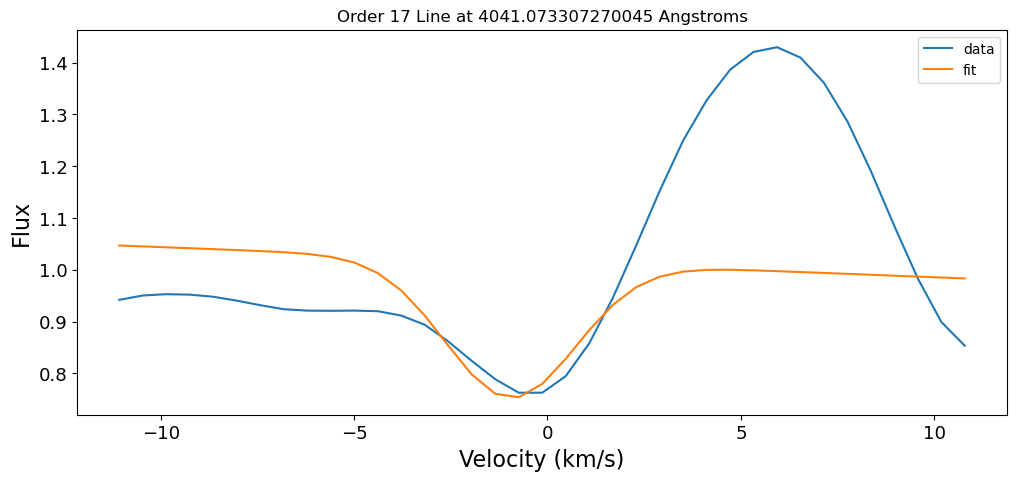

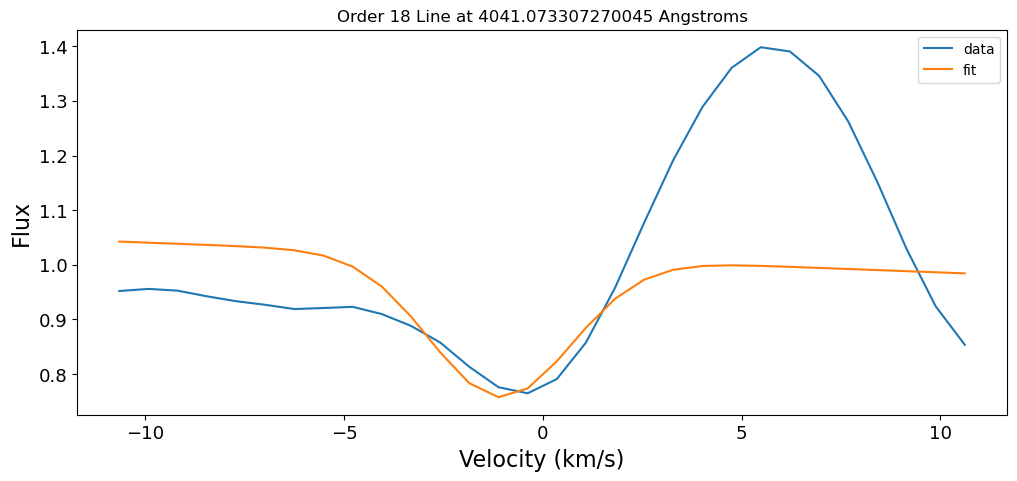

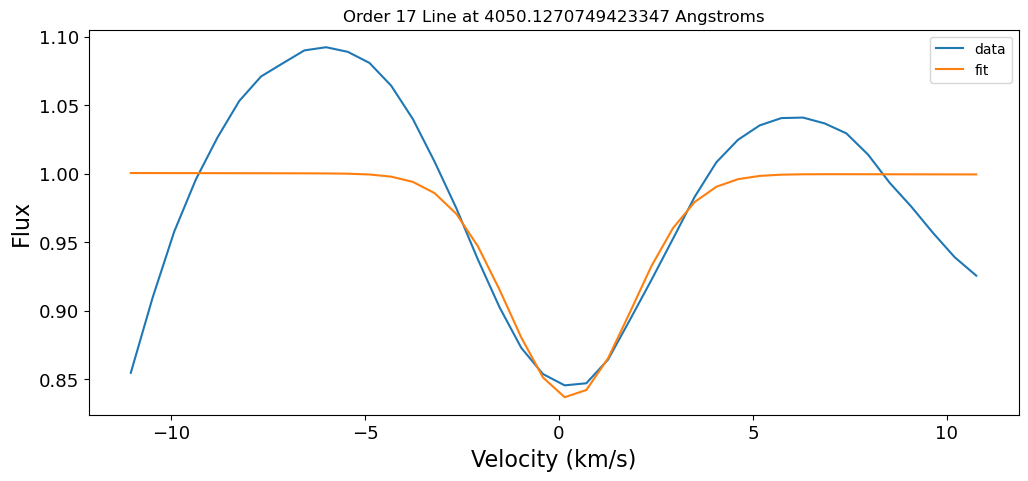

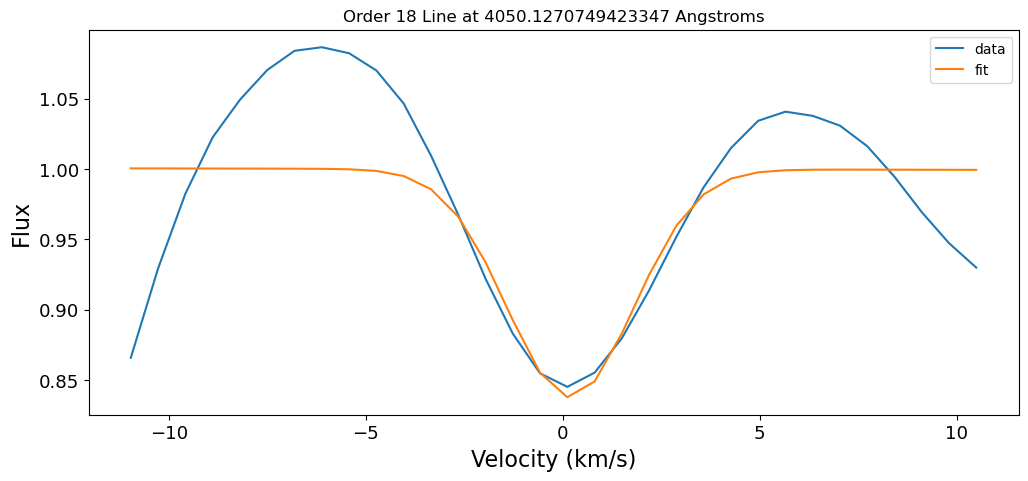

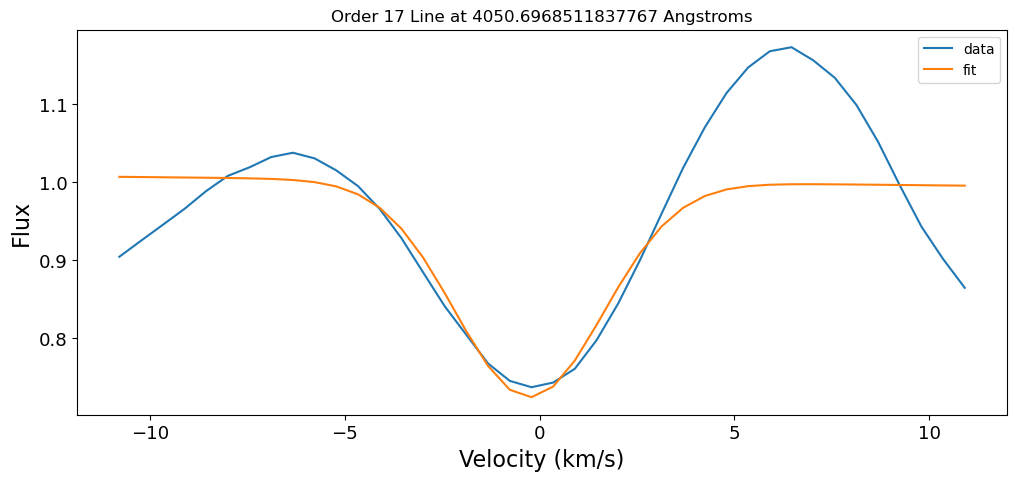

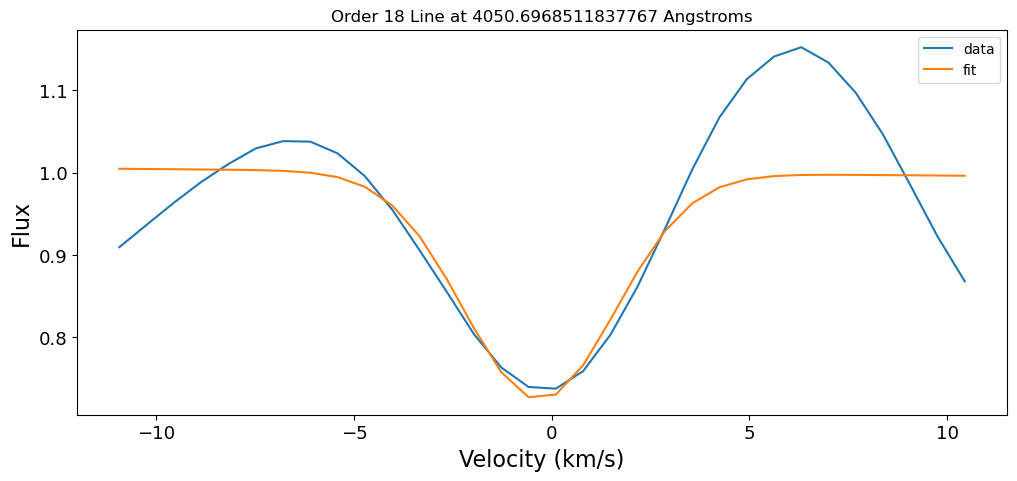

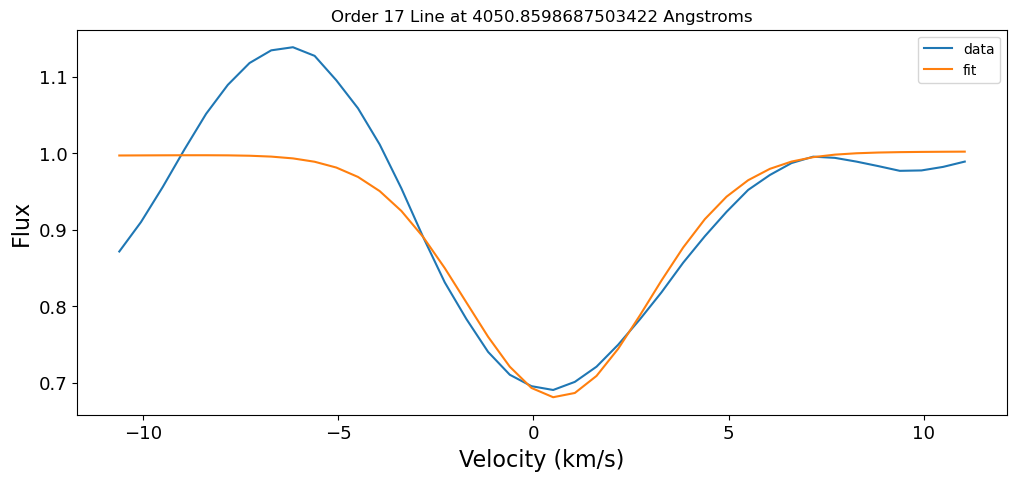

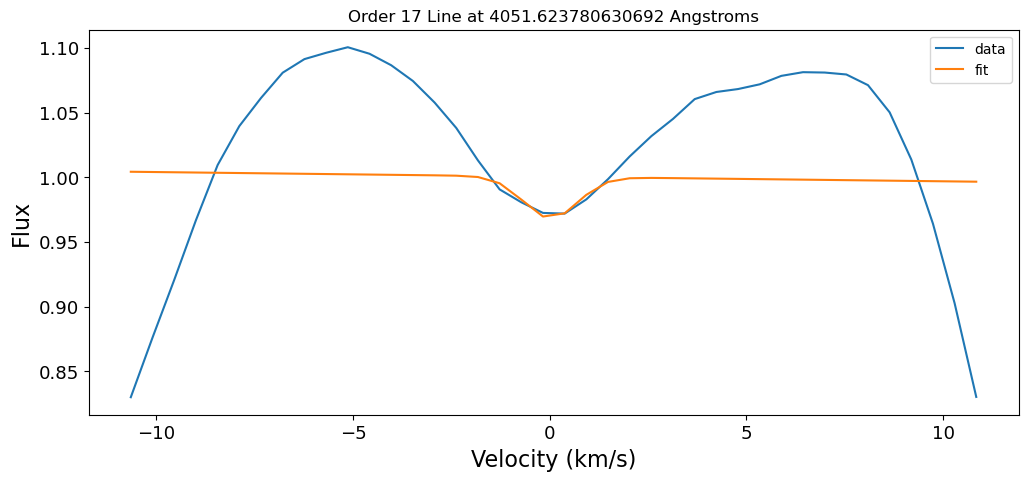

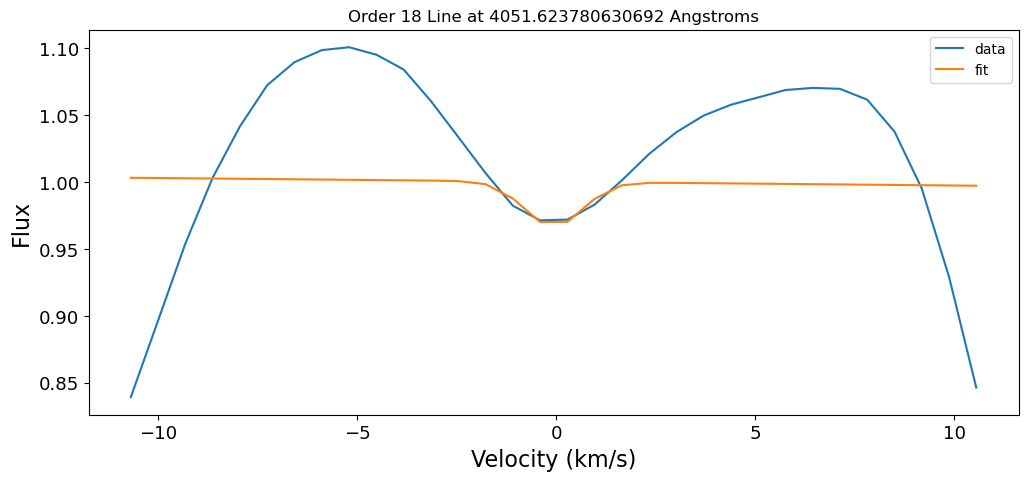

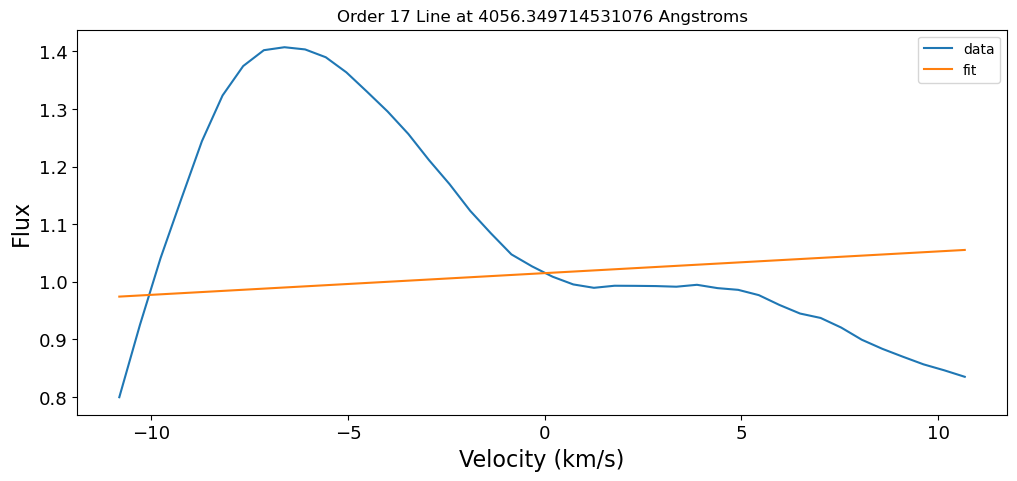

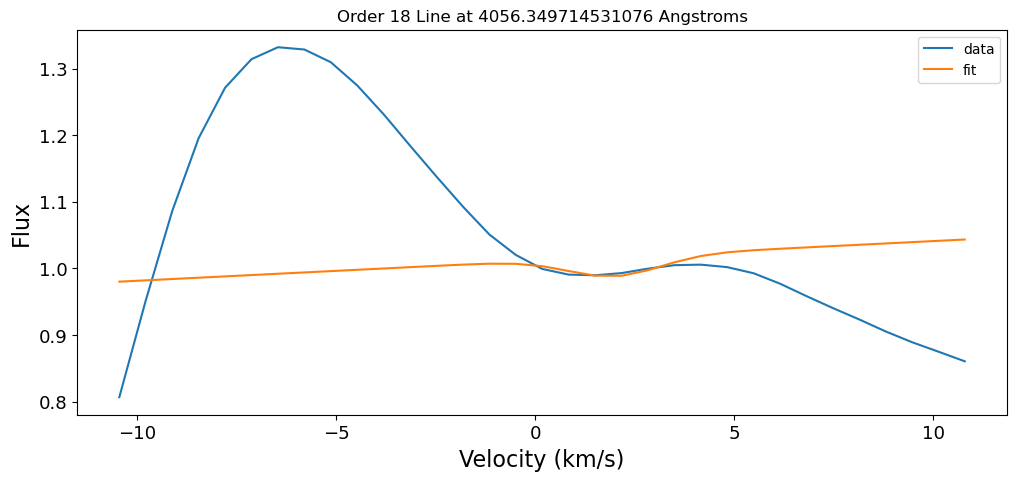

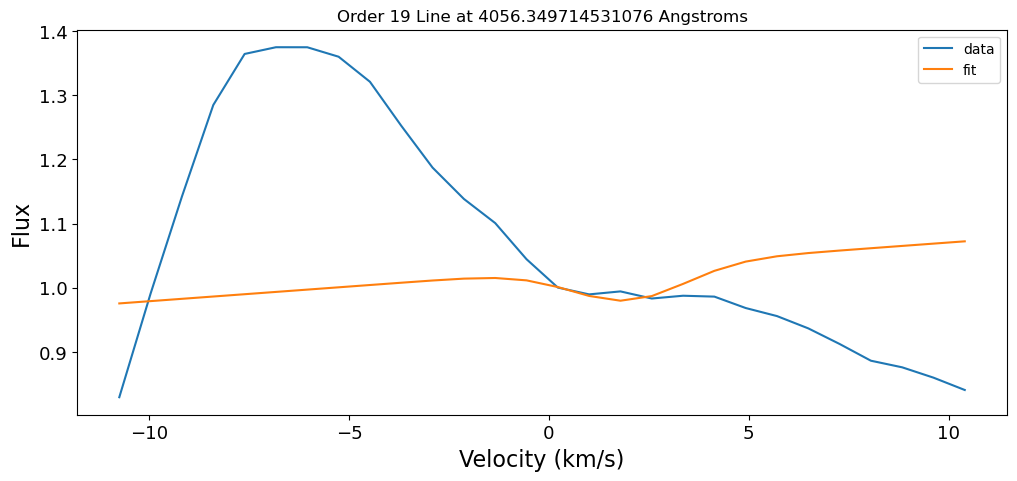

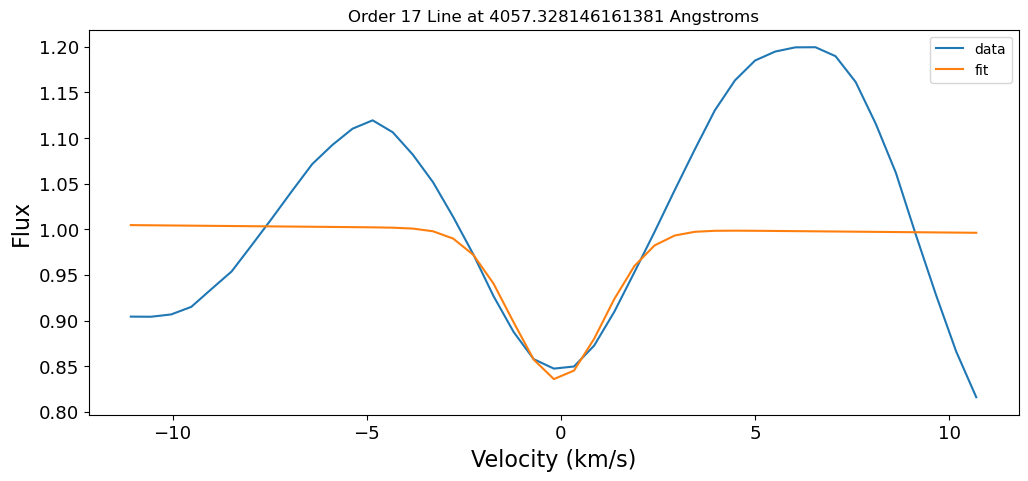

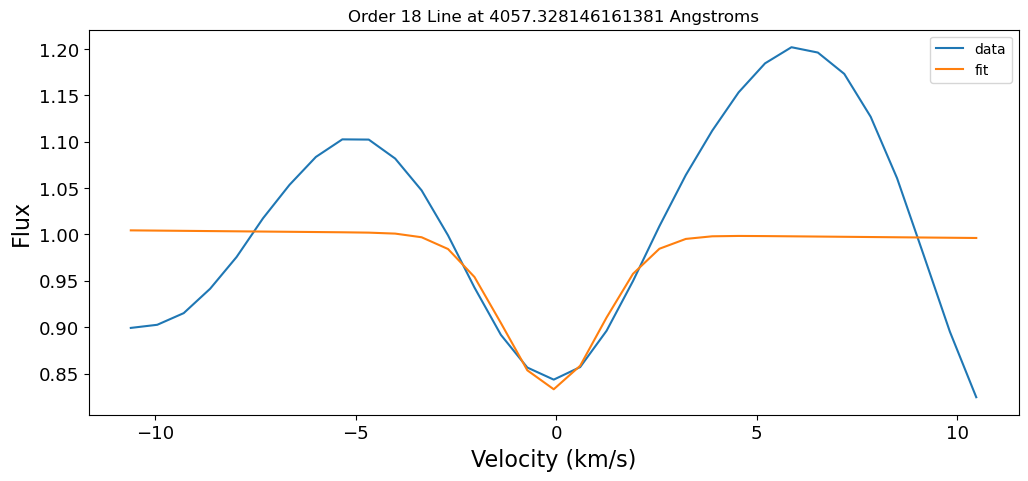

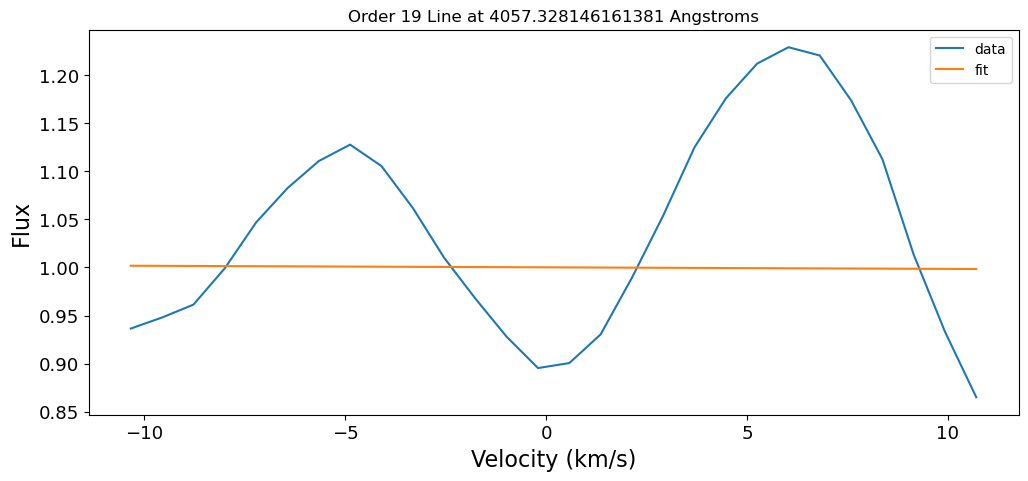

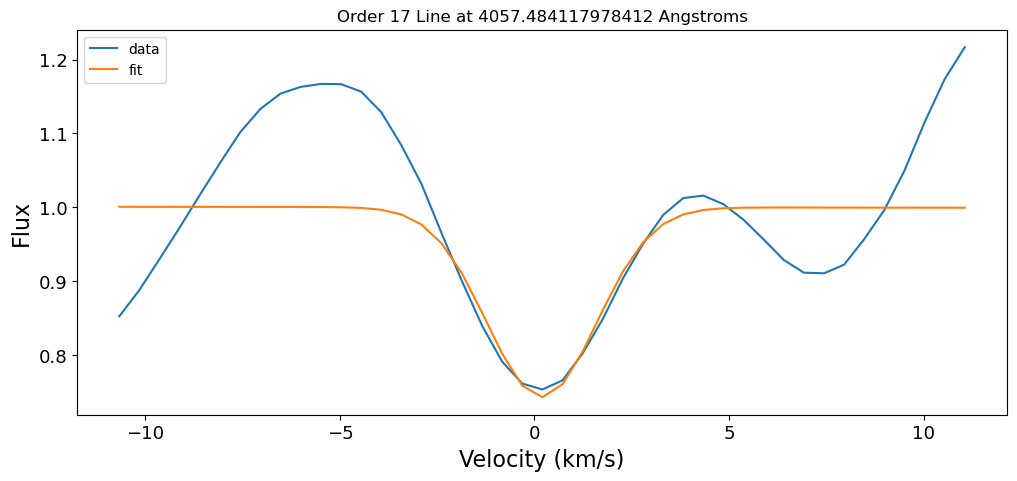

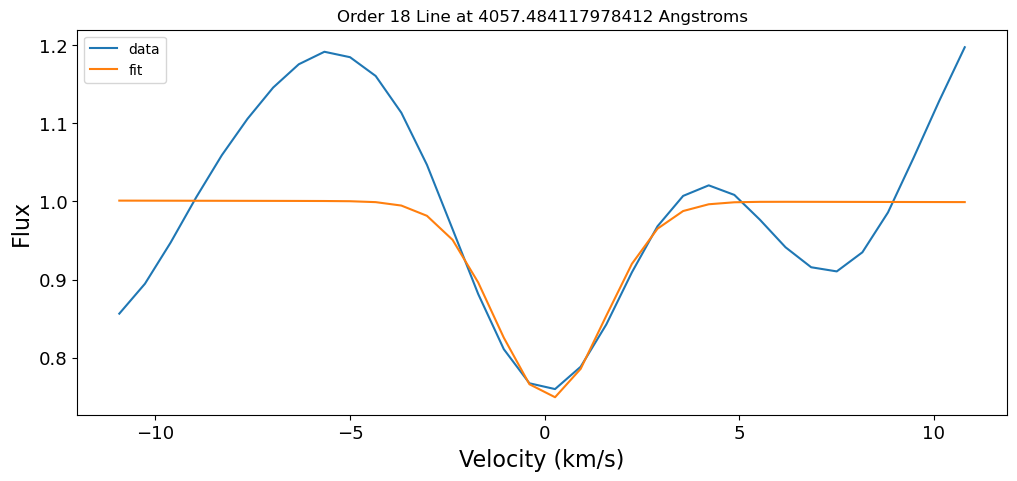

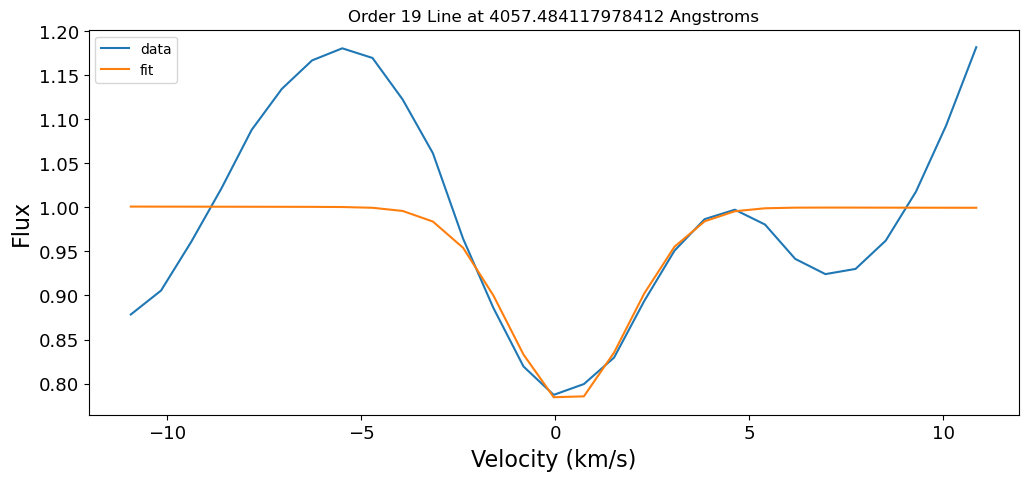

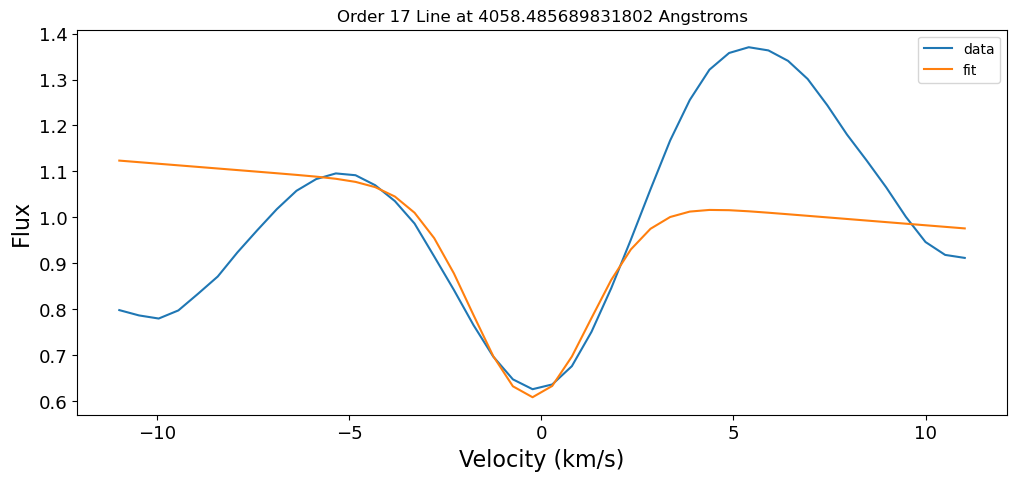

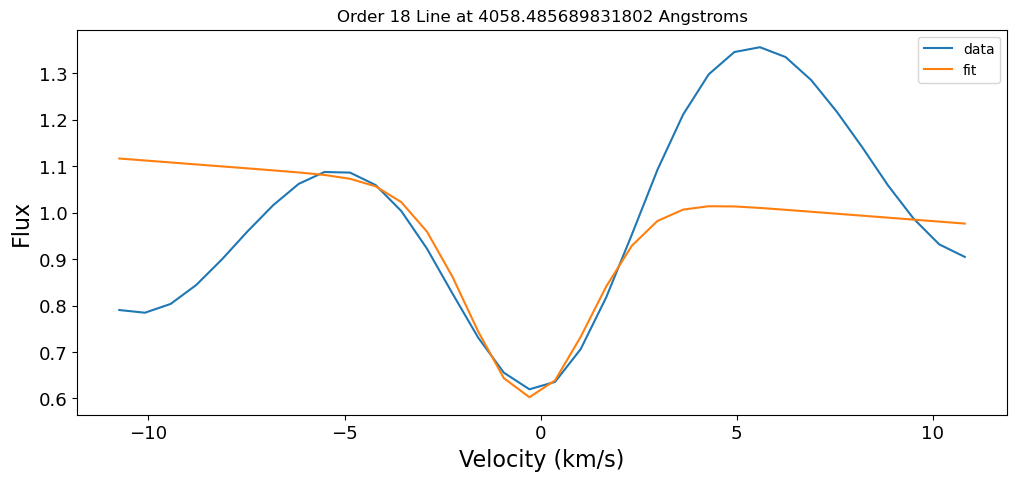

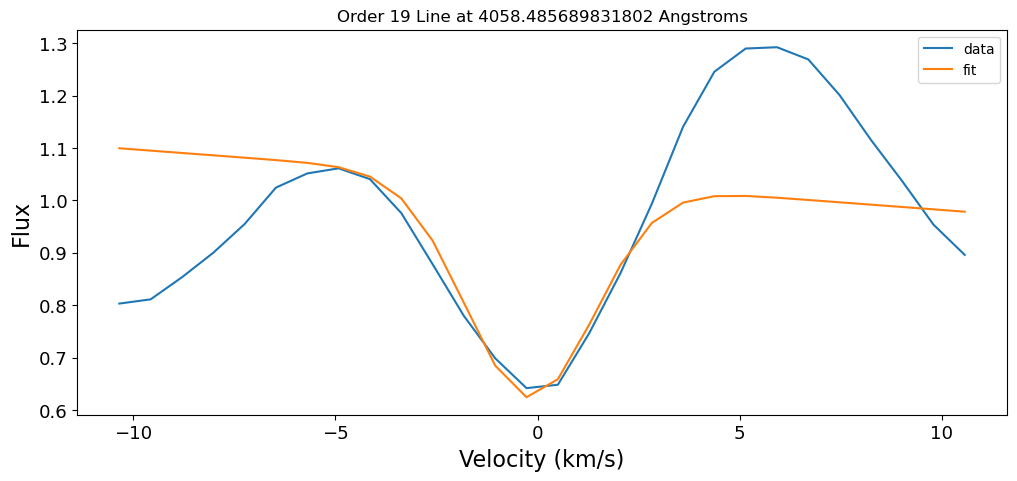

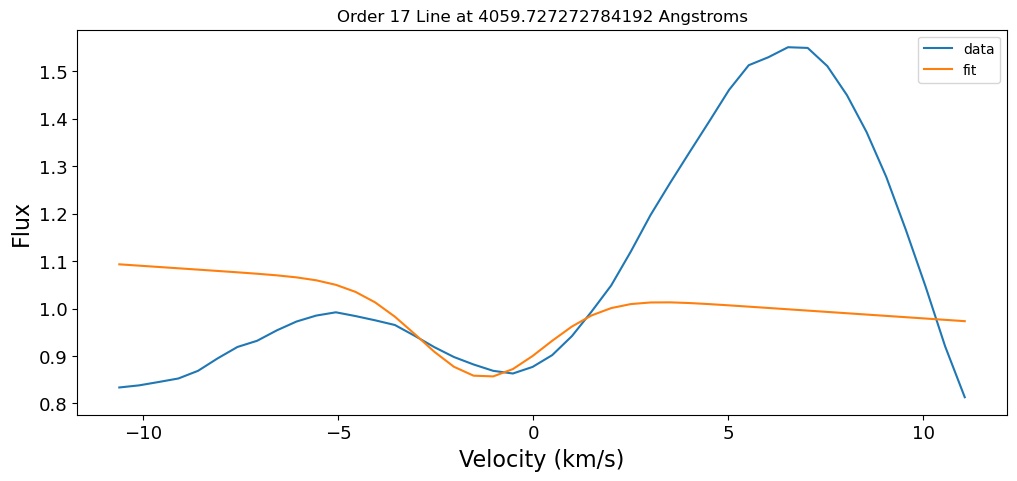

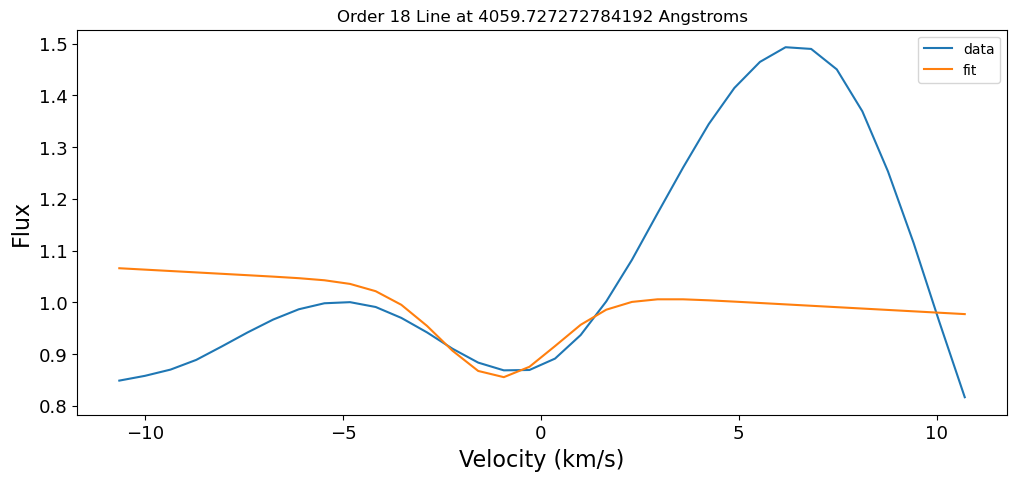

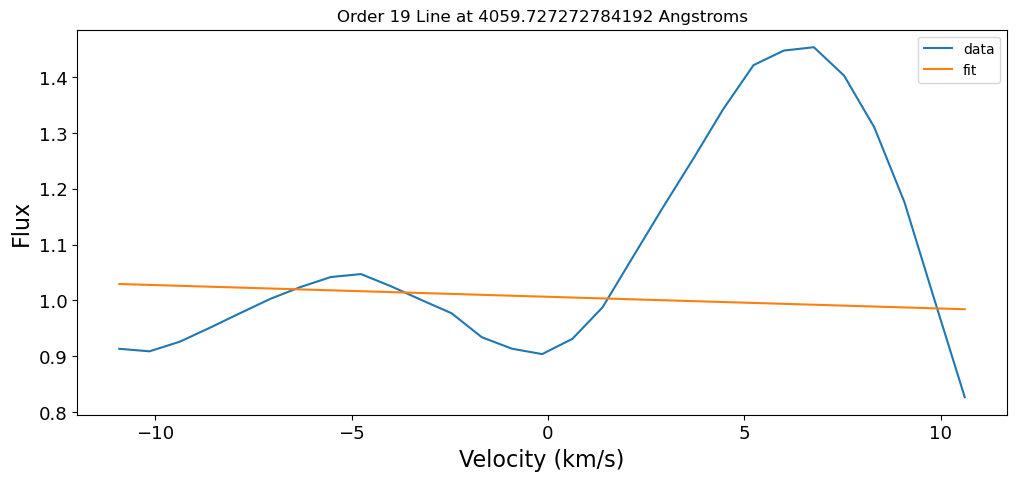

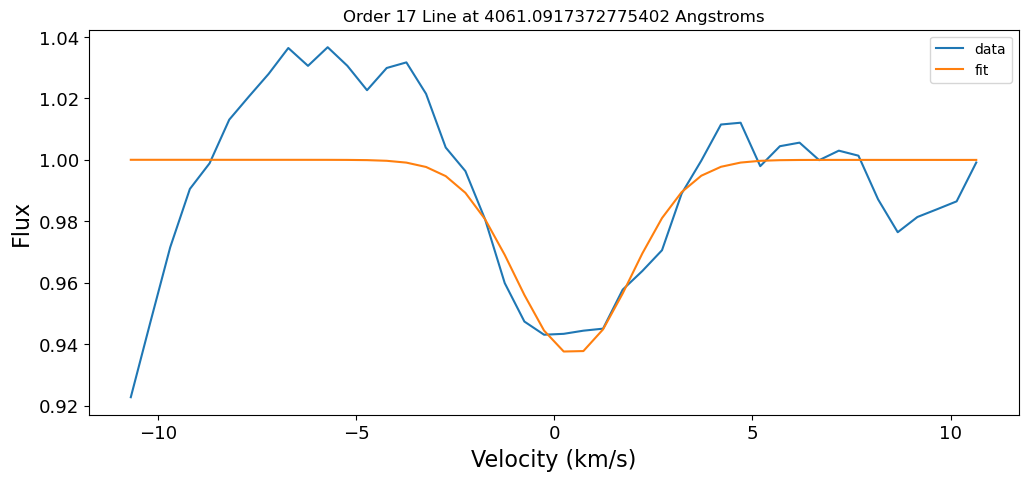

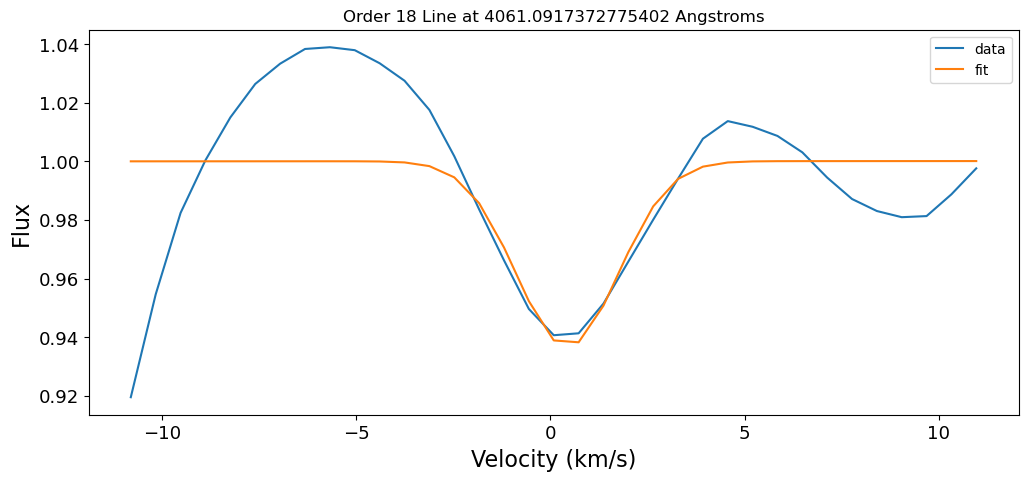

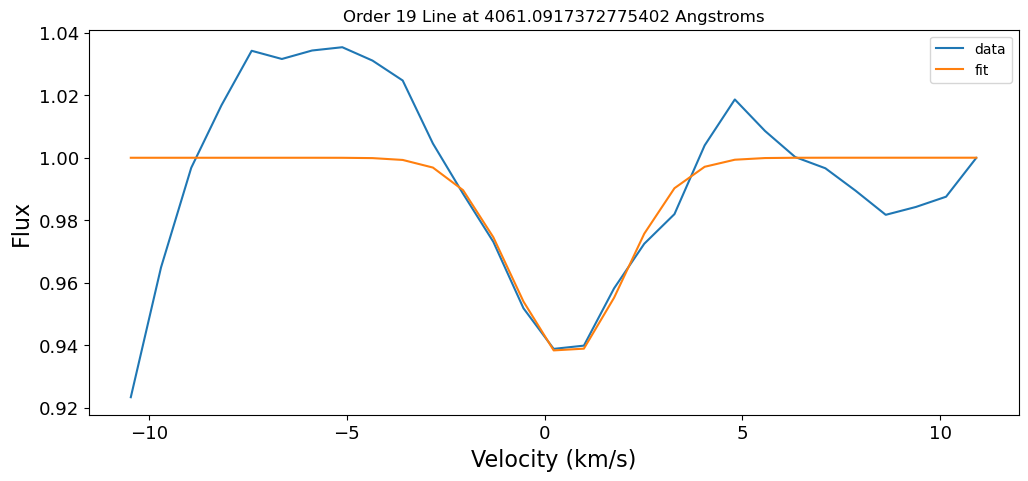

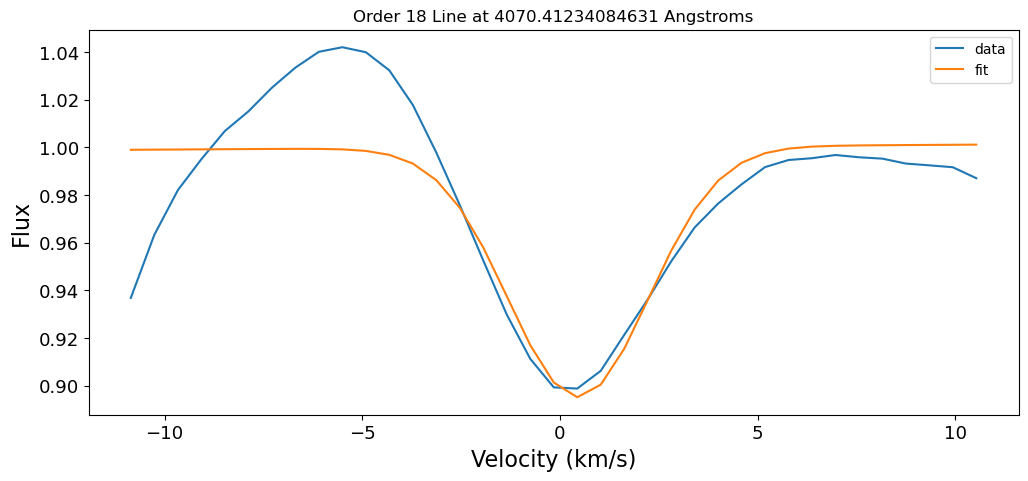

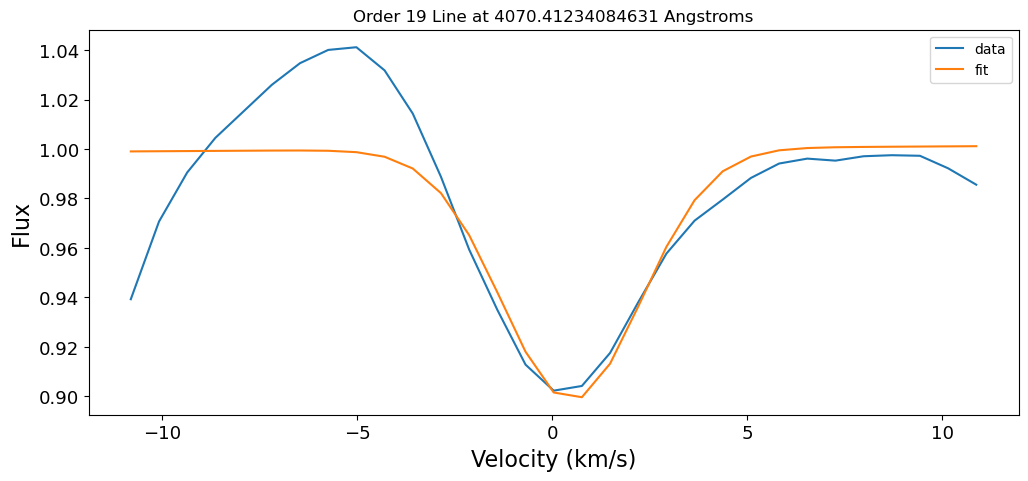

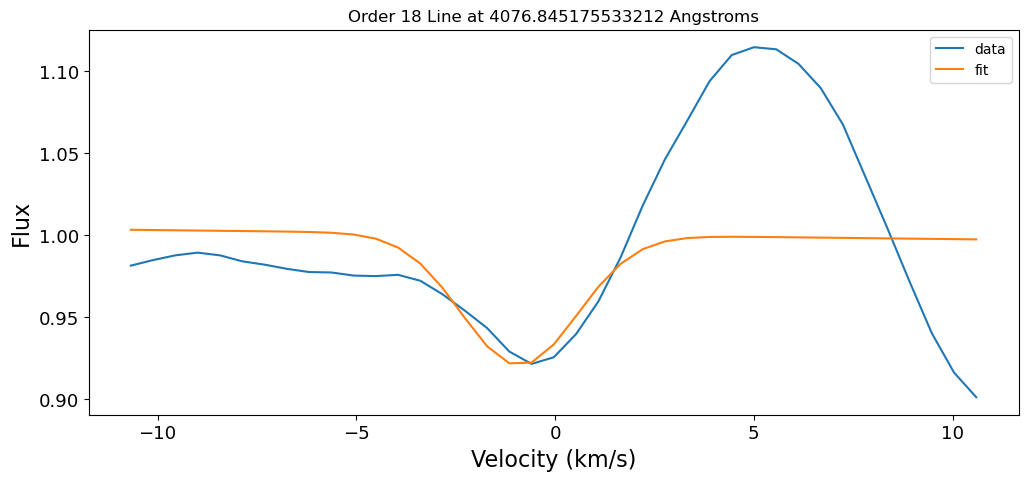

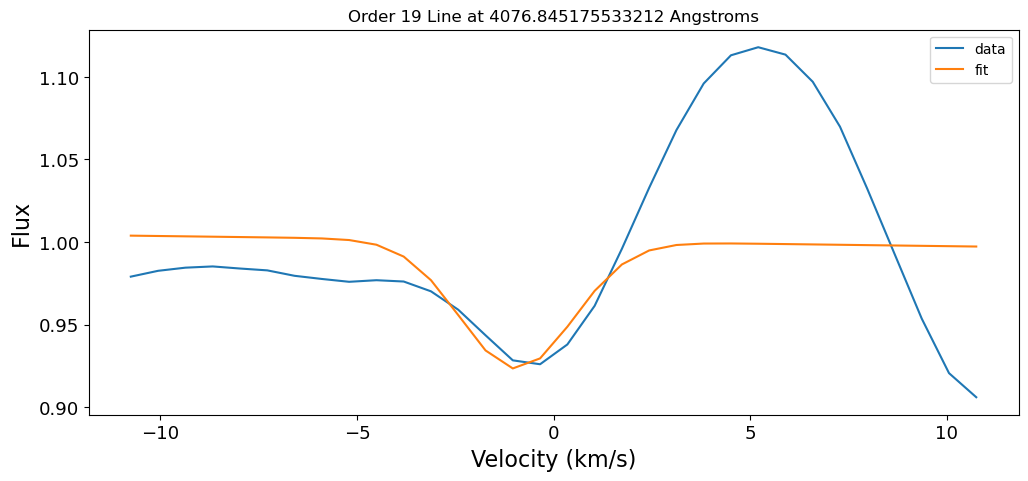

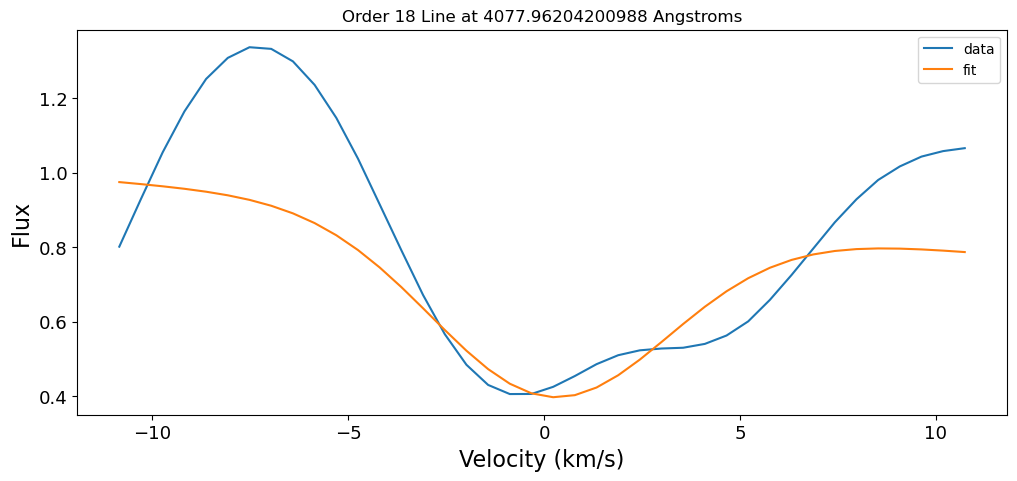

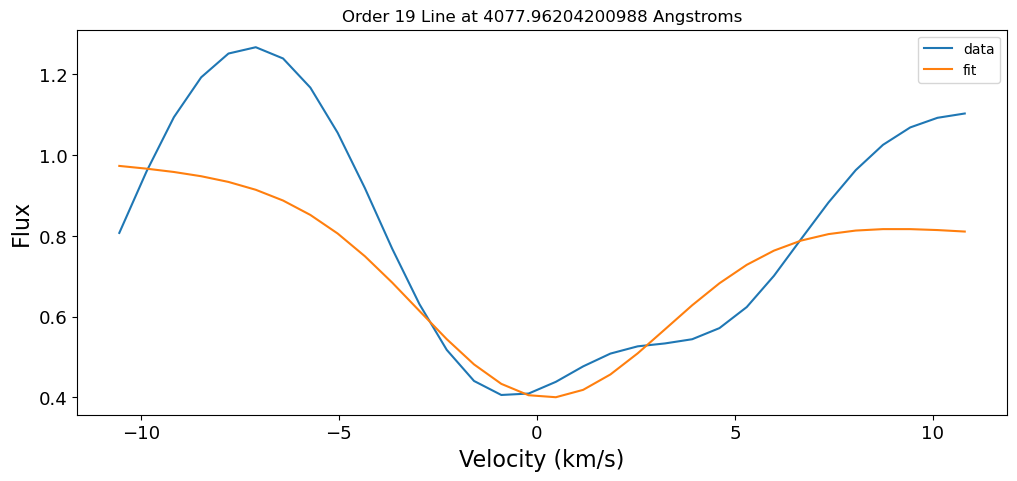

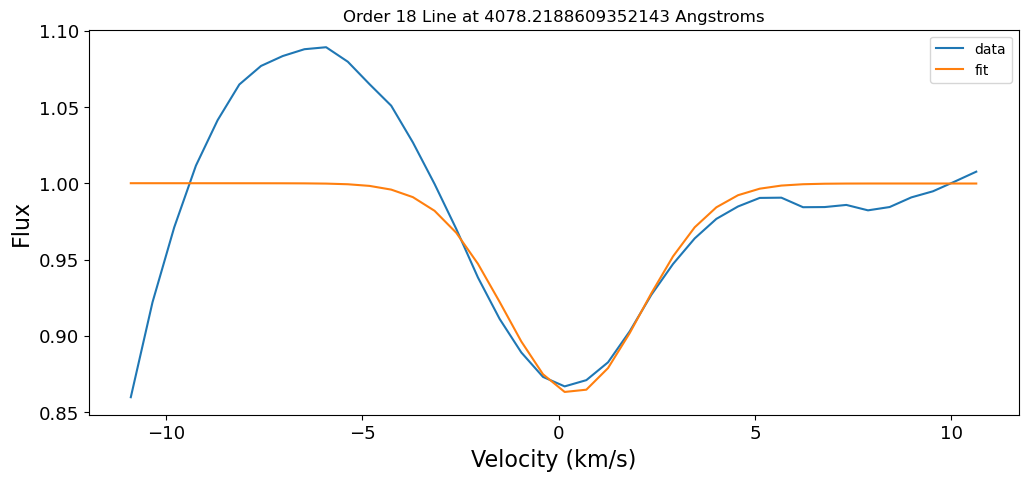

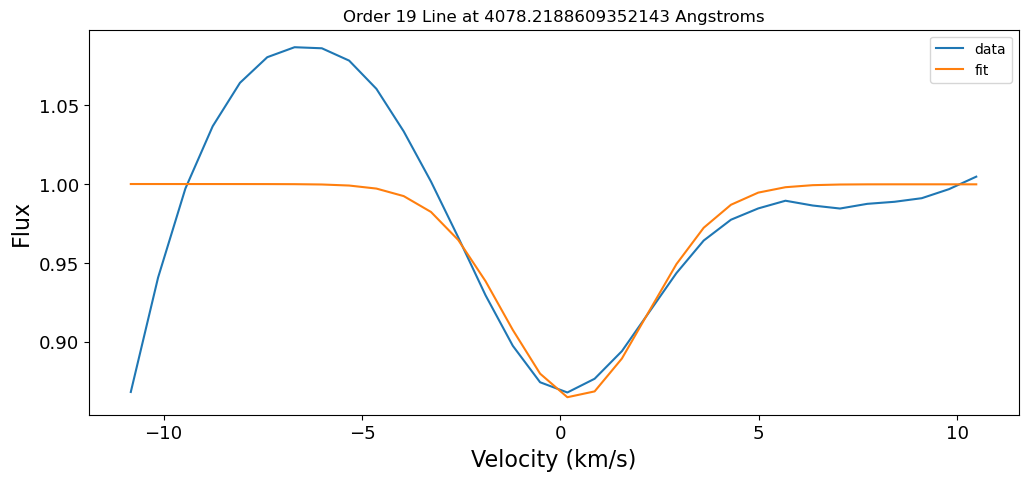

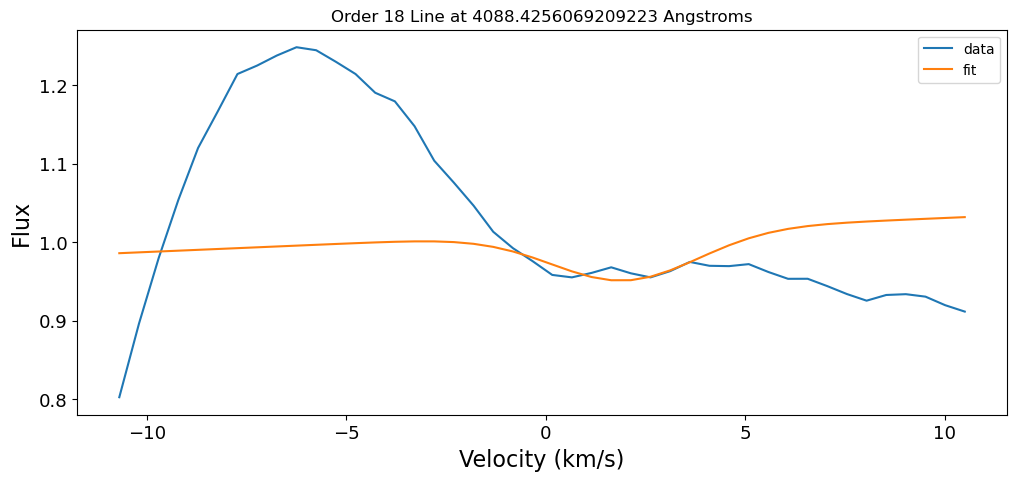

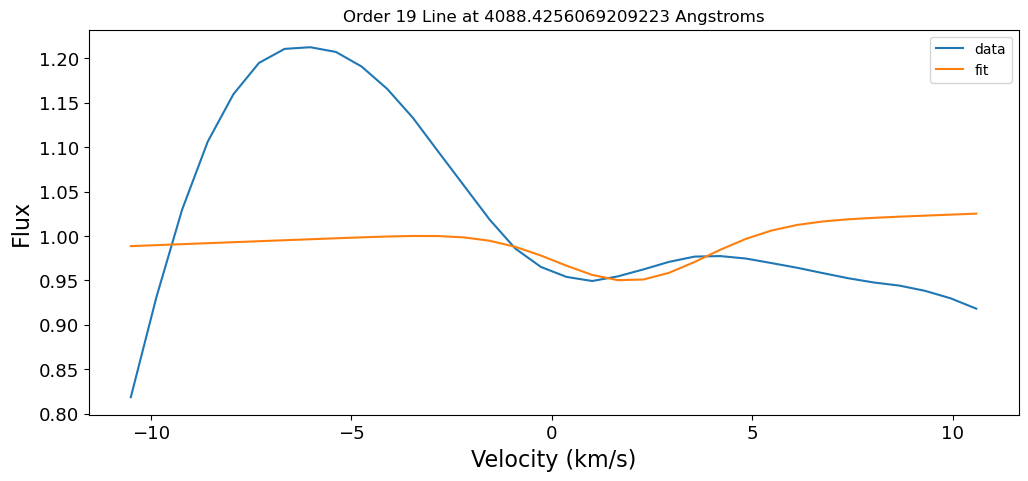

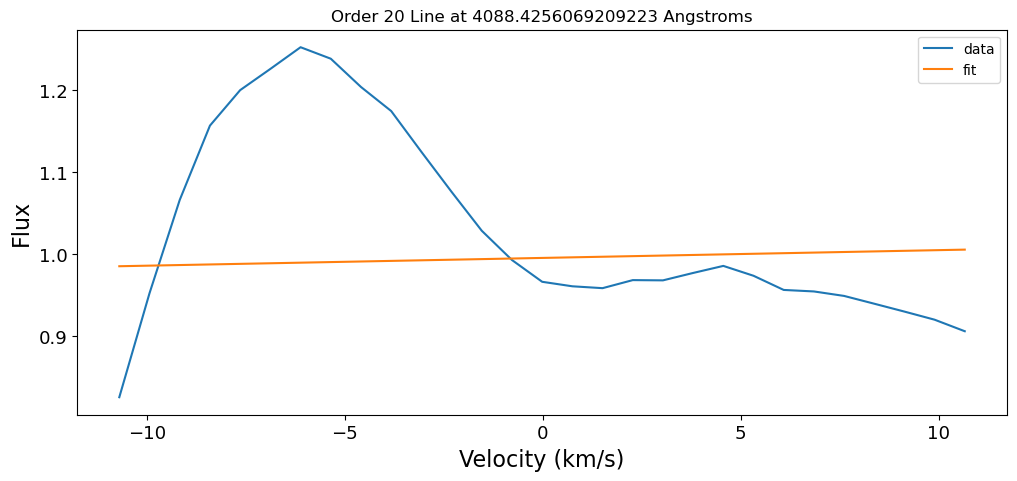

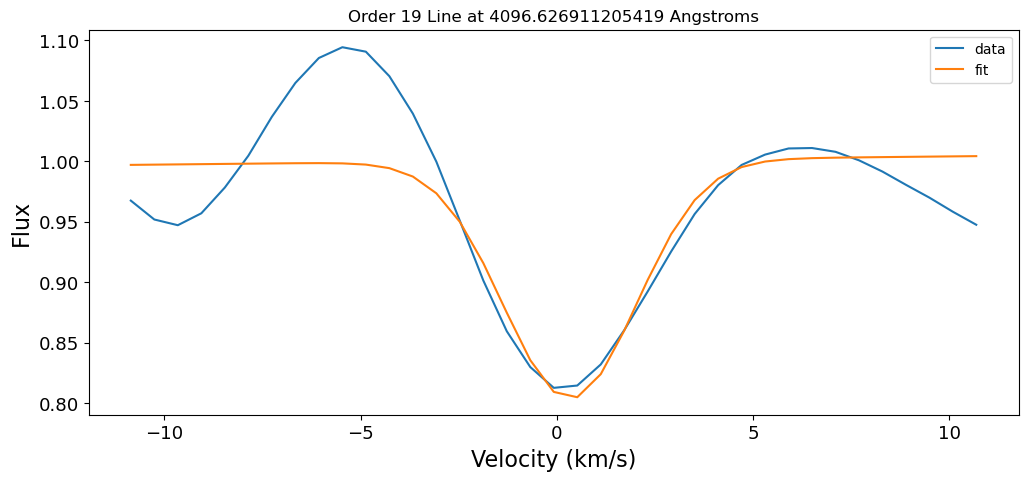

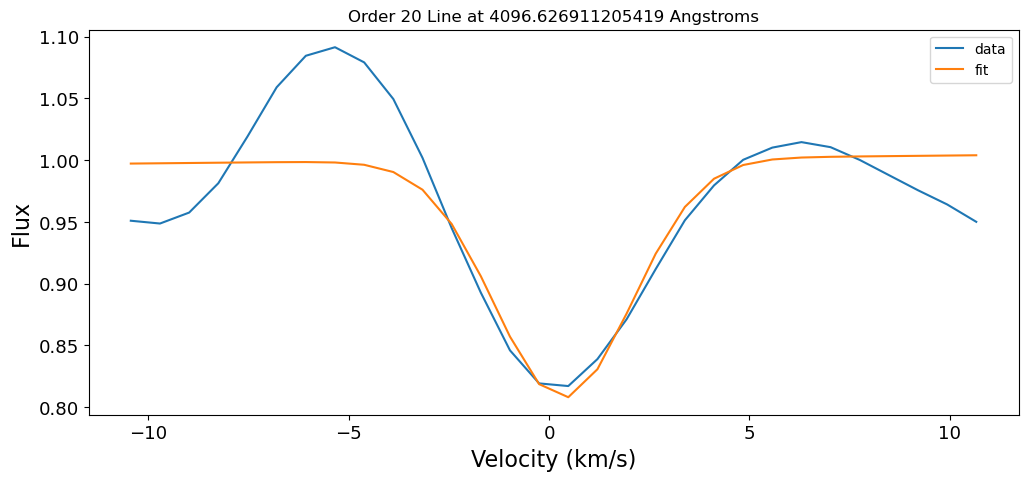

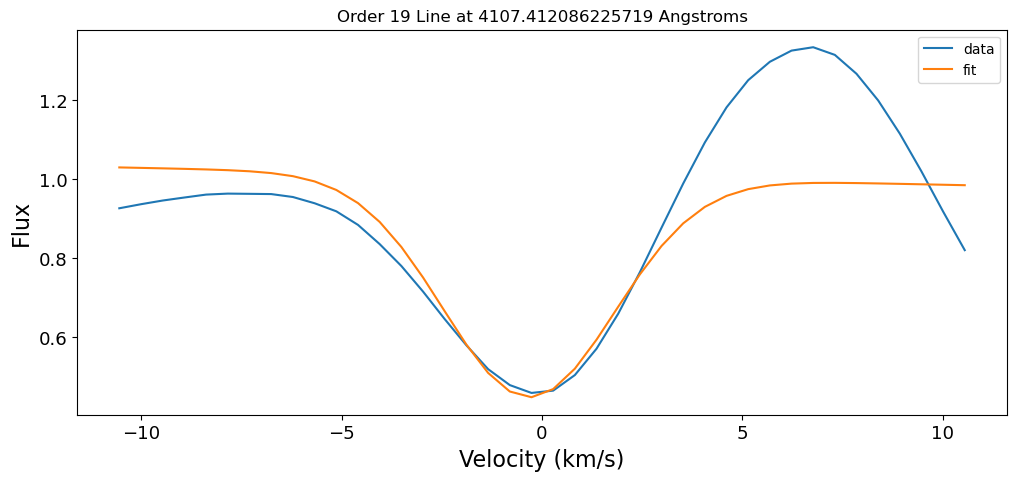

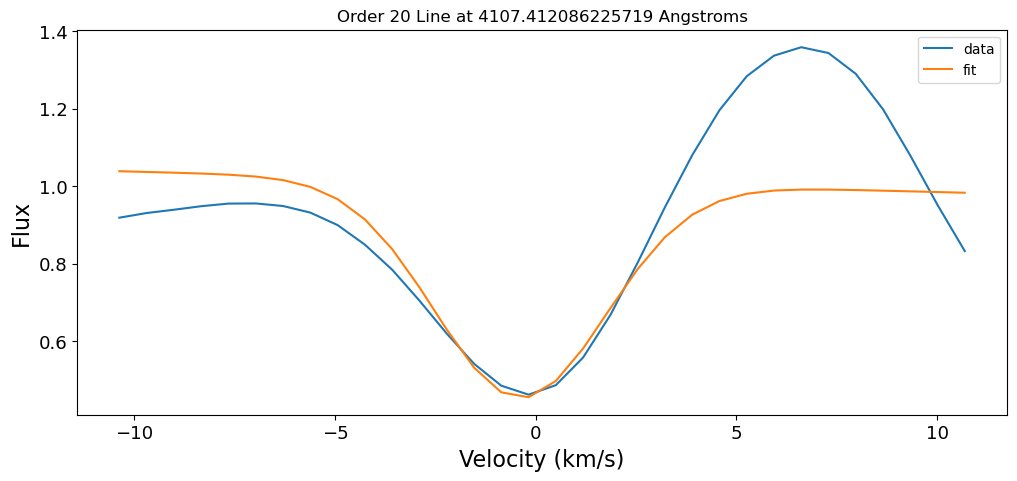

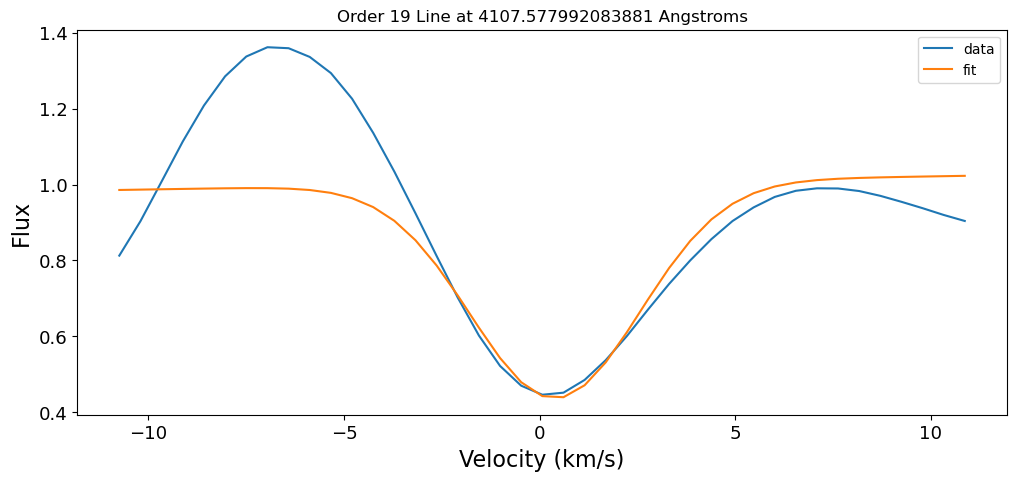

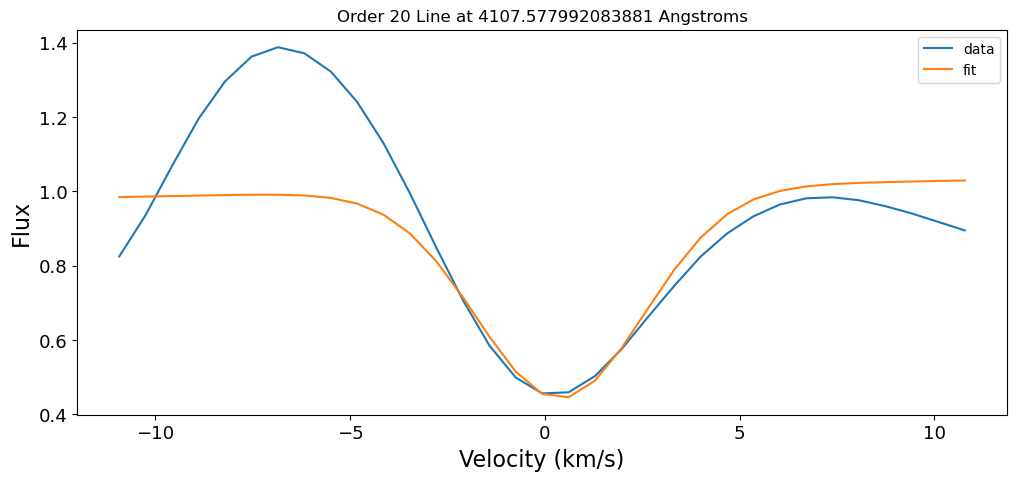

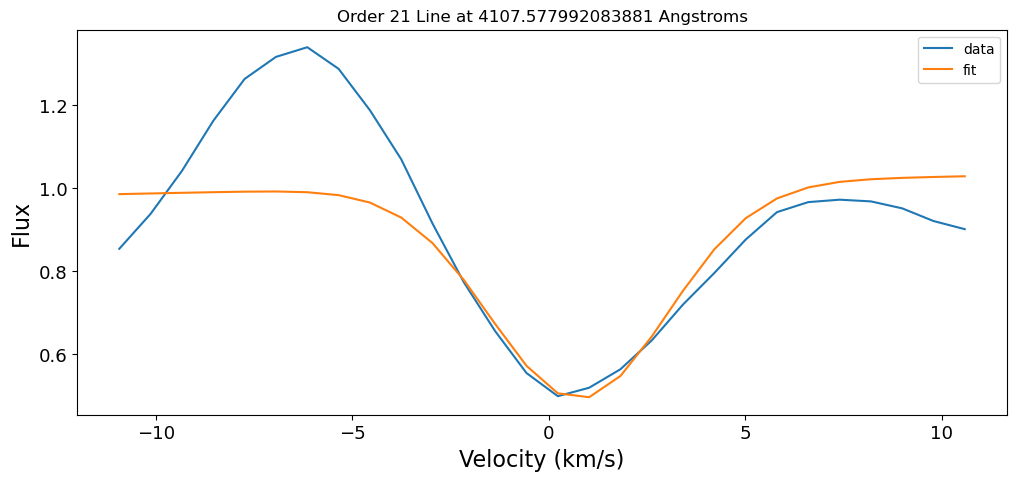

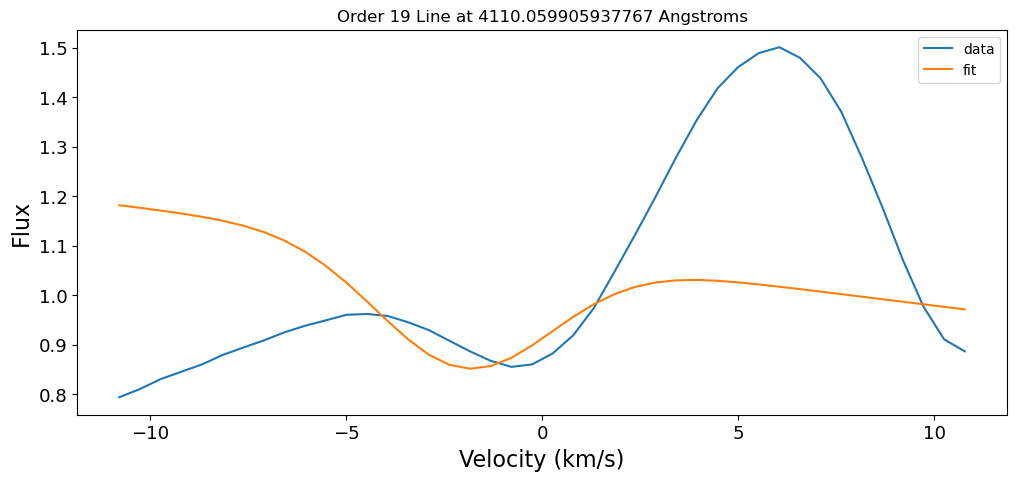

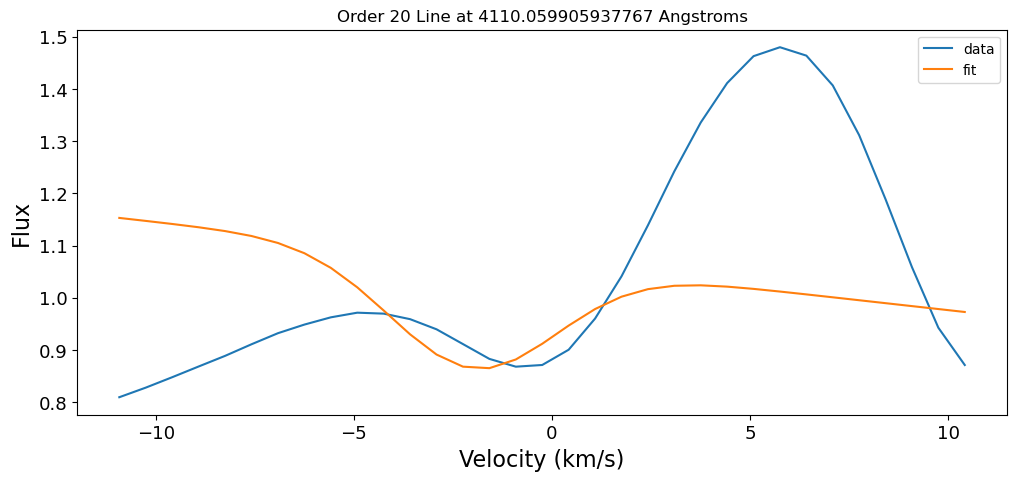

KeyboardInterrupt: 

In [24]:
fit_results=[]
#loop through the overlapping indices and fit lines to the NEID and EXPRES coadds
for i,idx in enumerate(neid_indices[:]):

    w_NEID=np.array(data['NEID']['wls'][idx])
    s_NEID=np.array(data['NEID']['coadds'][idx])
    e_NEID=np.array(data['NEID']['uncs'][idx])

    w_EXPRES=np.array(data['EXPRES']['wls'][idx])
    s_EXPRES=np.array(data['EXPRES']['coadds'][idx])
    e_EXPRES=np.array(data['EXPRES']['uncs'][idx])

    upper=np.min((np.max(w_NEID),np.max(w_EXPRES)))
    lower=np.max((np.min(w_NEID),np.min(w_EXPRES)))

    #find line fits in both spectra that are at least 500 pixels from the edge of at least one order
    lines_to_use={}

    cols_to_keep=['lambda','depth']
    for col in cols_to_keep:
        lines_to_use[col]=[]
    for row in line_list:
        l=row['lambda']
    
        if l<upper and l>lower:
            #find all the orders that contain this wavelength, and the line is more than 500 pixels from the edge of the order  
            #if line is not atleast 500 pixels from the edge of at least one order in both NEID and EXPRES, include it in lines_to_use
            neid_ok=False
            expres_ok=False
            for o in range(w_NEID.shape[0]):
                if l>w_NEID[o].min()+dist_from_edge*(w_NEID[o][1]-w_NEID[o][0]) and l<w_NEID[o].max()-dist_from_edge*(w_NEID[o][1]-w_NEID[o][0]):
                    neid_ok=True
            for o in range(w_EXPRES.shape[0]):
                if l>w_EXPRES[o].min()+dist_from_edge*(w_EXPRES[o][1]-w_EXPRES[o][0]) and l<w_EXPRES[o].max()-dist_from_edge*(w_EXPRES[o][1]-w_EXPRES[o][0]):
                    expres_ok=True
            if neid_ok and expres_ok:
                for col in cols_to_keep:
                    lines_to_use[col].append(row[col])
    lines_to_use=Table(lines_to_use)

    #print number of fitting lines for index idx
    #print(lines_to_use)
    print(f"Fitting {len(lines_to_use)} lines for index {idx} between {lower:.1f} and {upper:.1f} Angstroms")
    print("Now fitting for NEID...")
    line_fits_NEID=fit_lines(w_NEID,s_NEID,e_NEID,lines_to_use,plot=False,wl_min=lower,wl_max=upper,fit_range=0.15,dist_from_edge=500,plotbad=True)
    print("Now fitting for EXPRES...")
    line_fits_EXPRES=fit_lines(w_EXPRES,s_EXPRES,e_EXPRES,lines_to_use,plot=False,wl_min=lower,wl_max=upper,fit_range=0.15,dist_from_edge=500,plotbad=True)
    fit_results.append({'index':idx,'NEID_fits':line_fits_NEID,'EXPRES_fits':line_fits_EXPRES,'overlap_mid':overlap_mids[i]})
    #

In [37]:
def get_fit_results(data,neid_indices,line_list,fit_range,plot=False,plotbad=False,test=False,testnum=0,dist_from_edge=500):
    fit_results=[]
#loop through the overlapping indices and fit lines to the NEID and EXPRES coadds
    for i,idx in enumerate(neid_indices[testnum:]):
    
        w_NEID=np.array(data['NEID']['wls'][idx])
        s_NEID=np.array(data['NEID']['coadds'][idx])
        e_NEID=np.array(data['NEID']['uncs'][idx])
    
        w_EXPRES=np.array(data['EXPRES']['wls'][idx])
        s_EXPRES=np.array(data['EXPRES']['coadds'][idx])
        e_EXPRES=np.array(data['EXPRES']['uncs'][idx])
    
        upper=np.min((np.max(w_NEID),np.max(w_EXPRES)))
        lower=np.max((np.min(w_NEID),np.min(w_EXPRES)))
    
        #find line fits in both spectra that are at least 500 pixels from the edge of at least one order
        lines_to_use={}
    
        cols_to_keep=['lambda','depth']
        for col in cols_to_keep:
            lines_to_use[col]=[]
        for row in line_list:
            l=row['lambda']
        
            if l<upper and l>lower:
                #find all the orders that contain this wavelength, and the line is more than 500 pixels from the edge of the order  
                #if line is not atleast 500 pixels from the edge of at least one order in both NEID and EXPRES, include it in lines_to_use
                neid_ok=False
                expres_ok=False
                for o in range(w_NEID.shape[0]):
                    if l>w_NEID[o].min()+dist_from_edge*(w_NEID[o][1]-w_NEID[o][0]) and l<w_NEID[o].max()-dist_from_edge*(w_NEID[o][1]-w_NEID[o][0]):
                        neid_ok=True
                for o in range(w_EXPRES.shape[0]):
                    if l>w_EXPRES[o].min()+dist_from_edge*(w_EXPRES[o][1]-w_EXPRES[o][0]) and l<w_EXPRES[o].max()-dist_from_edge*(w_EXPRES[o][1]-w_EXPRES[o][0]):
                        expres_ok=True
                if neid_ok and expres_ok:
                    for col in cols_to_keep:
                        lines_to_use[col].append(row[col])
        lines_to_use=Table(lines_to_use)
    
        #print number of fitting lines for index idx
        #print(lines_to_use)
        print(f"Fitting {len(lines_to_use)} lines for index {idx} between {lower:.1f} and {upper:.1f} Angstroms")
        print("Now fitting for NEID...")
        line_fits_NEID=fit_lines(w_NEID,s_NEID,e_NEID,lines_to_use,plot=plot,wl_min=lower,wl_max=upper,fit_range=fit_range,dist_from_edge=dist_from_edge,plotbad=plotbad)
        if test==False:
            print("Now fitting for EXPRES...")
            line_fits_EXPRES=fit_lines(w_EXPRES,s_EXPRES,e_EXPRES,lines_to_use,plot=plot,wl_min=lower,wl_max=upper,fit_range=fit_range,dist_from_edge=dist_from_edge,plotbad=plotbad)
            fit_results.append({'index':idx,'NEID_fits':line_fits_NEID,'EXPRES_fits':line_fits_EXPRES,'overlap_mid':overlap_mids[i]})
            #
        else:
            fit_results.append(line_fits_NEID)
    return fit_results


In [45]:
fit_test_rangep15=get_fit_results(data,neid_indices,line_list,fit_range=.15, test=True,testnum=-1)
fit_test_rangep1=get_fit_results(data,neid_indices,line_list,fit_range=.1, test=True,testnum=-1)
fit_test_rangep15_dist800=get_fit_results(data,neid_indices,line_list,fit_range=.15, test=True,testnum=-1,dist_from_edge=800)

Fitting 1502 lines for index 0060 between 3796.6 and 8223.6 Angstroms
Now fitting for NEID...
Fit failed for line at 5305.646123979031 Angstroms in order 54
Fitting 1502 lines for index 0060 between 3796.6 and 8223.6 Angstroms
Now fitting for NEID...
Fit failed for line at 4960.569931481485 Angstroms in order 46


/opt/anaconda3/envs/astro/lib/python3.13/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,


Fit failed for line at 5305.646123979031 Angstroms in order 54
Fitting 1499 lines for index 0060 between 3796.6 and 8223.6 Angstroms
Now fitting for NEID...
Fit failed for line at 5305.646123979031 Angstroms in order 54


In [60]:
fit_test_rangep05=get_fit_results(data,neid_indices,line_list,fit_range=.05, test=True,testnum=-1)

Fitting 1502 lines for index 0060 between 3796.6 and 8223.6 Angstroms
Now fitting for NEID...
Fit failed for line at 4587.506137264652 Angstroms in order 36


/opt/anaconda3/envs/astro/lib/python3.13/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,


Fit failed for line at 4960.569931481485 Angstroms in order 46
Fit failed for line at 5305.646123979031 Angstroms in order 54


In [55]:
fit_test_rangep15_dist400=get_fit_results(data,neid_indices,line_list,fit_range=.15, test=True,testnum=-1,dist_from_edge=400)
fit_test_rangep15_dist300=get_fit_results(data,neid_indices,line_list,fit_range=.15, test=True,testnum=-1,dist_from_edge=300)
fit_test_rangep15_dist200=get_fit_results(data,neid_indices,line_list,fit_range=.15, test=True,testnum=-1,dist_from_edge=200)

Fitting 1504 lines for index 0060 between 3796.6 and 8223.6 Angstroms
Now fitting for NEID...
Fit failed for line at 5305.646123979031 Angstroms in order 54
Fitting 1504 lines for index 0060 between 3796.6 and 8223.6 Angstroms
Now fitting for NEID...
Fit failed for line at 5305.646123979031 Angstroms in order 54
Fitting 1504 lines for index 0060 between 3796.6 and 8223.6 Angstroms
Now fitting for NEID...
Fit failed for line at 5305.646123979031 Angstroms in order 54


In [52]:
fit_test_rangep7=get_fit_results(data,neid_indices,line_list,fit_range=.7, test=True,testnum=-1)

Fitting 1502 lines for index 0060 between 3796.6 and 8223.6 Angstroms
Now fitting for NEID...


In [48]:
bins=np.arange(201)/100-1
bins

array([-1.  , -0.99, -0.98, -0.97, -0.96, -0.95, -0.94, -0.93, -0.92,
       -0.91, -0.9 , -0.89, -0.88, -0.87, -0.86, -0.85, -0.84, -0.83,
       -0.82, -0.81, -0.8 , -0.79, -0.78, -0.77, -0.76, -0.75, -0.74,
       -0.73, -0.72, -0.71, -0.7 , -0.69, -0.68, -0.67, -0.66, -0.65,
       -0.64, -0.63, -0.62, -0.61, -0.6 , -0.59, -0.58, -0.57, -0.56,
       -0.55, -0.54, -0.53, -0.52, -0.51, -0.5 , -0.49, -0.48, -0.47,
       -0.46, -0.45, -0.44, -0.43, -0.42, -0.41, -0.4 , -0.39, -0.38,
       -0.37, -0.36, -0.35, -0.34, -0.33, -0.32, -0.31, -0.3 , -0.29,
       -0.28, -0.27, -0.26, -0.25, -0.24, -0.23, -0.22, -0.21, -0.2 ,
       -0.19, -0.18, -0.17, -0.16, -0.15, -0.14, -0.13, -0.12, -0.11,
       -0.1 , -0.09, -0.08, -0.07, -0.06, -0.05, -0.04, -0.03, -0.02,
       -0.01,  0.  ,  0.01,  0.02,  0.03,  0.04,  0.05,  0.06,  0.07,
        0.08,  0.09,  0.1 ,  0.11,  0.12,  0.13,  0.14,  0.15,  0.16,
        0.17,  0.18,  0.19,  0.2 ,  0.21,  0.22,  0.23,  0.24,  0.25,
        0.26,  0.27,

(0.0, 1.0)

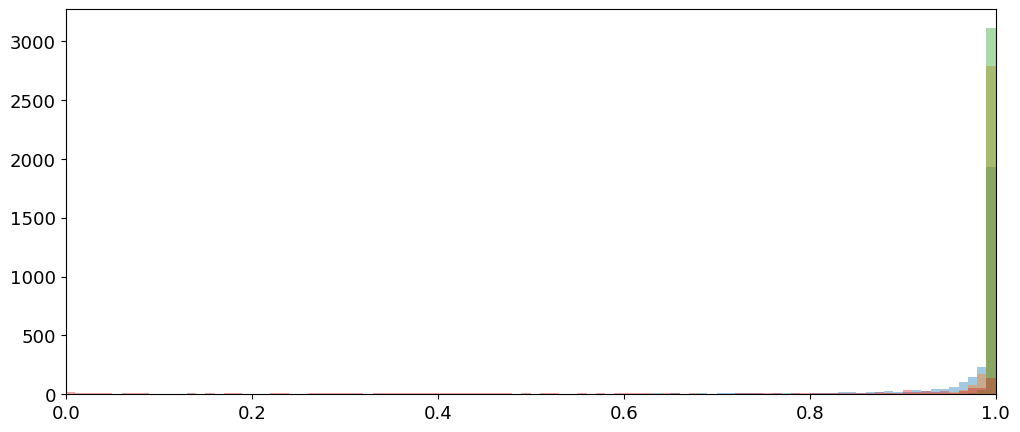

In [61]:

rs=[item['r'] for item in fit_test_rangep15[0]]
rs_p1=[item['r'] for item in fit_test_rangep1[0]]
rs_p05=[item['r'] for item in fit_test_rangep05[0]]
rs_p7=[item['r'] for item in fit_test_rangep7[0]]
rs_e800=[item['r'] for item in fit_test_rangep15_dist800[0]]
rs_e400=[item['r'] for item in fit_test_rangep15_dist400[0]]
rs_e300=[item['r'] for item in fit_test_rangep15_dist300[0]]
rs_e200=[item['r'] for item in fit_test_rangep15_dist200[0]]
plt.hist(rs,alpha=.4,bins=bins)
plt.hist(rs_p1,alpha=.4,bins=bins)
plt.hist(rs_p05,alpha=.4,bins=bins)
plt.hist(rs_p7,alpha=.4,bins=bins)
#plt.hist(rs_e800,alpha=.4,bins=bins)
plt.xlim(0,1)

(0.0, 1.0)

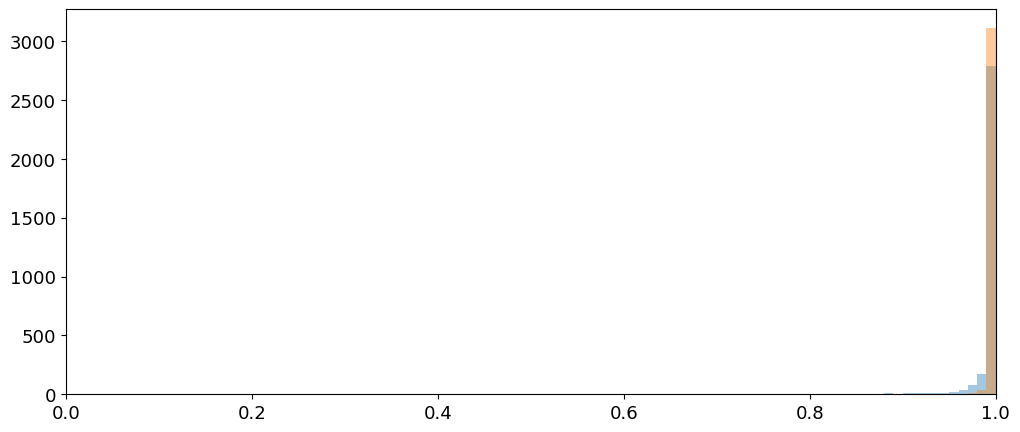

In [62]:

rs=[item['r'] for item in fit_test_rangep15[0]]
rs_p1=[item['r'] for item in fit_test_rangep1[0]]
rs_p05=[item['r'] for item in fit_test_rangep05[0]]
rs_p7=[item['r'] for item in fit_test_rangep7[0]]
rs_e800=[item['r'] for item in fit_test_rangep15_dist800[0]]
rs_e400=[item['r'] for item in fit_test_rangep15_dist400[0]]
rs_e300=[item['r'] for item in fit_test_rangep15_dist300[0]]
rs_e200=[item['r'] for item in fit_test_rangep15_dist200[0]]
#plt.hist(rs,alpha=.4,bins=bins)
plt.hist(rs_p1,alpha=.4,bins=bins)
plt.hist(rs_p05,alpha=.4,bins=bins)
#plt.hist(rs_p7,alpha=.4,bins=bins)
#plt.hist(rs_e800,alpha=.4,bins=bins)
plt.xlim(0,1)

(0.0, 1.0)

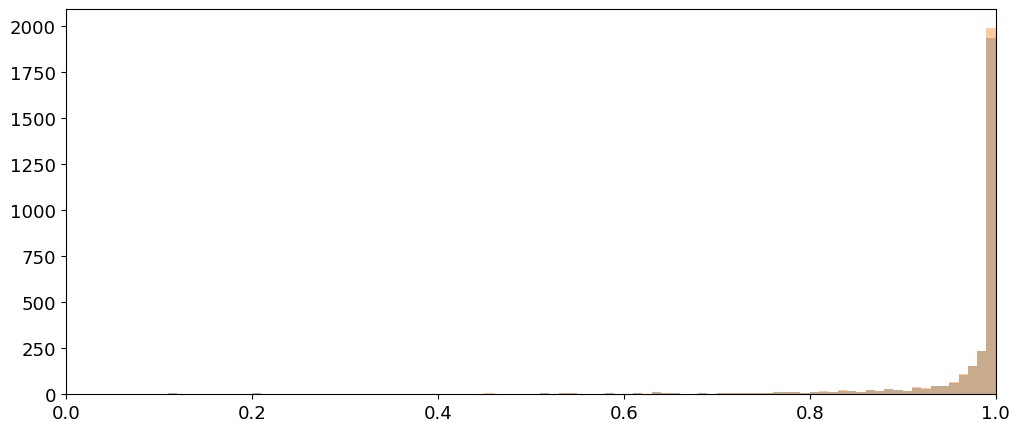

In [58]:

rs=[item['r'] for item in fit_test_rangep15[0]]
rs_p1=[item['r'] for item in fit_test_rangep1[0]]
rs_p7=[item['r'] for item in fit_test_rangep7[0]]
rs_e800=[item['r'] for item in fit_test_rangep15_dist800[0]]
plt.hist(rs,alpha=.4,bins=bins)
#plt.hist(rs_p1,alpha=.4,bins=bins)
#plt.hist(rs_p7,alpha=.4,bins=bins)
#plt.hist(rs_e800,alpha=.4,bins=bins)
plt.hist(rs_e400,alpha=.4,bins=bins)
#plt.hist(rs_e300,alpha=.4,bins=bins)
#plt.hist(rs_e200,alpha=.4,bins=bins)
plt.xlim(0,1)

(0.0, 1.0)

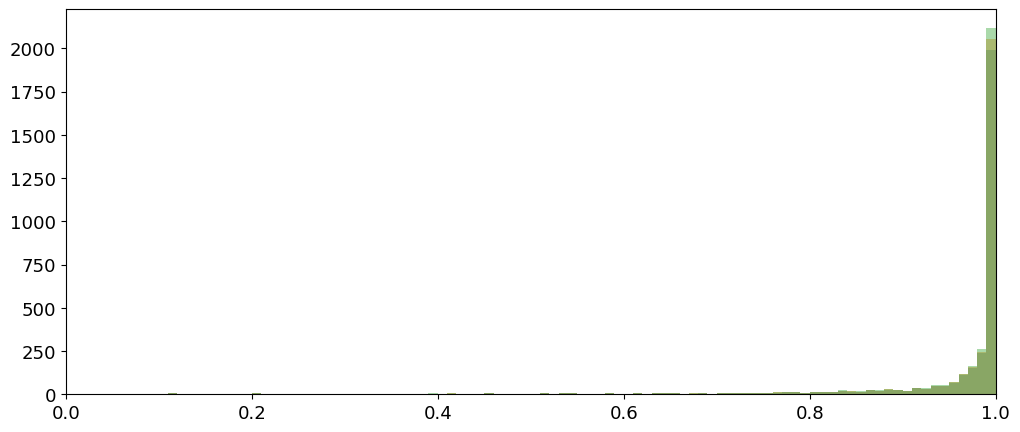

In [59]:

rs=[item['r'] for item in fit_test_rangep15[0]]
rs_p1=[item['r'] for item in fit_test_rangep1[0]]
rs_p7=[item['r'] for item in fit_test_rangep7[0]]
rs_e800=[item['r'] for item in fit_test_rangep15_dist800[0]]
#plt.hist(rs,alpha=.4,bins=bins)
#plt.hist(rs_p1,alpha=.4,bins=bins)
#plt.hist(rs_p7,alpha=.4,bins=bins)
#plt.hist(rs_e800,alpha=.4,bins=bins)
plt.hist(rs_e400,alpha=.4,bins=bins)
plt.hist(rs_e300,alpha=.4,bins=bins)
plt.hist(rs_e200,alpha=.4,bins=bins)
plt.xlim(0,1)

In [ ]:
fit_results=get_fit_results(data,neid_indices,line_list,fit_range=0.1,dis)

In [ ]:
#save fit results to pickele file

with open('line_fit_results_neid_expres_overlap_2024_w_werr.pkl','wb') as f:
    pickle.dump(fit_results,f)